# Trực quan hóa và phân tích dữ liệu lỗi bề mặt thép


- **Bước 1:** mục tiêu, phạm vi, câu hỏi Q0–Q6, tiêu chí đánh giá và hướng sử dụng.
- **Bước 2:** mô tả CSV/Excel đã tải; mã API chia theo từng thao tác.
- **Bước 3:** làm sạch có nhật ký, đối chiếu từng biến và nhãn với UCI.
- **Bước 4:** tạo biến, chỉ số và bảng tổng hợp.
- **Bước 5:** 9 biểu đồ, câu trả lời Q0–Q6, mức độ chắc chắn A/B/C và kế hoạch kiểm chứng.
- **Bước 6:** thuyết minh dashboard Streamlit/Plotly, đối chiếu dữ liệu và kiểm tra KPI.



## Chuẩn bị thư viện


In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import json
import time

import pandas as pd
import requests
from IPython.display import display

THU_MUC_DU_AN = Path.cwd()
REPORT_DIR = THU_MUC_DU_AN / "outputs" / "buoc_1_2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)


# Chương 1. Xác định yêu cầu

## 1.1. Lý do chọn đề tài và người sử dụng kết quả

Dữ liệu lỗi bề mặt thép ghi nhận vị trí, kích thước, độ sáng và nhãn của từng bản ghi lỗi.
Bảng số liệu giúp tra cứu nhưng khó cho thấy cơ cấu nhãn, vùng độ sáng hoặc khác biệt
về độ dày giữa các nhóm. Trực quan hóa hỗ trợ người đọc nhận ra những khuôn phân bố
và lựa chọn nội dung cần kiểm chứng tiếp theo.

Người sử dụng kết quả là người phân tích dữ liệu và bộ phận kiểm tra chất lượng (QC).
Notebook hỗ trợ ba việc: kiểm tra đầu vào có đáng tin cậy, mô tả các nhóm lỗi,
và xác định bằng chứng còn thiếu trước khi đưa ra quyết định sản xuất.

Bộ **Steel Plates Faults** của UCI là nguồn đối chiếu. Excel thực hành kèm tài liệu
là đầu vào có những vấn đề được đưa vào để luyện làm sạch; các vấn đề này không đại diện
cho chất lượng thu thập tại một nhà máy thật. Bài làm thực hiện quy trình bằng Python
để người khác chạy lại và truy được căn cứ của từng lần xử lý.

UN Comtrade bổ sung bối cảnh thương mại sắt thép Việt Nam ở cấp quốc gia.
UCI không xác nhận nhà máy thuộc Việt Nam và hai nguồn không có khóa liên hệ.

## 1.2. Mục tiêu và phạm vi sản phẩm

1. Thu thập và lưu nguồn; làm sạch có nhật ký; xác minh đặc trưng và nhãn với UCI.
2. Mô tả cơ cấu lỗi và liên hệ trong mẫu với dòng thép, độ sáng, độ dày và diện tích.
3. Vẽ biểu đồ trả lời từng câu hỏi, kèm mẫu số, cỡ mẫu, số liệu và giới hạn diễn giải.
4. Chuyển phát hiện thành ưu tiên kiểm chứng, chỉ rõ dữ liệu cần bổ sung và điều kiện hoàn tất.

Notebook này thực hiện bước 1–6. Dashboard tương tác chạy bằng ứng dụng ở bước 6;
các ưu tiên hiện trường ở cuối bước 5 là đề xuất, chưa phải hoạt động đã thực hiện.

## 1.3. Câu hỏi phân tích, tiêu chí đánh giá và hướng sử dụng

Q0–Q6 giữ mã của kế hoạch: Q5 là diện tích, Q6 là thương mại bổ sung.
Q5 của PDF hỏi ưu tiên kiểm chứng; nội dung đó được thực hiện ở mục 5.8,
dùng tổng hợp bằng chứng của các câu hỏi trước.

Theo PDF mục V.3 (trang 20), mỗi câu hỏi cần có dữ liệu để trả lời,
tiêu chí đánh giá và hướng hành động thay đổi theo kết quả.
Bảng đầu ghi nguồn, biến và đầu ra; bảng tiếp theo ghi tiêu chí và cách sử dụng.

**Lưu ý phương pháp:** tiêu chí dưới đây được bổ sung khi sửa notebook sau khi đã xem kết quả.
Mức 90% của Q2 lấy từ PDF; các tiêu chí IQR và thống kê nhóm phục vụ mô tả, khám phá.
Chúng không phải giả thuyết đăng ký trước hoặc kiểm định trên dữ liệu độc lập.
Khi đánh giá quy tắc dự báo về sau, phải chốt tiêu chí và tách tập kiểm tra trước khi chọn ngưỡng.

In [2]:
# Mốc tham khảo của PDF V.3; dùng tỷ trọng trong từng nhãn, đơn vị %.
NGUONG_TAP_TRUNG_PHAN_TRAM = 90.0

questions = pd.DataFrame([
    ["Q0", "Dữ liệu có đủ tin cậy để phân tích không?", "Excel thực hành và UCI",
     "27 đặc trưng, nhãn, tọa độ", "Kiểm tra thiếu, trùng, logic và đối chiếu",
     "Bảng chất lượng, nhật ký và đối chiếu", "Bước 3; tổng hợp bước 5"],
    ["Q1", "Bảy loại lỗi phân bố như thế nào?", "Lỗi thép sạch",
     "Fault_Type_Clean", "Số đếm, tỷ trọng và lũy kế",
     "Thanh ngang, Pareto và bảng cơ cấu", "Bước 4–5"],
    ["Q2", "Nhãn nào tập trung trên một dòng thép; cơ cấu hai dòng khác nhau ra sao?", "Lỗi thép sạch",
     "Nhãn và hai cờ dòng thép", "Bảng chéo; tỷ trọng trong từng nhãn và dòng thép",
     "Cột nhóm, cột chồng 100% và bảng tập trung", "Bước 4–5"],
    ["Q3", "Độ sáng cho thấy dấu hiệu phân tách nhãn nào?", "Lỗi thép sạch",
     "Minimum_of_Luminosity, Maximum_of_Luminosity, nhãn", "Scatter, Pearson và IQR theo nhãn",
     "Scatter và bảng dấu hiệu phân tách", "Bước 4–5"],
    ["Q4", "Độ dày khác nhau thế nào theo nhãn và dòng thép?", "Lỗi thép sạch",
     "Steel_Plate_Thickness, nhãn, dòng thép", "N, trung vị, IQR và độ lệch chuẩn mẫu",
     "Boxplot và bảng nhãn × dòng thép", "Bước 4–5"],
    ["Q5", "Diện tích khác nhau thế nào giữa các loại lỗi?", "Lỗi thép sạch",
     "Pixels_Areas, nhãn", "N, trung vị, IQR và cờ diện tích",
     "Boxplot diện tích trên trục log", "Bước 4–5"],
    ["Q6", "Xuất nhập khẩu sắt thép Việt Nam thay đổi thế nào qua các năm?", "UN Comtrade",
     "Year, flowCode, primaryValue, classificationCode", "Trị giá, tăng trưởng và chênh lệch",
     "Đường thương mại và cột chênh lệch", "Bước 4–5"],
], columns=["Mã", "Câu hỏi", "Nguồn", "Biến cần dùng", "Phương pháp", "Đầu ra", "Thực hiện ở"])

display(questions)
questions.to_csv(REPORT_DIR / "cau_hoi_phan_tich.csv", index=False, encoding="utf-8-sig")

,Mã,Câu hỏi,Nguồn,Biến cần dùng,Phương pháp,Đầu ra,Thực hiện ở
0,Q0,Dữ liệu có đủ tin cậy để phân tích không?,Excel thực hành và UCI,"27 đặc trưng, nhãn, tọa độ","Kiểm tra thiếu, trùng, logic và đối chiếu","Bảng chất lượng, nhật ký và đối chiếu",Bước 3; tổng hợp bước 5
1,Q1,Bảy loại lỗi phân bố như thế nào?,Lỗi thép sạch,Fault_Type_Clean,"Số đếm, tỷ trọng và lũy kế","Thanh ngang, Pareto và bảng cơ cấu",Bước 4–5
2,Q2,Nhãn nào tập trung trên một dòng thép; cơ cấu ...,Lỗi thép sạch,Nhãn và hai cờ dòng thép,Bảng chéo; tỷ trọng trong từng nhãn và dòng thép,"Cột nhóm, cột chồng 100% và bảng tập trung",Bước 4–5
3,Q3,Độ sáng cho thấy dấu hiệu phân tách nhãn nào?,Lỗi thép sạch,"Minimum_of_Luminosity, Maximum_of_Luminosity, ...","Scatter, Pearson và IQR theo nhãn",Scatter và bảng dấu hiệu phân tách,Bước 4–5
4,Q4,Độ dày khác nhau thế nào theo nhãn và dòng thép?,Lỗi thép sạch,"Steel_Plate_Thickness, nhãn, dòng thép","N, trung vị, IQR và độ lệch chuẩn mẫu",Boxplot và bảng nhãn × dòng thép,Bước 4–5
5,Q5,Diện tích khác nhau thế nào giữa các loại lỗi?,Lỗi thép sạch,"Pixels_Areas, nhãn","N, trung vị, IQR và cờ diện tích",Boxplot diện tích trên trục log,Bước 4–5
6,Q6,Xuất nhập khẩu sắt thép Việt Nam thay đổi thế ...,UN Comtrade,"Year, flowCode, primaryValue, classificationCode","Trị giá, tăng trưởng và chênh lệch",Đường thương mại và cột chênh lệch,Bước 4–5


### Tiêu chí đánh giá và việc làm theo kết quả

Q0 là điều kiện chuyển sang phân tích. Q1–Q6 là câu hỏi mô tả và khám phá;
khác biệt thống kê trong bảng chưa chứng minh khác biệt rủi ro hoặc nguyên nhân.
IQR không chồng lấn chỉ nói về 50% trung tâm, không bảo đảm toàn bộ điểm tách nhau.

In [3]:
tieu_chi_cau_hoi = pd.DataFrame([
    ["Q0", "Không thiếu đặc trưng; khóa duy nhất; nhãn và 27 biến có 0 ô lệch UCI; logic đạt",
     "Đạt: phân tích; chưa đạt: xử lý và kiểm tra lại trước khi xuất bảng"],
    ["Q1", "Đọc thứ hạng, tỷ trọng ba nhãn đầu, lũy kế 80% và tỷ số cỡ mẫu lớn nhất/nhỏ nhất",
     "Mất cân bằng: giữ cỡ mẫu, kiểm tra nhãn gộp; nếu mô hình hóa sau này dùng F1 từng lớp/macro"],
    ["Q2", f"Tập trung khi trên {NGUONG_TAP_TRUNG_PHAN_TRAM:.0f}% bản ghi của một nhãn nằm ở cùng một dòng thép",
     "Vượt mốc: kiểm chứng riêng tổ hợp nhãn–dòng thép; không vượt: khảo sát cả hai dòng"],
    ["Q3", "IQR của Min không chồng lấn với mọi nhãn khác là dấu hiệu phân tách trung tâm; xem cả scatter và Max",
     "Có dấu hiệu: ưu tiên đặc trưng để kiểm chứng độc lập; còn chồng lấn: cần thêm đặc trưng"],
    ["Q4", "So sánh N, trung vị, IQR, SD theo nhãn và dòng thép; N=1 chỉ mô tả bản ghi",
     "Có tập trung: kiểm tra tổ hợp dòng thép–độ dày; chồng lấn: giữ nhiều chiều khi mô tả"],
    ["Q5", "So sánh trung vị, IQR và điểm cực đoan; trục log chỉ đổi hiển thị; giữ bản ghi khớp nguồn",
     "Khác biệt quy mô: khảo sát kích thước và nhãn; chồng lấn: diện tích đơn lẻ chưa đủ"],
    ["Q6", "Dấu xuất−nhập so với 0; cực trị và tăng trưởng từng năm đủ dữ liệu; đánh dấu đổi HS",
     "Đọc chiều biến động; khi HS thay đổi phải đối chiếu phân loại trước khi giải thích"],
], columns=["Cau_hoi", "Tieu_chi_danh_gia", "Huong_su_dung_ket_qua"])

display(tieu_chi_cau_hoi)
assert set(tieu_chi_cau_hoi["Cau_hoi"]) == set(questions["Mã"])
tieu_chi_cau_hoi.to_csv(REPORT_DIR / "tieu_chi_cau_hoi.csv", index=False, encoding="utf-8-sig")

,Cau_hoi,Tieu_chi_danh_gia,Huong_su_dung_ket_qua
0,Q0,Không thiếu đặc trưng; khóa duy nhất; nhãn và ...,Đạt: phân tích; chưa đạt: xử lý và kiểm tra lạ...
1,Q1,"Đọc thứ hạng, tỷ trọng ba nhãn đầu, lũy kế 80%...","Mất cân bằng: giữ cỡ mẫu, kiểm tra nhãn gộp; n..."
2,Q2,Tập trung khi trên 90% bản ghi của một nhãn nằ...,Vượt mốc: kiểm chứng riêng tổ hợp nhãn–dòng th...
3,Q3,IQR của Min không chồng lấn với mọi nhãn khác ...,Có dấu hiệu: ưu tiên đặc trưng để kiểm chứng đ...
4,Q4,"So sánh N, trung vị, IQR, SD theo nhãn và dòng...",Có tập trung: kiểm tra tổ hợp dòng thép–độ dày...
5,Q5,"So sánh trung vị, IQR và điểm cực đoan; trục l...",Khác biệt quy mô: khảo sát kích thước và nhãn;...
6,Q6,Dấu xuất−nhập so với 0; cực trị và tăng trưởng...,Đọc chiều biến động; khi HS thay đổi phải đối ...


## 1.4. Đối tượng và phạm vi dữ liệu

Đơn vị phân tích là **một bản ghi được gán nhãn lỗi**, không mặc định một tấm thép.
Nhiều bản ghi có thể thuộc cùng một tấm; nguồn không có mã tấm để xác nhận.
Thống kê độ dày trong tập lỗi được tính theo bản ghi lỗi, không phải phân bố sản phẩm.

- Tỷ trọng có mẫu số là số bản ghi lỗi trong phạm vi xét. Thiếu sản lượng nên chưa tính
  tỷ lệ sản phẩm bị lỗi hay xác suất phát sinh lỗi theo dòng thép, độ dày.
- Liên hệ trong mẫu chưa xác định nguyên nhân. Thiếu biến vận hành, mã thiết bị, ca,
  mã cuộn/tấm và bằng chứng hiện trường để tách riêng các yếu tố đi kèm.
- `Production_Date` là ngày mô phỏng để luyện xử lý, không dùng suy luận xu hướng sản xuất.
- Đơn vị đo, cơ chế vật lý và định nghĩa nhãn chưa được nguồn xác nhận đầy đủ.
  Không tự gắn mm cho độ dày hoặc dùng diện tích làm thước đo thiệt hại.
- `Other_Faults` là nhãn gộp; thống kê của nhóm không đại diện cho một hiện tượng vật lý duy nhất.
- UN Comtrade: Việt Nam (704), đối tác World (0), HS 72, xuất X/nhập M, hàng hóa C,
  theo năm A. Khảo sát 2015–2024, nhưng kết quả truy vấn đủ hai luồng là **2015–2023**;
  2024 rỗng trong phạm vi đã truy vấn được ghi là thiếu, không điền 0.
- `primaryValue` là trị giá danh nghĩa USD. H4/H5/H6 chưa được quy đổi về một phiên bản;
  biến động còn có thể phản ánh giá, lượng và thay đổi phạm vi phân loại.
- Thương mại quốc gia được phân tích riêng, không ghép vào các bản ghi lỗi UCI.

## 1.5. Công cụ và quy trình thực hiện

Notebook dùng `requests`/`json` cho API, Pandas/NumPy để kiểm tra, làm sạch và tổng hợp,
Matplotlib để vẽ 9 biểu đồ; CSV, PNG/SVG và Markdown lưu các sản phẩm chạy lại được.
Mã chia theo thao tác, đi cùng giải thích và kiểm tra.

Quy trình: **xác định yêu cầu → thu thập → làm sạch và kết hợp → tạo biến và chỉ số
→ trực quan hóa, trả lời câu hỏi và đề xuất kiểm chứng → dashboard**.
Cả sáu bước nằm trong notebook này; ứng dụng bước 6 dùng Streamlit + Plotly.

## 1.6. Sản phẩm và tiêu chí hoàn thành

| Bước | Sản phẩm trong notebook | Điều kiện kiểm tra |
|---|---|---|
| 1 | Mục tiêu, phạm vi, bảng câu hỏi và tiêu chí | Q0–Q6 đều có nguồn, biến, phương pháp, đầu ra và hướng sử dụng |
| 2 | File thô, JSON API, hồ sơ nguồn và nhật ký truy vấn | Truy được nguồn; phân biệt thiếu dữ liệu với lỗi lấy dữ liệu |
| 3 | Bảng sạch, nhật ký, đối chiếu UCI | Không thiếu đặc trưng; khóa hợp lệ; nhãn/27 biến có 0 sai lệch; kiểm tra logic đạt |
| 4 | Biến mới, bảng tổng hợp và chỉ số | Số dòng giữ nguyên; tổng số đếm và mẫu số đúng; chỉ số có công thức |
| 5 | 9 hình, bảng trả lời Q0–Q6, nhận định và kế hoạch kiểm chứng | Hình đọc được; kết luận có bằng chứng, mức độ chắc chắn và giới hạn; việc tiếp theo có điều kiện hoàn tất |
| 6 | Thuyết minh, đối chiếu dữ liệu/KPI và ứng dụng dashboard | Kiểm tra tại Chương 6 và ứng dụng Streamlit |

**Kết quả bước 1:** bộ yêu cầu và tiêu chí được lưu trong `outputs/buoc_1_2/`.
Bước 5 đối chiếu kết quả với tiêu chí này và ghi rõ nội dung chưa thể kết luận.

---
# Chương 2. Thu thập dữ liệu

## 2.1. Tổng quan nguồn dữ liệu

| Nguồn | Hình thức thu thập | Vai trò | Trình bày trong bước 2 |
|---|---|---|---|
| File thực hành | Tải Excel từ thư mục kèm PDF | Đầu vào để làm sạch | Mô tả và dẫn nguồn |
| Steel Plates Faults | CSV đã tải từ UCI | Đối chiếu với file thực hành | Mô tả và dẫn nguồn |
| UCI API | JSON thông tin bộ dữ liệu | Xác nhận tên, quy mô, biến và liên kết nguồn | Mã gọi API ngắn |
| UN Comtrade API | JSON thương mại sắt thép | Bối cảnh ngành ở phạm vi riêng | Mã gọi API, tạo bảng và lưu |

Dữ liệu thô đã được giữ trong `data/raw/`. Chưa loại trùng, điền thiếu,
chuẩn hóa nhãn hay kết hợp các bảng ở bước thu thập.

## 2.2. File thực hành đã tải

- **Nguồn:** [thư mục tài liệu kèm báo cáo](https://drive.google.com/drive/folders/1IpAVZb8KNwpU70SmD1EIYvCwqX6MM4N4),
  được dẫn ở trang 51 của PDF.
- **Tên công bố:** `du_lieu chua sach_ko sua.xlsx`.
- **File lưu:** `data/raw/practice/data_chua_sach_ko_sua.xlsx`.
- **Sheet thực tế:** `Faults (2)`; PDF ghi là `Faults`.
- **Quy mô đã kiểm tra ở lần thu thập trước:** 1.961 dòng × 29 cột.
- **Nội dung:** 27 đặc trưng, ngày mô phỏng `Production_Date` và nhãn văn bản `Faults`.
- **Ngày lấy:** 07/10/2026. Thời điểm chính xác nằm trong file `.download.json` đi kèm.
- **Mục đích:** dữ liệu đầu vào để thực hành làm sạch ở bước 3.

Giữ Excel nguyên trạng. Các lỗi nhãn, ô trống, ngày hỗn hợp và bản ghi trùng sẽ được
kiểm tra ở bước sau. Phần thu thập không cần mã tải hoặc đọc lại file đã có.

## 2.3. CSV UCI đã tải

- **Nguồn:** [Steel Plates Faults trên UCI](https://archive.ics.uci.edu/dataset/198/steel+plates+faults).
- **Liên kết CSV:** [data.csv](https://archive.ics.uci.edu/static/public/198/data.csv).
- **File lưu:** `data/raw/uci/steel_plates_faults_original.csv`.
- **Quy mô đã kiểm tra:** 1.941 dòng × 34 cột, gồm 27 đặc trưng và 7 cột nhãn nhị phân.
- **Ngày lấy:** 07/10/2026; hồ sơ tải lưu ở `outputs/buoc_1_2/metadata_nguon/`.
- **Mục đích:** nguồn đối chiếu độc lập và khôi phục giá trị ở bước 3.
- **Tài liệu định danh:** DOI [10.24432/C5J88N](https://doi.org/10.24432/C5J88N), CC BY 4.0.

Giữ `Faults27x7_var` trong `data/raw/uci/` để kiểm chứng tên nhãn gốc.
CSV đã được đối chiếu, khớp toàn bộ giá trị của `Faults.NNA`; không giữ thêm bản NNA/ZIP trùng dữ liệu.
Bản CSV dùng tên lớp `K_Scratch`, còn danh sách nhãn gốc và PDF dùng
`K_Scatch`. Giữ nguyên tên theo từng nguồn; bảng ghi chú tên nhãn có trong
`outputs/buoc_1_2/doi_chieu_ten_nhan_uci.csv`.

Ở phần này chỉ ghi nhận file đã tải. Mã đọc CSV, chuyển nhãn one-hot, đối chiếu
giá trị và truy vết dòng sẽ trình bày cùng bước 3.

## 2.4. Gọi UCI API để lấy thông tin bộ dữ liệu

API này trả **metadata JSON**, không phải bảng CSV. Ta dùng metadata để xem tên,
số bản ghi, số đặc trưng và đường dẫn CSV; file CSV đã tải nên không viết mã tải lại.

### a. Khai báo địa chỉ và chế độ chạy

`GOI_LAI_API = False`: dùng JSON đã lưu từ lần thu thập trước.
`GOI_LAI_API = True`: gửi yêu cầu GET thực tế tới UCI và UN Comtrade.
Kết quả của phần mã đơn giản được lưu riêng trong `outputs/buoc_1_2/api_don_gian/`.

In [4]:
GOI_LAI_API = False
URL_UCI = "https://archive.ics.uci.edu/api/dataset?id=198"
URL_COMTRADE = "https://comtradeapi.un.org/public/v1/preview/C/A/HS"

DU_LIEU_THO = THU_MUC_DU_AN / "data" / "raw"
KET_QUA_API = REPORT_DIR / "api_don_gian"
KET_QUA_API.mkdir(parents=True, exist_ok=True)

### b. Gửi yêu cầu và đọc JSON

`requests.get()` gửi yêu cầu; `raise_for_status()` báo lỗi HTTP;
`response.json()` chuyển nội dung trả về thành dữ liệu Python.
Nhánh `else` giúp xem lại kết quả đã thu thập khi không cần gọi mạng.

In [5]:
if GOI_LAI_API:
    response = requests.get(URL_UCI, timeout=30)
    response.raise_for_status()
    phan_hoi_uci = response.json()
else:
    file_uci = DU_LIEU_THO / "uci" / "dataset_198.json"
    phan_hoi_uci = json.loads(file_uci.read_text(encoding="utf-8"))

if phan_hoi_uci.get("status") != 200:
    raise ValueError("UCI API không trả metadata thành công.")

thong_tin_uci = phan_hoi_uci["data"]

### c. Hiển thị thông tin cần dùng và lưu phản hồi

Chỉ lấy các trường phục vụ hồ sơ nguồn để bảng kết quả gọn và dễ đọc.

In [6]:
thong_tin_tom_tat = {
    "Tên bộ dữ liệu": thong_tin_uci["name"],
    "Số bản ghi": thong_tin_uci["num_instances"],
    "Số đặc trưng": thong_tin_uci["num_features"],
    "Số nhãn lỗi": len(thong_tin_uci["target_col"]),
    "Đường dẫn CSV": thong_tin_uci["data_url"],
}
display(pd.DataFrame(thong_tin_tom_tat.items(), columns=["Thông tin", "Giá trị"]))

file_metadata = KET_QUA_API / "uci_metadata.json"
file_metadata.write_text(json.dumps(phan_hoi_uci, ensure_ascii=False, indent=2), encoding="utf-8")

,Thông tin,Giá trị
0,Tên bộ dữ liệu,Steel Plates Faults
1,Số bản ghi,1941
2,Số đặc trưng,27
3,Số nhãn lỗi,7
4,Đường dẫn CSV,https://archive.ics.uci.edu/static/public/198/...


9520

## 2.5. Gọi UN Comtrade API để lấy dữ liệu thương mại

Nguồn: [tài liệu UN Comtrade API](https://uncomtrade.org/docs/un-comtrade-api/).
Preview API không cần API key nhưng giới hạn tần suất và số bản ghi.

### a. Khai báo tham số của một truy vấn mẫu

Truy vấn mẫu: **xuất khẩu sắt thép Việt Nam, năm 2023, đối tác toàn thế giới**.
Mỗi tham số viết trên một dòng, kèm ý nghĩa để dễ thay đổi.

In [7]:
tham_so = {
    "reporterCode": 704,     # Việt Nam
    "period": "2023",        # Năm cần lấy
    "cmdCode": "72",         # HS 72: sắt và thép
    "flowCode": "X",         # X: xuất khẩu; M: nhập khẩu
    "partnerCode": 0,       # Đối tác: toàn thế giới
    "partner2Code": 0,      # Tổng phạm vi đối tác thứ hai
    "customsCode": "C00",    # Tổng các chế độ hải quan
    "motCode": 0,           # Tổng các phương thức vận tải
    "maxRecords": 500,      # Số bản ghi tối đa
    "includeDesc": "true",   # Lấy thêm mô tả mã
}

### b. Gọi API và lấy danh sách bản ghi

API trả một object JSON; bảng số liệu nằm trong trường `data`.
Nếu gặp HTTP `429` do giới hạn tần suất, đợi 5 giây và thử lại một lần.
Không bỏ qua các lỗi HTTP khác.

In [8]:
if GOI_LAI_API:
    response = requests.get(URL_COMTRADE, params=tham_so, timeout=45)
    if response.status_code == 429:
        time.sleep(5)
        response = requests.get(URL_COMTRADE, params=tham_so, timeout=45)
    response.raise_for_status()
    phan_hoi_mau = response.json()
else:
    file_mau = DU_LIEU_THO / "comtrade" / "vnm_hs72_2023_X.json"
    phan_hoi_mau = json.loads(file_mau.read_text(encoding="utf-8"))

if phan_hoi_mau.get("error") or not isinstance(phan_hoi_mau.get("data"), list):
    raise ValueError("UN Comtrade không trả danh sách data hợp lệ.")

print("Số bản ghi trả về:", len(phan_hoi_mau["data"]))

Số bản ghi trả về: 1


### c. Tạo DataFrame và lưu JSON

Giữ đầy đủ các trường trong phản hồi. Chỉ chọn một số cột khi hiển thị để dễ xem;
`primaryValue` là giá trị thương mại USD. Không tính chỉ số hay làm sạch ở đây.

In [9]:
bang_mau = pd.DataFrame(phan_hoi_mau["data"])
cot_hien_thi = ["period", "reporterDesc", "flowDesc", "cmdDesc", "primaryValue"]
display(bang_mau.reindex(columns=cot_hien_thi))

file_json_mau = KET_QUA_API / "comtrade_mau_2023_X.json"
file_json_mau.write_text(json.dumps(phan_hoi_mau, ensure_ascii=False, indent=2), encoding="utf-8")

,period,reporterDesc,flowDesc,cmdDesc,primaryValue
0,2023,Viet Nam,Export,Iron and steel,8.511999e+09


1405

### d. Lấy nhiều năm và hai luồng thương mại

Giữ bộ tham số trên, chỉ thay `period` và `flowCode`.
Vòng lặp gồm ba việc: **lấy JSON → lưu JSON → ghi trạng thái**.
Truy vấn 2023/X sử dụng lại phản hồi mẫu, nên không gọi mạng trùng.
Mỗi yêu cầu mới cách nhau ít nhất 3,2 giây khi gọi nguồn trực tiếp.

In [10]:
CAC_NAM = range(2015, 2025)
CAC_LUONG = ["X", "M"]
phan_hoi_theo_nam = []
nhat_ky = []

In [11]:
for nam in CAC_NAM:
    for luong in CAC_LUONG:
        tham_so_nam = tham_so.copy()
        tham_so_nam["period"] = str(nam)
        tham_so_nam["flowCode"] = luong
        ten_file = f"vnm_hs72_{nam}_{luong}.json"

        try:
            if nam == 2023 and luong == "X":
                phan_hoi = phan_hoi_mau
            elif GOI_LAI_API:
                time.sleep(3.2)
                response = requests.get(URL_COMTRADE, params=tham_so_nam, timeout=45)
                if response.status_code == 429:
                    time.sleep(5)
                    response = requests.get(URL_COMTRADE, params=tham_so_nam, timeout=45)
                response.raise_for_status()
                phan_hoi = response.json()
            else:
                file_da_luu = DU_LIEU_THO / "comtrade" / ten_file
                phan_hoi = json.loads(file_da_luu.read_text(encoding="utf-8"))

            if phan_hoi.get("error") or not isinstance(phan_hoi.get("data"), list):
                raise ValueError("Phản hồi API thiếu data hoặc chứa thông báo lỗi.")

            (KET_QUA_API / ten_file).write_text(
                json.dumps(phan_hoi, ensure_ascii=False, indent=2), encoding="utf-8"
            )
            phan_hoi_theo_nam.append((nam, luong, phan_hoi))
            so_dong = len(phan_hoi["data"])
            trang_thai = "có dữ liệu" if so_dong else "rỗng"
            nhat_ky.append({"Năm": nam, "Luồng": luong, "Số dòng": so_dong,
                            "Trạng thái": trang_thai, "Chi tiết": ""})
        except (requests.RequestException, ValueError, OSError) as loi:
            nhat_ky.append({"Năm": nam, "Luồng": luong, "Số dòng": None,
                            "Trạng thái": "lỗi", "Chi tiết": str(loi)})

### e. Kiểm tra kết quả và tạo bảng từ JSON

Với phạm vi này, kỳ vọng một bản ghi tổng hợp cho mỗi năm/luồng có dữ liệu.
Kiểm tra mã quốc gia, đối tác, hàng hóa, năm và luồng; gắn cờ khi kết quả khác phạm vi,
có nhiều bản ghi hoặc chạm giới hạn. JSON nguyên phản hồi vẫn được giữ.

In [12]:
ban_ghi_thuong_mai = []

for nam, luong, phan_hoi in phan_hoi_theo_nam:
    cac_dong = phan_hoi["data"]
    pham_vi = {
        "reporterCode": "704", "partnerCode": "0", "partner2Code": "0",
        "cmdCode": "72", "period": str(nam), "flowCode": luong,
        "freqCode": "A", "typeCode": "C", "customsCode": "C00", "motCode": "0",
    }
    dung_pham_vi = all(
        str(dong.get(cot)) == gia_tri
        for dong in cac_dong
        for cot, gia_tri in pham_vi.items()
    )
    can_kiem_tra = (
        not dung_pham_vi
        or len(cac_dong) > 1
        or phan_hoi.get("count", len(cac_dong)) != len(cac_dong)
        or len(cac_dong) >= tham_so["maxRecords"]
    )
    if can_kiem_tra:
        for muc in nhat_ky:
            if muc["Năm"] == nam and muc["Luồng"] == luong:
                muc["Trạng thái"] = "cần kiểm tra"
                muc["Chi tiết"] = "Khác phạm vi, số dòng bất thường hoặc có thể bị giới hạn."

    for dong_so, dong in enumerate(cac_dong, start=1):
        ban_ghi_thuong_mai.append({**dong, "Source_File": f"vnm_hs72_{nam}_{luong}.json",
                                  "Source_Row": dong_so})

Tạo bảng thương mại và xem kết quả kiểm tra phạm vi.

In [13]:
du_lieu_thuong_mai = pd.DataFrame(ban_ghi_thuong_mai)
bang_nhat_ky = pd.DataFrame(nhat_ky)
display(bang_nhat_ky)
display(du_lieu_thuong_mai.reindex(columns=["period", "flowCode", "classificationCode", "primaryValue"]))

,Năm,Luồng,Số dòng,Trạng thái,Chi tiết
0,2015,X,1,có dữ liệu,
1,2015,M,1,có dữ liệu,
2,2016,X,1,có dữ liệu,
3,2016,M,1,có dữ liệu,
4,2017,X,1,có dữ liệu,
5,2017,M,1,có dữ liệu,
6,2018,X,1,có dữ liệu,
7,2018,M,1,có dữ liệu,
8,2019,X,1,có dữ liệu,
9,2019,M,1,có dữ liệu,


,period,flowCode,classificationCode,primaryValue
0,2015,X,H4,2.203818e+09
1,2015,M,H4,8.724835e+09
2,2016,X,H4,2.248673e+09
3,2016,M,H4,9.108607e+09
4,2017,X,H4,3.332979e+09
5,2017,M,H4,1.068244e+10
6,2018,X,H5,4.629962e+09
7,2018,M,H5,1.201327e+10
8,2019,X,H5,4.296517e+09
9,2019,M,H5,1.133393e+10


### f. Lưu bảng và ghi chế độ thực hiện

CSV dưới đây được **xuất từ kết quả API**, phục vụ bước sau; đây không phải mã tải/đọc
CSV UCI đã có. Khi dùng JSON lưu sẵn, thời điểm chạy lại không được coi là thời điểm lấy
dữ liệu mới. Thời điểm lấy gốc nằm trong metadata `.download.json` tại `outputs/buoc_1_2/metadata_nguon/`.

In [14]:
du_lieu_thuong_mai.to_csv(KET_QUA_API / "comtrade_thu_thap.csv", index=False, encoding="utf-8-sig")
bang_nhat_ky.to_csv(KET_QUA_API / "trang_thai_truy_van.csv", index=False, encoding="utf-8-sig")

thong_tin_lan_chay = {
    "che_do": "Gọi API trực tiếp" if GOI_LAI_API else "Đọc JSON đã thu thập",
    "thoi_diem_chay": datetime.now(timezone(timedelta(hours=7))).isoformat(timespec="seconds"),
    "url_uci": URL_UCI,
    "url_comtrade": URL_COMTRADE,
    "tham_so_mau": tham_so,
    "cac_nam_truy_van": list(CAC_NAM),
    "cac_luong_truy_van": CAC_LUONG,
}
(KET_QUA_API / "thong_tin_lan_chay.json").write_text(
    json.dumps(thong_tin_lan_chay, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Đã lưu kết quả tại:", KET_QUA_API)

Đã lưu kết quả tại:

 D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\outputs\buoc_1_2\api_don_gian


## 2.6. Hồ sơ nguồn và kết quả thu thập

Các file đã tải và số liệu dưới đây được kiểm tra trong lần thu thập ngày **07/10/2026**.
Nếu gọi lại API, xem kết quả và nhật ký mới ở các ô phía trên.

| Nguồn | Đơn vị công bố/cung cấp | Định dạng | Quy mô đã thu thập | Phạm vi | Mục đích |
|---|---|---|---|---|---|
| File thực hành | Thư mục kèm báo cáo tham khảo | XLSX | 1.961 dòng, 29 cột | Ngày mô phỏng | Làm sạch ở bước 3 |
| Steel Plates Faults | UCI Machine Learning Repository | CSV | 1.941 dòng, 34 cột | Không có ngày sản xuất thật | Đối chiếu và khôi phục |
| UCI API | UCI Machine Learning Repository | JSON | Metadata của dataset 198 | Thông tin công bố | Xác nhận quy mô và nguồn |
| UN Comtrade | United Nations Statistics Division | JSON | 18 bản ghi | Việt Nam, HS72, 2015–2023, hai luồng | Bối cảnh ngành |

Đã truy vấn 20 trường hợp UN Comtrade cho 2015–2024.
Năm 2015–2023 có đủ hai luồng; hai truy vấn 2024 trả `data=[]`.
Chốt phạm vi phân tích thương mại là **2015–2023** tại lần bàn giao.
Kết quả rỗng khác lỗi truy cập và không có nghĩa là giá trị thương mại bằng 0.

Hồ sơ nguồn chi tiết và mã băm của các file đã thu thập nằm tại
`outputs/buoc_1_2/ho_so_nguon.csv` và `raw_manifest.csv`.
Phần mã đơn giản xuất nhật ký riêng tại `api_don_gian/trang_thai_truy_van.csv`.

## 2.7. Bàn giao cho bước 3

- Đọc file CSV/Excel, ghi dòng nguồn và kiểm tra cấu trúc, kiểu, thiếu, trùng.
- Kiểm tra nhãn one-hot UCI trước khi chuyển thành nhãn văn bản.
- Đối chiếu tên `K_Scratch`/`K_Scatch`, chuẩn hóa nhãn thực hành có lưu dấu vết.
- Kiểm tra bốn tọa độ trước khi dùng làm khóa ghép; không dùng thứ tự dòng làm khóa.
- Làm sạch dữ liệu thương mại riêng, kiểm tra phiên bản HS và kết hợp hai luồng theo năm.
- Không ghép thương mại quốc gia vào từng bản ghi lỗi.

Bước 2 kết thúc ở việc có file đầu vào, dữ liệu API và nguồn có thể truy lại.
Chưa thực hiện làm sạch, tính chỉ số phân tích, vẽ biểu đồ hoặc dashboard.

---
# Chương 3. Làm sạch và kết hợp dữ liệu

Thực hiện theo mục 3 của kế hoạch và mục VI của PDF (trang 21–33).
Mỗi mục trình bày **vấn đề → cách xử lý → bằng chứng kiểm tra**.
Các số đếm được tính lại bằng mã bên dưới, không dùng mốc PDF để ép dữ liệu khớp.

Thứ tự: khảo sát → chuẩn hóa nhãn → loại trùng → ghép UCI → khôi phục/sửa →
chuẩn hóa ngày → kiểm tra logic và ngoại lai → xử lý thương mại → lưu kết quả.
File thô được giữ nguyên; dữ liệu sạch lưu ở `data/clean/`, minh chứng lưu ở `outputs/buoc_3/`.

## 3.1. Đọc file và khảo sát chất lượng ban đầu

### a. Đọc file thực hành và CSV đối chiếu

Việc đọc CSV/Excel bắt đầu tại bước 3. Excel dùng sheet thực tế `Faults (2)`.
`Source_Row` là số dòng Excel, gồm cả dòng tiêu đề; dùng để truy lại từng thay đổi.
Giữ cột ngày và nhãn gốc để đối chiếu sau xử lý.

In [15]:
import numpy as np

THU_MUC_SACH = THU_MUC_DU_AN / "data" / "clean"
BAO_CAO_3 = THU_MUC_DU_AN / "outputs" / "buoc_3"
THU_MUC_SACH.mkdir(parents=True, exist_ok=True)
BAO_CAO_3.mkdir(parents=True, exist_ok=True)

file_thuc_hanh = DU_LIEU_THO / "practice" / "data_chua_sach_ko_sua.xlsx"
file_uci_csv = DU_LIEU_THO / "uci" / "steel_plates_faults_original.csv"
du_lieu_goc = pd.read_excel(file_thuc_hanh, sheet_name="Faults (2)", dtype=object, keep_default_na=False)
uci_goc = pd.read_csv(file_uci_csv)

cot_nguon = du_lieu_goc.columns.tolist()
cot_nhan_uci = thong_tin_uci["target_col"]
cot_so = [cot for cot in uci_goc.columns if cot not in cot_nhan_uci]
khoa_ghep = ["X_Minimum", "X_Maximum", "Y_Minimum", "Y_Maximum"]

du_lieu = du_lieu_goc.copy(deep=True)
du_lieu.insert(0, "Source_Row", np.arange(2, len(du_lieu) + 2))
du_lieu.insert(1, "Source_File", file_thuc_hanh.name)
nhat_ky_thay_doi = []
display(du_lieu.head())

,Source_Row,Source_File,Production_Date,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
0,2,data_chua_sach_ko_sua.xlsx,2025-02-11 00:00:00,42,50,270900,270944,267,17,44,...,0.4706,1,1,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,3,data_chua_sach_ko_sua.xlsx,2025-11-02 00:00:00,645,651,2538079,2538108,108,10,30,...,0.6,0.9667,1,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,4,data_chua_sach_ko_sua.xlsx,2025-11-02 00:00:00,829,835,1553913,1553931,71,8,19,...,0.75,0.9474,1,1.8513,0.7782,1.2553,0.6667,-0.1228,0.215,Pa stry
3,5,data_chua_sach_ko_sua.xlsx,"November 2nd, 2025",853,860,369370,369415,176,13,45,...,0.5385,1,1,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,6,data_chua_sach_ko_sua.xlsx,2025-11-02 00:00:00,1289,1306,498078,498335,2409,60,260,...,0.2833,0.9885,1,3.3818,1.2305,2.4099,0.9338,-0.1992,1,Pastry


In [16]:
du_lieu_goc.describe(include="all")

,Production_Date,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
count,1961,1961,1961,1961,1961,1961,1961,1961,1961,1961,...,1961,1961,1961,1961.000,1961.0000,1961.0000,1961,1961.0000,1961,1961
unique,27,962,994,1939,1940,912,411,317,1909,161,...,818,648,3,914.000,183.0000,223.0000,917,1522.0000,388,28
top,2025-11-10 00:00:00,41,212,1803992,2166066,,12,11,12792,97,...,1,1,1,1.716,0.9542,1.0792,0,-0.1851,1,Other_Faults
freq,199,127,24,2,2,32,80,87,2,39,...,140,833,1083,20.000,148.0000,94.0000,91,6.0000,463,490


### b. Kiểm kê số dòng, kiểu dữ liệu và ô thiếu

Với cách đọc này, ô Excel trống là chuỗi rỗng. Bảng kiểm kê đếm cả `isna()` và chuỗi rỗng.
`dtype=object` giữ kiểu hỗn hợp; bảng thêm kiểu giá trị suy ra để phân biệt số thật và chuỗi.

In [17]:
so_dong_ban_dau = len(du_lieu_goc)
so_nhan_ban_dau = du_lieu_goc["Faults"].nunique()
o_thieu_ban_dau = du_lieu_goc.isna() | du_lieu_goc.eq("")

kiem_ke_ban_dau = pd.DataFrame({
    "Cột": cot_nguon,
    "Kiểu Pandas": [str(du_lieu_goc[cot].dtype) for cot in cot_nguon],
    "Kiểu giá trị suy ra": [pd.api.types.infer_dtype(du_lieu_goc[cot], skipna=True) for cot in cot_nguon],
    "Số ô thiếu": o_thieu_ban_dau.sum().to_numpy(),
})
print("Đầu vào:", du_lieu_goc.shape)
print("Số chuỗi nhãn khác nhau:", so_nhan_ban_dau)
print("Tổng ô thiếu trước loại trùng:", int(o_thieu_ban_dau.sum().sum()))
print("Dòng trùng hoàn toàn theo 29 cột gốc:", int(du_lieu_goc.duplicated().sum()))
display(kiem_ke_ban_dau)

Đầu vào: (1961, 29)
Số chuỗi nhãn khác nhau: 28
Tổng ô thiếu trước loại trùng: 70
Dòng trùng hoàn toàn theo 29 cột gốc: 20


,Cột,Kiểu Pandas,Kiểu giá trị suy ra,Số ô thiếu
0,Production_Date,object,mixed,0
1,X_Minimum,object,integer,0
2,X_Maximum,object,integer,0
3,Y_Minimum,object,integer,0
4,Y_Maximum,object,integer,0
5,Pixels_Areas,object,mixed-integer,32
6,X_Perimeter,object,mixed-integer,0
7,Y_Perimeter,object,integer,0
8,Sum_of_Luminosity,object,integer,0
9,Minimum_of_Luminosity,object,integer,0


### c. Quan sát nhãn và ngày thô

Hiển thị bằng `repr()` để thấy khoảng trắng trong nhãn và phân biệt chuỗi ngày với
giá trị ngày Excel. Các biểu diễn ngày khác nhau sẽ được xử lý ở mục 3.6.

In [18]:
nhan_tho = du_lieu_goc["Faults"].value_counts().rename_axis("Nhãn gốc").reset_index(name="Số dòng")
nhan_tho["Nhãn gốc"] = nhan_tho["Nhãn gốc"].map(repr)
ngay_tho = du_lieu_goc["Production_Date"].map(repr).value_counts().reset_index()
ngay_tho.columns = ["Biểu diễn ngày gốc", "Số dòng"]
display(nhan_tho)
display(ngay_tho)

,Nhãn gốc,Số dòng
0,'Other_Faults',490
1,'Bumps',405
2,'K_Scatch',360
3,'Z_Scratch',168
4,'Pastry',140
5,'Stains',75
6,'Dirtiness',40
7,'OtherR_Faults',31
8,'Other__Faults',31
9,'OtherFaults',31


,Biểu diễn ngày gốc,Số dòng
0,"datetime.datetime(2025, 11, 10, 0, 0)",199
1,"datetime.datetime(2025, 11, 2, 0, 0)",174
2,"datetime.datetime(2025, 11, 21, 0, 0)",122
3,"datetime.datetime(2025, 11, 30, 0, 0)",120
4,"datetime.datetime(2025, 11, 3, 0, 0)",117
5,'November10th2025',68
6,"'Nov10,2025'",67
7,"'November 10th, 2025'",67
8,"'Nov 21st, 2025'",63
9,'November3rd2025',63


## 3.2. Chuẩn hóa nhãn và chuyển các cột số

### a. Lập bảng ánh xạ nhãn

**Vấn đề:** một nhãn có nhiều cách viết, khoảng trắng, dấu phân cách và lỗi gõ.
**Cách xử lý:** tạo khóa chữ thường, bỏ ký tự phân cách, rồi dùng bảng ánh xạ rõ ràng.
Không dùng suy đoán gần đúng để tự gán nhãn chưa biết. Giữ `Faults` gốc và tạo `Fault_Type_Clean`.

Dùng `K_Scatch` theo gói UCI nguyên bản/PDF. Khác biệt `K_Scratch` trong CSV UCI
được xác nhận từ file tên biến của gói gốc, không coi là lỗi cần tự sửa trong nguồn.

In [19]:
anh_xa_nhan = {
    "pastry": "Pastry", "pastrry": "Pastry", "pasty": "Pastry",
    "zscratch": "Z_Scratch", "zsccratch": "Z_Scratch",
    "kscatch": "K_Scatch", "kkscatch": "K_Scatch",
    "stains": "Stains",
    "dirtiness": "Dirtiness", "dirttiness": "Dirtiness", "dirtinesss": "Dirtiness",
    "bumps": "Bumps",
    "otherfaults": "Other_Faults", "otherrfaults": "Other_Faults",
}

khoa_nhan = du_lieu["Faults"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
du_lieu["Fault_Type_Clean"] = khoa_nhan.map(anh_xa_nhan)
nhan_chua_anh_xa = du_lieu.loc[du_lieu["Fault_Type_Clean"].isna(), ["Source_Row", "Faults"]]
display(nhan_chua_anh_xa)
assert nhan_chua_anh_xa.empty, "Có nhãn chưa được ánh xạ; cần kiểm tra trước khi tiếp tục."

,Source_Row,Faults


In [20]:
bang_anh_xa_nhan = pd.DataFrame({
    "Nhãn gốc": du_lieu["Faults"],
    "Khóa đối chiếu": khoa_nhan,
    "Nhãn chuẩn": du_lieu["Fault_Type_Clean"],
}).drop_duplicates()
bang_anh_xa_nhan["Nhãn gốc"] = bang_anh_xa_nhan["Nhãn gốc"].map(repr)
display(bang_anh_xa_nhan)
print("Số nhãn sau chuẩn hóa:", du_lieu["Fault_Type_Clean"].nunique())

nhan_da_doi = du_lieu["Faults"].ne(du_lieu["Fault_Type_Clean"])
for _, dong in du_lieu.loc[nhan_da_doi].iterrows():
    nhat_ky_thay_doi.append({
        "Source_Row": dong["Source_Row"], "Truong": "Fault_Type_Clean",
        "Gia_tri_truoc": repr(dong["Faults"]), "Gia_tri_sau": dong["Fault_Type_Clean"],
        "Thao_tac": "Chuẩn hóa nhãn", "Can_cu": "Bảng ánh xạ nhãn đã kiểm tra",
    })

,Nhãn gốc,Khóa đối chiếu,Nhãn chuẩn
0,'Pastry',pastry,Pastry
1,'Pastry ',pastry,Pastry
2,'Pa stry',pastry,Pastry
6,' Pastry',pastry,Pastry
7,'PASty',pasty,Pastry
8,'Pastrry',pastrry,Pastry
158,'Z_Scratch',zscratch,Z_Scratch
165,'Z_Sccratch',zsccratch,Z_Scratch
167,'Z_Scr_atch',zscratch,Z_Scratch
171,'Z_Sc ratch',zscratch,Z_Scratch


Số nhãn sau chuẩn hóa: 7


### b. Chuyển kiểu số và ghi nhận giá trị chuyển đổi thất bại

Ô trống được đánh dấu thiếu để khôi phục từ UCI. Giá trị không trống nhưng không chuyển
được thành số được xuất thành danh sách riêng. Dừng kiểm tra nếu có trường hợp này,
tránh nhầm giá trị sai định dạng với ô vốn thiếu.

In [21]:
loi_chuyen_so = []
nhat_ky_kieu = []

for cot in cot_so:
    gia_tri_cu = du_lieu[cot].copy()
    gia_tri_so = pd.to_numeric(gia_tri_cu.mask(gia_tri_cu.eq("")), errors="coerce")
    that_bai = gia_tri_cu.notna() & gia_tri_cu.ne("") & gia_tri_so.isna()
    for vi_tri in du_lieu.index[that_bai]:
        loi_chuyen_so.append({"Source_Row": du_lieu.at[vi_tri, "Source_Row"],
                              "Truong": cot, "Gia_tri_goc": repr(gia_tri_cu.at[vi_tri])})
    du_lieu[cot] = gia_tri_so
    nhat_ky_kieu.append({"Truong": cot, "Kieu_truoc": str(gia_tri_cu.dtype),
                         "Kieu_sau": str(gia_tri_so.dtype), "So_loi": int(that_bai.sum())})

bang_loi_chuyen_so = pd.DataFrame(loi_chuyen_so, columns=["Source_Row", "Truong", "Gia_tri_goc"])
display(bang_loi_chuyen_so)
assert bang_loi_chuyen_so.empty, "Có chuỗi số không hợp lệ; xem danh sách trước khi xử lý tiếp."

,Source_Row,Truong,Gia_tri_goc


## 3.3. Loại bản ghi trùng có lưu dấu vết

**Tiêu chí:** so sánh 27 đặc trưng, ngày gốc và nhãn chuẩn.
Không đưa nhãn thô hay số dòng nguồn vào tiêu chí. Giữ bản ghi xuất hiện đầu tiên.
Mỗi dòng bị loại được liên kết với dòng giữ lại bằng đầy đủ tiêu chí, không chỉ bốn tọa độ.

In [22]:
tieu_chi_trung = cot_so + ["Production_Date", "Fault_Type_Clean"]
dong_giu_lai = du_lieu.groupby(tieu_chi_trung, dropna=False, sort=False)["Source_Row"].transform("first")
bi_trung = du_lieu.duplicated(subset=tieu_chi_trung, keep="first")

bang_dong_trung = du_lieu.loc[bi_trung, ["Source_Row", "Faults", "Fault_Type_Clean"] + khoa_ghep].copy()
bang_dong_trung["Kept_Source_Row"] = dong_giu_lai.loc[bi_trung]
so_dong_trung = int(bi_trung.sum())
du_lieu = du_lieu.loc[~bi_trung].copy()
so_dong_sau_loai_trung = len(du_lieu)
o_thieu_sau_loai_trung = du_lieu[cot_so].isna().sum()
so_o_thieu_can_khoi_phuc = int(o_thieu_sau_loai_trung.sum())

display(bang_dong_trung)
display(o_thieu_sau_loai_trung[o_thieu_sau_loai_trung.gt(0)].to_frame("Ô thiếu sau loại trùng"))
print("Dòng bị loại:", so_dong_trung, "| Dòng còn lại:", so_dong_sau_loai_trung)
assert not du_lieu.duplicated(tieu_chi_trung).any()

,Source_Row,Faults,Fault_Type_Clean,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Kept_Source_Row
1941,1943,K_Scatch,K_Scatch,41,218,2002718,2002782,645
1942,1944,K_Scatch,K_Scatch,195,197,2166065,2166066,656
1943,1945,K_Scatch,K_Scatch,39,212,2776296,2776362,687
1944,1946,K_Scatch,K_Scatch,64,203,7765518,7765576,721
1945,1947,Stains,Stains,977,981,1311529,1311535,748
1946,1948,Stains,Stains,621,627,1388036,1388039,755
1947,1949,Stains,Stains,475,482,626952,626956,776
1948,1950,Dirtiness,Dirtiness,621,632,2036193,2036297,850
1949,1951,Bumps,Bumps,1159,1170,32914,32926,872
1950,1952,Bumps,Bumps,1531,1539,1757997,1758011,940


,Ô thiếu sau loại trùng
Pixels_Areas,30
Steel_Plate_Thickness,29
Log_Y_Index,4
Orientation_Index,4


Dòng bị loại: 20 | Dòng còn lại: 1941


## 3.4. Ghép và đối chiếu với UCI

### a. Kiểm tra 7 nhãn one-hot và tên lớp của UCI

Mỗi dòng UCI phải có đúng một nhãn `1` và các nhãn chỉ nhận 0/1.
Đọc tên lớp từ `Faults27x7_var`, xác nhận chỉ khác `K_Scratch`/`K_Scatch` rồi
tạo nhãn UCI dùng để đối chiếu. CSV gốc không bị đổi tên cột.

In [23]:
nhan_one_hot = uci_goc[cot_nhan_uci]
assert nhan_one_hot.isin([0, 1]).all().all()
assert nhan_one_hot.sum(axis=1).eq(1).all()

file_ten_bien = DU_LIEU_THO / "uci" / "Faults27x7_var"
ten_bien_goc = file_ten_bien.read_text().splitlines()
nhan_goi_goc = [ten.strip() for ten in ten_bien_goc if ten.strip()][-7:]
nhan_du_kien = ["K_Scatch" if ten == "K_Scratch" else ten for ten in cot_nhan_uci]
assert nhan_goi_goc == nhan_du_kien, "Tên lớp trong gói gốc cần được kiểm tra lại."

uci_doi_chieu = uci_goc[cot_so].copy()
uci_doi_chieu["Source_Row_UCI"] = np.arange(2, len(uci_doi_chieu) + 2)
uci_doi_chieu["Fault_Type_UCI"] = nhan_one_hot.idxmax(axis=1).replace({"K_Scratch": "K_Scatch"})
display(uci_doi_chieu[["Source_Row_UCI", "Fault_Type_UCI"]].head())

,Source_Row_UCI,Fault_Type_UCI
0,2,Pastry
1,3,Pastry
2,4,Pastry
3,5,Pastry
4,6,Pastry


### b. Kiểm tra khóa trước khi ghép

Kiểm tra không thiếu khóa, khóa duy nhất ở cả hai nguồn và khóa có giá trị số nguyên.
Cùng tọa độ nhưng khác thông tin là một xung đột cần xem xét, không tự coi là dòng trùng.
Mã dừng nếu khóa không đạt để tránh một phép ghép làm tăng số dòng.

In [24]:
kiem_tra_khoa = pd.DataFrame({
    "Nguồn": ["Thực hành sau loại trùng", "UCI"],
    "Dòng thiếu khóa": [du_lieu[khoa_ghep].isna().any(axis=1).sum(), uci_doi_chieu[khoa_ghep].isna().any(axis=1).sum()],
    "Dòng trùng khóa": [du_lieu.duplicated(khoa_ghep, keep=False).sum(), uci_doi_chieu.duplicated(khoa_ghep, keep=False).sum()],
})
display(kiem_tra_khoa)
assert kiem_tra_khoa[["Dòng thiếu khóa", "Dòng trùng khóa"]].eq(0).all().all()

for cot in khoa_ghep:
    assert du_lieu[cot].mod(1).eq(0).all() and uci_doi_chieu[cot].mod(1).eq(0).all()
    du_lieu[cot] = du_lieu[cot].astype("int64")
    uci_doi_chieu[cot] = uci_doi_chieu[cot].astype("int64")

,Nguồn,Dòng thiếu khóa,Dòng trùng khóa
0,Thực hành sau loại trùng,0,0
1,UCI,0,0


In [25]:
du_lieu_ghep = du_lieu.merge(
    uci_doi_chieu,
    on=khoa_ghep,
    how="left",
    suffixes=("", "_UCI"),
    validate="one_to_one",
    indicator=True,
)
dong_chua_khop = du_lieu_ghep.loc[du_lieu_ghep["_merge"].ne("both"), ["Source_Row"] + khoa_ghep]
display(du_lieu_ghep["_merge"].value_counts().to_frame("Số dòng"))
display(dong_chua_khop)
assert len(du_lieu_ghep) == so_dong_sau_loai_trung
assert dong_chua_khop.empty, "Có dòng chưa ghép chắc chắn; chưa được dùng UCI để khôi phục dòng đó."
assert du_lieu_ghep["Fault_Type_Clean"].eq(du_lieu_ghep["Fault_Type_UCI"]).all()

,Số dòng
_merge,
both,1941
left_only,0
right_only,0


,Source_Row,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum


## 3.5. Khôi phục ô thiếu và sửa giá trị khác UCI

### a. Khôi phục ô thiếu từ bản ghi UCI đã khớp

Ưu tiên bản gốc cho cả diện tích, độ dày và chỉ số phái sinh.
Không lấy trung bình hay giá trị dòng trước để điền. Mỗi ô khôi phục ghi dòng Excel,
dòng CSV UCI, trường dữ liệu và giá trị trước/sau.

In [26]:
nhat_ky_khoi_phuc = []

for cot in [ten for ten in cot_so if ten not in khoa_ghep]:
    can_dien = du_lieu_ghep[cot].isna()
    cot_uci = cot + "_UCI"
    assert du_lieu_ghep.loc[can_dien, cot_uci].notna().all()
    for vi_tri in du_lieu_ghep.index[can_dien]:
        muc = {
            "Source_Row": du_lieu_ghep.at[vi_tri, "Source_Row"],
            "Source_Row_UCI": du_lieu_ghep.at[vi_tri, "Source_Row_UCI"],
            "Truong": cot, "Gia_tri_truoc": "Ô trống",
            "Gia_tri_sau": du_lieu_ghep.at[vi_tri, cot_uci],
            "Thao_tac": "Khôi phục ô thiếu", "Can_cu": "UCI, khóa tọa độ duy nhất",
        }
        nhat_ky_khoi_phuc.append(muc)
        nhat_ky_thay_doi.append(muc)
    du_lieu_ghep.loc[can_dien, cot] = du_lieu_ghep.loc[can_dien, cot_uci]

bang_khoi_phuc = pd.DataFrame(nhat_ky_khoi_phuc)
display(bang_khoi_phuc.groupby("Truong").size().to_frame("Ô được khôi phục"))
assert du_lieu_ghep[cot_so].notna().all().all()

,Ô được khôi phục
Truong,
Log_Y_Index,4
Orientation_Index,4
Pixels_Areas,30
Steel_Plate_Thickness,29


### b. Kiểm tra và sửa các giá trị khác bản gốc

So sánh từng đặc trưng với UCI, dùng sai số tuyệt đối `1e-9` để tránh sai lệch biểu diễn số.
Với những dòng đã ghép chắc chắn, giá trị khác nguồn được thay bằng giá trị UCI và lưu nhật ký.
Không xóa một bản ghi chỉ vì giá trị đo trực tiếp lớn nếu nó khớp nguồn.

In [27]:
nhat_ky_sua_so = []

for cot in [ten for ten in cot_so if ten not in khoa_ghep]:
    cot_uci = cot + "_UCI"
    khac_uci = ~np.isclose(du_lieu_ghep[cot], du_lieu_ghep[cot_uci], rtol=0, atol=1e-9)
    for vi_tri in du_lieu_ghep.index[khac_uci]:
        muc = {
            "Source_Row": du_lieu_ghep.at[vi_tri, "Source_Row"],
            "Source_Row_UCI": du_lieu_ghep.at[vi_tri, "Source_Row_UCI"],
            "Truong": cot, "Gia_tri_truoc": du_lieu_ghep.at[vi_tri, cot],
            "Gia_tri_sau": du_lieu_ghep.at[vi_tri, cot_uci],
            "Thao_tac": "Sửa giá trị khác UCI", "Can_cu": "UCI, khóa tọa độ duy nhất",
        }
        nhat_ky_sua_so.append(muc)
        nhat_ky_thay_doi.append(muc)
    du_lieu_ghep.loc[khac_uci, cot] = du_lieu_ghep.loc[khac_uci, cot_uci]

bang_sua_so = pd.DataFrame(nhat_ky_sua_so)
display(bang_sua_so)
print("Số giá trị sửa:", len(bang_sua_so))

,Source_Row,Source_Row_UCI,Truong,Gia_tri_truoc,Gia_tri_sau,Thao_tac,Can_cu
0,101,101,Empty_Index,2031.0,0.2031,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
1,238,238,Empty_Index,3929.0,0.3929,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
2,387,387,Empty_Index,2007.0,0.2007,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
3,496,496,Empty_Index,562.0,0.5620,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
4,707,707,Empty_Index,388.0,0.3880,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
5,802,802,Empty_Index,4286.0,0.4286,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
6,932,932,Empty_Index,3659.0,0.3659,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
7,1170,1170,Empty_Index,5347.0,0.5347,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
8,1346,1346,Empty_Index,3838.0,0.3838,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"
9,1464,1464,Empty_Index,2299.0,0.2299,Sửa giá trị khác UCI,"UCI, khóa tọa độ duy nhất"


Số giá trị sửa: 16


## 3.6. Chuẩn hóa ngày mô phỏng và kiểu dữ liệu cuối

### a. Xử lý nhóm ngày Excel đã nhận là ngày

**Căn cứ:** PDF trang 15, 26–27 quy định ngày mô phỏng có 5 ngày của tháng 11/2025.
Chỉ áp dụng cho phiên bản thực hành này: các ngày 2, 3, 10, 21, 30.

Ngày thuộc tháng 11/2025 được giữ. Với ngày Excel có ngày bằng 11 nhưng tháng là
2, 3 hoặc 10, đảo lại ngày/tháng theo quy tắc mô phỏng đã công bố.
Giữ `Production_Date` gốc và tạo `Production_Date_Clean`; không sửa ngày thật bằng quy tắc này.

In [28]:
ngay_goc = du_lieu_ghep["Production_Date"]
ngay_chuan = pd.Series(pd.NaT, index=du_lieu_ghep.index, dtype="datetime64[ns]")
quy_tac_ngay = pd.Series("Chưa xác định", index=du_lieu_ghep.index)
cac_ngay_mo_phong = [2, 3, 10, 21, 30]

la_ngay_excel = ngay_goc.map(lambda gia_tri: isinstance(gia_tri, datetime))
ngay_excel = pd.to_datetime(ngay_goc.loc[la_ngay_excel])
da_dung = ngay_excel.dt.year.eq(2025) & ngay_excel.dt.month.eq(11) & ngay_excel.dt.day.isin(cac_ngay_mo_phong)
vi_tri_dung = ngay_excel.index[da_dung]
ngay_chuan.loc[vi_tri_dung] = ngay_excel.loc[vi_tri_dung]
quy_tac_ngay.loc[vi_tri_dung] = "Giữ ngày Excel đúng tháng 11/2025"

In [29]:
bi_dao = ngay_excel.dt.year.eq(2025) & ngay_excel.dt.day.eq(11) & ngay_excel.dt.month.isin(cac_ngay_mo_phong)
vi_tri_dao = ngay_excel.index[bi_dao]
ngay_da_dao = pd.to_datetime(pd.DataFrame({
    "year": 2025, "month": 11, "day": ngay_excel.loc[vi_tri_dao].dt.month,
}))
ngay_chuan.loc[vi_tri_dao] = ngay_da_dao
quy_tac_ngay.loc[vi_tri_dao] = "Đảo ngày/tháng theo lịch mô phỏng PDF"
print("Ngày Excel cần đảo ngày/tháng:", len(vi_tri_dao))

Ngày Excel cần đảo ngày/tháng: 174


### b. Xử lý nhóm chuỗi ngày bằng ánh xạ rõ ràng

Gom khác biệt chữ hoa/thường, khoảng trắng, dấu phẩy và hậu tố `st/nd/rd/th`.
Các chuỗi `21/11/2025`, `30/11/2025` được ánh xạ theo định dạng xác định.
Chuỗi ngoài bảng ánh xạ được giữ trong danh sách cần kiểm tra, không để Pandas tự đoán.

In [30]:
la_chuoi = ngay_goc.map(lambda gia_tri: isinstance(gia_tri, str))
khoa_ngay = ngay_goc.loc[la_chuoi].str.lower().str.replace("november", "nov", regex=False)
khoa_ngay = khoa_ngay.str.replace(r"st|nd|rd|th", "", regex=True).str.replace(r"[\s,]", "", regex=True)

anh_xa_ngay_text = {
    "nov22025": "2025-11-02", "nov32025": "2025-11-03",
    "nov102025": "2025-11-10", "nov212025": "2025-11-21", "nov302025": "2025-11-30",
    "21/11/2025": "2025-11-21", "30/11/2025": "2025-11-30",
}
ngay_chuan.loc[la_chuoi] = pd.to_datetime(khoa_ngay.map(anh_xa_ngay_text), format="%Y-%m-%d", errors="coerce")
quy_tac_ngay.loc[la_chuoi & ngay_chuan.notna()] = "Ánh xạ chuỗi ngày theo lịch mô phỏng PDF"

ngay_chua_xu_ly = du_lieu_ghep.loc[ngay_chuan.isna(), ["Source_Row", "Production_Date"]]
display(ngay_chua_xu_ly)
assert ngay_chua_xu_ly.empty, "Có ngày ngoài quy tắc; cần xác minh trước khi tiếp tục."
du_lieu_ghep["Production_Date_Clean"] = ngay_chuan
du_lieu_ghep["Date_Is_Simulated"] = True

,Source_Row,Production_Date


In [31]:
nhat_ky_ngay = pd.DataFrame({
    "Source_Row": du_lieu_ghep["Source_Row"],
    "Ngay_goc": ngay_goc.map(repr),
    "Ngay_chuan": ngay_chuan.dt.strftime("%Y-%m-%d"),
    "Quy_tac": quy_tac_ngay,
})
display(nhat_ky_ngay.groupby("Quy_tac").size().to_frame("Số dòng"))
display(ngay_chuan.value_counts().sort_index().to_frame("Số dòng mỗi ngày mô phỏng"))

for vi_tri in du_lieu_ghep.index:
    gia_tri_cu = ngay_goc.at[vi_tri]
    gia_tri_moi = ngay_chuan.at[vi_tri]
    if isinstance(gia_tri_cu, str) or pd.Timestamp(gia_tri_cu) != gia_tri_moi:
        nhat_ky_thay_doi.append({
            "Source_Row": du_lieu_ghep.at[vi_tri, "Source_Row"], "Truong": "Production_Date_Clean",
            "Gia_tri_truoc": repr(gia_tri_cu), "Gia_tri_sau": gia_tri_moi.strftime("%Y-%m-%d"),
            "Thao_tac": "Chuẩn hóa ngày mô phỏng", "Can_cu": quy_tac_ngay.at[vi_tri],
        })

,Số dòng
Quy_tac,
Giữ ngày Excel đúng tháng 11/2025,722
Ánh xạ chuỗi ngày theo lịch mô phỏng PDF,1045
Đảo ngày/tháng theo lịch mô phỏng PDF,174


,Số dòng mỗi ngày mô phỏng
2025-11-02,402
2025-11-03,414
2025-11-10,459
2025-11-21,393
2025-11-30,273


### c. Đưa các đặc trưng nguyên về kiểu số nguyên

Lấy danh sách kiểu `Integer` từ metadata UCI và kiểm tra phần thập phân trước khi ép kiểu.
Các đặc trưng còn lại giữ kiểu số thực. Cột ngày gốc và nhãn gốc vẫn là dữ liệu truy vết.

In [32]:
cot_so_nguyen = [bien["name"] for bien in thong_tin_uci["variables"]
                 if bien["role"] == "Feature" and bien["type"] == "Integer"]
for cot in cot_so_nguyen:
    assert du_lieu_ghep[cot].mod(1).eq(0).all(), f"{cot} có giá trị không nguyên."
    du_lieu_ghep[cot] = du_lieu_ghep[cot].astype("Int64")

bang_kieu_sau = pd.DataFrame({"Truong": cot_so, "Kieu_sau": [str(du_lieu_ghep[cot].dtype) for cot in cot_so]})
display(bang_kieu_sau)

,Truong,Kieu_sau
0,X_Minimum,Int64
1,X_Maximum,Int64
2,Y_Minimum,Int64
3,Y_Maximum,Int64
4,Pixels_Areas,Int64
5,X_Perimeter,Int64
6,Y_Perimeter,Int64
7,Sum_of_Luminosity,Int64
8,Minimum_of_Luminosity,Int64
9,Maximum_of_Luminosity,Int64


## 3.7. Kiểm tra logic, công thức và ngoại lai

### a. Kiểm tra ràng buộc logic

Đếm số dòng vi phạm từng ràng buộc. Chỉ tiếp tục lưu dữ liệu sạch khi các kiểm tra đều đạt.
Khoảng độ sáng 0–255 là kiểm tra theo cách hiểu tham khảo trong PDF; không tự gắn đơn vị vật lý.

In [33]:
kiem_tra_logic = {
    "X_Maximum ≥ X_Minimum": du_lieu_ghep["X_Maximum"].ge(du_lieu_ghep["X_Minimum"]),
    "Y_Maximum ≥ Y_Minimum": du_lieu_ghep["Y_Maximum"].ge(du_lieu_ghep["Y_Minimum"]),
    "Vị trí X trong vùng quét": du_lieu_ghep["X_Minimum"].ge(0) & du_lieu_ghep["X_Maximum"].le(du_lieu_ghep["Length_of_Conveyer"]),
    "Diện tích dương": du_lieu_ghep["Pixels_Areas"].gt(0),
    "Độ dày dương": du_lieu_ghep["Steel_Plate_Thickness"].gt(0),
    "Độ sáng max ≥ min": du_lieu_ghep["Maximum_of_Luminosity"].ge(du_lieu_ghep["Minimum_of_Luminosity"]),
    "Độ sáng trong 0–255": du_lieu_ghep["Minimum_of_Luminosity"].ge(0) & du_lieu_ghep["Maximum_of_Luminosity"].le(255),
    "Hai cờ dòng thép là nhị phân": du_lieu_ghep[["TypeOfSteel_A300", "TypeOfSteel_A400"]].isin([0, 1]).all(axis=1),
    "Đúng một dòng thép": du_lieu_ghep[["TypeOfSteel_A300", "TypeOfSteel_A400"]].sum(axis=1).eq(1),
}
bang_logic = pd.DataFrame([{"Kiem_tra": ten, "So_dong_vi_pham": int((~dat).sum())}
                           for ten, dat in kiem_tra_logic.items()])
display(bang_logic)
assert bang_logic["So_dong_vi_pham"].eq(0).all()

,Kiem_tra,So_dong_vi_pham
0,X_Maximum ≥ X_Minimum,0
1,Y_Maximum ≥ Y_Minimum,0
2,Vị trí X trong vùng quét,0
3,Diện tích dương,0
4,Độ dày dương,0
5,Độ sáng max ≥ min,0
6,Độ sáng trong 0–255,0
7,Hai cờ dòng thép là nhị phân,0
8,Đúng một dòng thép,0


### b. Tính lại chỉ số phái sinh để kiểm chứng

Các công thức dưới đây là quan hệ được báo cáo mẫu suy ra, chưa phải định nghĩa chính thức UCI.
Kiểm tra trước trên UCI rồi trên bảng đã sửa. Dùng sai số tuyệt đối `0,00010001`
(một đơn vị ở chữ số thập phân thứ tư, cộng sai số biểu diễn), vì hai cách làm tròn có thể
khác nhau `0,0001`. Giá trị sạch vẫn lấy nguyên từ UCI, không thay bằng công thức suy ra.

In [34]:
ket_qua_cong_thuc = []

for ten_nguon, bang in [("UCI", uci_goc), ("Sau làm sạch", du_lieu_ghep)]:
    dx = (bang["X_Maximum"] - bang["X_Minimum"]).astype(float)
    dy = (bang["Y_Maximum"] - bang["Y_Minimum"]).astype(float)
    dien_tich = bang["Pixels_Areas"].astype(float)
    assert dx.gt(0).all() and dy.gt(0).all() and dien_tich.gt(0).all()
    tinh_lai = {
        "Log_Y_Index": np.log10(dy).round(4),
        "Empty_Index": (1 - dien_tich / (dx * dy)).round(4),
        "Orientation_Index": ((dy - dx) / np.maximum(dx, dy)).round(4),
        "LogOfAreas": np.log10(dien_tich).round(4),
    }
    for cot, gia_tri_tinh in tinh_lai.items():
        sai_lech = (bang[cot].astype(float) - gia_tri_tinh).abs()
        ket_qua_cong_thuc.append({"Nguon": ten_nguon, "Truong": cot,
                                 "Sai_lech_lon_nhat": sai_lech.max(),
                                 "So_dong_vuot_sai_so": int(sai_lech.gt(0.00010001).sum())})

bang_cong_thuc = pd.DataFrame(ket_qua_cong_thuc)
display(bang_cong_thuc)
assert bang_cong_thuc["So_dong_vuot_sai_so"].eq(0).all()

,Nguon,Truong,Sai_lech_lon_nhat,So_dong_vuot_sai_so
0,UCI,Log_Y_Index,0.0001,0
1,UCI,Empty_Index,0.0001,0
2,UCI,Orientation_Index,0.0001,0
3,UCI,LogOfAreas,0.0001,0
4,Sau làm sạch,Log_Y_Index,0.0001,0
5,Sau làm sạch,Empty_Index,0.0001,0
6,Sau làm sạch,Orientation_Index,0.0001,0
7,Sau làm sạch,LogOfAreas,0.0001,0


### c. Gắn cờ diện tích lớn bằng IQR, giữ nguyên bản ghi

Diện tích lớn không tự chứng minh dữ liệu sai. Quy tắc `Q3 + 1,5 × IQR` chỉ gắn cờ.
Vì giá trị đã khớp UCI, các dòng này được giữ. Cờ phục vụ xem xét ở bước phân tích sau.

In [35]:
q1 = du_lieu_ghep["Pixels_Areas"].quantile(0.25)
q3 = du_lieu_ghep["Pixels_Areas"].quantile(0.75)
iqr = q3 - q1
nguong_duoi = q1 - 1.5 * iqr
nguong_tren = q3 + 1.5 * iqr
du_lieu_ghep["Area_Outlier_Flag"] = (
    du_lieu_ghep["Pixels_Areas"].lt(nguong_duoi) | du_lieu_ghep["Pixels_Areas"].gt(nguong_tren)
)
bang_ngoai_lai = du_lieu_ghep.loc[du_lieu_ghep["Area_Outlier_Flag"],
                                ["Source_Row", "Fault_Type_Clean", "Pixels_Areas", "Area_Outlier_Flag"]]
print("Q1:", q1, "| Q3:", q3, "| Ngưỡng trên:", nguong_tren)
print("Số bản ghi được gắn cờ và giữ lại:", len(bang_ngoai_lai))
assert len(du_lieu_ghep) == so_dong_sau_loai_trung

Q1: 84.0 | Q3: 822.0 | Ngưỡng trên: 1929.0
Số bản ghi được gắn cờ và giữ lại: 395


## 3.8. Đánh giá trước/sau và đối chiếu mốc PDF

### a. Đối chiếu toàn bộ 27 đặc trưng và nhãn với UCI

Bảng đối chiếu giữ dòng nguồn ở cả hai bảng để kiểm chứng. Nhãn và đặc trưng sạch phải
khớp nguồn đối chiếu; việc giữ nhãn/ngày thô trong file sạch chỉ phục vụ truy vết.

In [36]:
doi_chieu_dac_trung = []
for cot in cot_so:
    cot_uci = cot if cot in khoa_ghep else cot + "_UCI"
    khop = np.isclose(du_lieu_ghep[cot].astype(float), du_lieu_ghep[cot_uci].astype(float), rtol=0, atol=1e-9)
    doi_chieu_dac_trung.append({"Truong": cot, "So_o_khac_UCI_sau_xu_ly": int((~khop).sum())})

bang_doi_chieu = pd.DataFrame(doi_chieu_dac_trung)
display(bang_doi_chieu)
assert bang_doi_chieu["So_o_khac_UCI_sau_xu_ly"].eq(0).all()
assert du_lieu_ghep["Fault_Type_Clean"].eq(du_lieu_ghep["Fault_Type_UCI"]).all()

bang_khop_nguon = du_lieu_ghep[["Source_Row", "Source_Row_UCI"] + khoa_ghep + ["Fault_Type_Clean", "Fault_Type_UCI"]]
phan_bo_nhan = du_lieu_ghep["Fault_Type_Clean"].value_counts().to_frame("So_dong_sach")
phan_bo_nhan["So_dong_UCI"] = uci_doi_chieu["Fault_Type_UCI"].value_counts()
display(phan_bo_nhan)
assert phan_bo_nhan["So_dong_sach"].eq(phan_bo_nhan["So_dong_UCI"]).all()

,Truong,So_o_khac_UCI_sau_xu_ly
0,X_Minimum,0
1,X_Maximum,0
2,Y_Minimum,0
3,Y_Maximum,0
4,Pixels_Areas,0
5,X_Perimeter,0
6,Y_Perimeter,0
7,Sum_of_Luminosity,0
8,Minimum_of_Luminosity,0
9,Maximum_of_Luminosity,0


,So_dong_sach,So_dong_UCI
Fault_Type_Clean,,
Other_Faults,673,673
Bumps,402,402
K_Scatch,391,391
Z_Scratch,190,190
Pastry,158,158
Stains,72,72
Dirtiness,55,55


In [37]:
truoc_sau = pd.DataFrame([
    ["Số dòng", so_dong_ban_dau, len(du_lieu_ghep)],
    ["Số nhãn sử dụng để phân tích", so_nhan_ban_dau, du_lieu_ghep["Fault_Type_Clean"].nunique()],
    ["Số ô thiếu trong 27 đặc trưng", int(o_thieu_ban_dau[cot_so].sum().sum()), int(du_lieu_ghep[cot_so].isna().sum().sum())],
    ["Số dòng trùng theo tiêu chí chuẩn hóa", so_dong_trung, int(du_lieu_ghep.duplicated(tieu_chi_trung).sum())],
    ["Số biểu diễn/ngày dùng cho phân tích", du_lieu_goc["Production_Date"].map(repr).nunique(), ngay_chuan.nunique()],
], columns=["Hang_muc", "Truoc", "Sau"])

doi_chieu_moc = pd.DataFrame([
    ["Dòng đầu vào", 1961, so_dong_ban_dau],
    ["Dòng trùng loại", 20, so_dong_trung],
    ["Dòng sau xử lý", 1941, len(du_lieu_ghep)],
    ["Nhãn chuẩn", 7, du_lieu_ghep["Fault_Type_Clean"].nunique()],
    ["Ô thiếu sau loại trùng", 67, so_o_thieu_can_khoi_phuc],
    ["Giá trị khác UCI được sửa", 16, len(bang_sua_so)],
], columns=["Hang_muc", "Moc_PDF", "Ket_qua_chay"])
doi_chieu_moc["Khop_moc_tham_khao"] = doi_chieu_moc["Moc_PDF"].eq(doi_chieu_moc["Ket_qua_chay"])
display(truoc_sau)
display(doi_chieu_moc)

,Hang_muc,Truoc,Sau
0,Số dòng,1961,1941
1,Số nhãn sử dụng để phân tích,28,7
2,Số ô thiếu trong 27 đặc trưng,70,0
3,Số dòng trùng theo tiêu chí chuẩn hóa,20,0
4,Số biểu diễn/ngày dùng cho phân tích,27,5


,Hang_muc,Moc_PDF,Ket_qua_chay,Khop_moc_tham_khao
0,Dòng đầu vào,1961,1961,True
1,Dòng trùng loại,20,20,True
2,Dòng sau xử lý,1941,1941,True
3,Nhãn chuẩn,7,7,True
4,Ô thiếu sau loại trùng,67,67,True
5,Giá trị khác UCI được sửa,16,16,True


## 3.9. Làm sạch và kết hợp dữ liệu thương mại

### a. Chọn đúng phạm vi và kiểm tra giá trị

Dùng bảng API từ bước 2. Giữ Việt Nam, đối tác thế giới, HS72, hàng hóa theo năm,
tổng hải quan và tổng vận tải. Bản ghi ngoài phạm vi được lưu riêng.
Các cờ tổng hợp/ước tính và CIF/FOB được giữ để người phân tích biết cách đọc giá trị.

In [38]:
thuong_mai_goc = du_lieu_thuong_mai.copy(deep=True)
pham_vi_thuong_mai = {
    "reporterCode": "704", "partnerCode": "0", "partner2Code": "0", "cmdCode": "72",
    "typeCode": "C", "freqCode": "A", "customsCode": "C00", "motCode": "0",
}
dung_pham_vi = pd.Series(True, index=thuong_mai_goc.index)
for cot, gia_tri in pham_vi_thuong_mai.items():
    dung_pham_vi &= thuong_mai_goc[cot].astype(str).eq(gia_tri)
dung_pham_vi &= thuong_mai_goc["flowCode"].isin(["X", "M"])

ngoai_pham_vi = thuong_mai_goc.loc[~dung_pham_vi].copy()
thuong_mai = thuong_mai_goc.loc[dung_pham_vi].copy()
thuong_mai["Year"] = pd.to_numeric(thuong_mai["period"], errors="coerce")
thuong_mai["Trade_Value_USD"] = pd.to_numeric(thuong_mai["primaryValue"], errors="coerce")
gia_tri_thuong_mai_loi = thuong_mai.loc[
    thuong_mai["Year"].isna() | thuong_mai["Trade_Value_USD"].isna() | thuong_mai["Trade_Value_USD"].lt(0)
]
display(ngoai_pham_vi)
display(gia_tri_thuong_mai_loi)
assert ngoai_pham_vi.empty and gia_tri_thuong_mai_loi.empty
assert thuong_mai["Year"].between(2015, 2024).all() and thuong_mai["Year"].mod(1).eq(0).all()
thuong_mai["Year"] = thuong_mai["Year"].astype("int64")

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate,Source_File,Source_Row


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate,Source_File,Source_Row,Year,Trade_Value_USD


### b. Kiểm tra trùng và phiên bản HS

Loại trùng chỉ khi toàn bộ trường nguồn giống nhau, không dùng cột truy vết làm tiêu chí.
Nếu còn nhiều giá trị cho cùng năm/luồng, dừng để kiểm tra thay vì tự cộng.

`HS` trong URL là phân loại gốc từng năm. Dữ liệu hiện gồm H4, H5 và H6;
giữ `classificationCode` trong bảng sạch. Các năm có thay đổi phiên bản được ghi rõ,
chưa coi chuỗi nhiều năm là đã quy đổi về cùng một phiên bản HS.

In [39]:
cot_nguon_thuong_mai = [cot for cot in thuong_mai_goc.columns if cot not in ["Source_File", "Source_Row"]]
trung_thuong_mai = thuong_mai.duplicated(cot_nguon_thuong_mai, keep="first")
bang_trung_thuong_mai = thuong_mai.loc[trung_thuong_mai].copy()
thuong_mai = thuong_mai.loc[~trung_thuong_mai].copy()
xung_dot_thuong_mai = thuong_mai.loc[thuong_mai.duplicated(["Year", "flowCode"], keep=False)]
display(xung_dot_thuong_mai)
assert xung_dot_thuong_mai.empty, "Có nhiều bản ghi cho một năm/luồng; chưa được cộng hoặc pivot."

bang_phien_ban_hs = thuong_mai[["Year", "classificationCode", "isOriginalClassification"]].drop_duplicates().sort_values("Year")
display(bang_phien_ban_hs)
assert bang_phien_ban_hs["Year"].is_unique
assert bang_phien_ban_hs["isOriginalClassification"].eq(True).all()

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate,Source_File,Source_Row,Year,Trade_Value_USD


,Year,classificationCode,isOriginalClassification
0,2015,H4,True
2,2016,H4,True
4,2017,H4,True
6,2018,H5,True
8,2019,H5,True
10,2020,H5,True
12,2021,H5,True
14,2022,H6,True
16,2023,H6,True


### c. Kết hợp xuất khẩu và nhập khẩu theo năm

Ghép theo năm, quốc gia, đối tác, mã hàng và phiên bản HS với quan hệ một–một.
Giữ tên file nguồn cho cả hai luồng. Chưa tính chênh lệch hay tăng trưởng (thuộc bước 4).

In [40]:
khoa_thuong_mai = ["Year", "reporterCode", "partnerCode", "cmdCode", "classificationCode"]
cot_lay = khoa_thuong_mai + ["Trade_Value_USD", "Source_File"]

xuat_khau = thuong_mai.loc[thuong_mai["flowCode"].eq("X"), cot_lay].rename(columns={
    "Trade_Value_USD": "Export_USD", "Source_File": "Export_Source_File",
})
nhap_khau = thuong_mai.loc[thuong_mai["flowCode"].eq("M"), cot_lay].rename(columns={
    "Trade_Value_USD": "Import_USD", "Source_File": "Import_Source_File",
})
thuong_mai_theo_nam = xuat_khau.merge(
    nhap_khau, on=khoa_thuong_mai, how="outer", validate="one_to_one", indicator=True,
).sort_values("Year")
display(thuong_mai_theo_nam)
assert thuong_mai_theo_nam["Year"].is_unique
assert thuong_mai_theo_nam["_merge"].eq("both").all()

,Year,reporterCode,partnerCode,cmdCode,classificationCode,Export_USD,Export_Source_File,Import_USD,Import_Source_File,_merge
0,2015,704,0,72,H4,2.203818e+09,vnm_hs72_2015_X.json,8.724835e+09,vnm_hs72_2015_M.json,both
1,2016,704,0,72,H4,2.248673e+09,vnm_hs72_2016_X.json,9.108607e+09,vnm_hs72_2016_M.json,both
2,2017,704,0,72,H4,3.332979e+09,vnm_hs72_2017_X.json,1.068244e+10,vnm_hs72_2017_M.json,both
3,2018,704,0,72,H5,4.629962e+09,vnm_hs72_2018_X.json,1.201327e+10,vnm_hs72_2018_M.json,both
4,2019,704,0,72,H5,4.296517e+09,vnm_hs72_2019_X.json,1.133393e+10,vnm_hs72_2019_M.json,both
5,2020,704,0,72,H5,5.339979e+09,vnm_hs72_2020_X.json,9.900341e+09,vnm_hs72_2020_M.json,both
6,2021,704,0,72,H5,1.193541e+10,vnm_hs72_2021_X.json,1.474415e+10,vnm_hs72_2021_M.json,both
7,2022,704,0,72,H6,8.192874e+09,vnm_hs72_2022_X.json,1.432911e+10,vnm_hs72_2022_M.json,both
8,2023,704,0,72,H6,8.511999e+09,vnm_hs72_2023_X.json,1.242609e+10,vnm_hs72_2023_M.json,both


### d. Ghi nhận năm thiếu dữ liệu và giới hạn so sánh

Tạo bảng kiểm tra 2015–2024 để thấy năm chưa có hai luồng. Năm thiếu vẫn là `NaN`,
không điền 0. Bảng sạch để phân tích chỉ gồm năm có đủ hai luồng.
Thay đổi phiên bản HS là giới hạn cần giữ trong báo cáo; hai nguồn lỗi thép và thương mại
không được ghép vào nhau.

In [41]:
bao_phu_thuong_mai = pd.DataFrame({"Year": list(range(2015, 2025))}).merge(
    thuong_mai_theo_nam[["Year", "Export_USD", "Import_USD", "classificationCode"]],
    on="Year", how="left", validate="one_to_one",
)
bao_phu_thuong_mai["Du_hai_luong"] = bao_phu_thuong_mai[["Export_USD", "Import_USD"]].notna().all(axis=1)
nam_chua_du = bao_phu_thuong_mai.loc[~bao_phu_thuong_mai["Du_hai_luong"], "Year"].tolist()
thuong_mai_sach = thuong_mai_theo_nam.drop(columns="_merge").copy()
display(bao_phu_thuong_mai)
print("Các năm có đủ hai luồng:", thuong_mai_sach["Year"].tolist())
print("Năm chưa đủ dữ liệu, không điền 0:", nam_chua_du)

,Year,Export_USD,Import_USD,classificationCode,Du_hai_luong
0,2015,2.203818e+09,8.724835e+09,H4,True
1,2016,2.248673e+09,9.108607e+09,H4,True
2,2017,3.332979e+09,1.068244e+10,H4,True
3,2018,4.629962e+09,1.201327e+10,H5,True
4,2019,4.296517e+09,1.133393e+10,H5,True
5,2020,5.339979e+09,9.900341e+09,H5,True
6,2021,1.193541e+10,1.474415e+10,H5,True
7,2022,8.192874e+09,1.432911e+10,H6,True
8,2023,8.511999e+09,1.242609e+10,H6,True
9,2024,NaN,NaN,NaN,False


Các năm có đủ hai luồng: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Năm chưa đủ dữ liệu, không điền 0: [2024]


## 3.10. Lưu dữ liệu sạch, nhật ký và bằng chứng kiểm tra

### a. Chọn bảng lỗi sạch và lập từ điển dữ liệu

Giữ 29 cột đầu vào để truy vết, nhưng dùng `Fault_Type_Clean` và `Production_Date_Clean`
cho phân tích. `Production_Date` và `Faults` là giá trị gốc. Bản Excel gốc vẫn giữ nguyên.
Không tự gắn đơn vị cho các đặc trưng UCI khi metadata chưa công bố.

In [42]:
cot_bo_sung = ["Fault_Type_Clean", "Production_Date_Clean", "Date_Is_Simulated", "Area_Outlier_Flag"]
loi_thep_sach = du_lieu_ghep[["Source_Row", "Source_File", "Source_Row_UCI"] + cot_nguon + cot_bo_sung].copy()

Lập từ điển cho bảng sạch và các cột dùng để truy vết.

In [43]:
tu_dien_uci = pd.DataFrame(thong_tin_uci["variables"]).set_index("name")
mo_ta_bo_sung = {
    "Source_Row": "Số dòng Excel gốc, tính cả hàng tiêu đề",
    "Source_File": "Tên file Excel gốc",
    "Source_Row_UCI": "Số dòng CSV UCI dùng để đối chiếu, tính cả tiêu đề",
    "Faults": "Nhãn thô, giữ để truy vết",
    "Fault_Type_Clean": "Nhãn chuẩn 7 lớp; K_Scatch theo gói UCI nguyên bản",
    "Production_Date": "Ngày mô phỏng gốc, giữ hỗn hợp biểu diễn để truy vết",
    "Production_Date_Clean": "Ngày mô phỏng chuẩn hóa theo lịch tháng 11/2025 trong PDF",
    "Date_Is_Simulated": "True: không phải ngày sản xuất thật",
    "Area_Outlier_Flag": "Cờ IQR diện tích; không dùng để tự động xóa bản ghi",
}
tu_dien_sach = pd.DataFrame([
    {"Truong": cot, "Kieu": str(loi_thep_sach[cot].dtype),
     "Mo_ta": mo_ta_bo_sung.get(cot, "Đặc trưng UCI; cách hiểu tham khảo ở PDF trang 15–16"),
     "Don_vi": tu_dien_uci.at[cot, "units"] if cot in cot_so else "Không áp dụng"}
    for cot in loi_thep_sach.columns
])
tu_dien_sach["Don_vi"] = tu_dien_sach["Don_vi"].fillna("UCI chưa công bố")
display(loi_thep_sach.head())

,Source_Row,Source_File,Source_Row_UCI,Production_Date,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,...,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults,Fault_Type_Clean,Production_Date_Clean,Date_Is_Simulated,Area_Outlier_Flag
0,2,data_chua_sach_ko_sua.xlsx,2,2025-02-11 00:00:00,42,50,270900,270944,267,17,...,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry,Pastry,2025-11-02,True,False
1,3,data_chua_sach_ko_sua.xlsx,3,2025-11-02 00:00:00,645,651,2538079,2538108,108,10,...,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry,Pastry,2025-11-02,True,False
2,4,data_chua_sach_ko_sua.xlsx,4,2025-11-02 00:00:00,829,835,1553913,1553931,71,8,...,0.7782,1.2553,0.6667,-0.1228,0.2150,Pa stry,Pastry,2025-11-02,True,False
3,5,data_chua_sach_ko_sua.xlsx,5,"November 2nd, 2025",853,860,369370,369415,176,13,...,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry,Pastry,2025-11-02,True,False
4,6,data_chua_sach_ko_sua.xlsx,6,2025-11-02 00:00:00,1289,1306,498078,498335,2409,60,...,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry,Pastry,2025-11-02,True,True


### b. Kiểm tra điều kiện hoàn thành trước khi xuất

Các mốc PDF dùng để đối chiếu; điều kiện đạt dựa trên nguồn, tính toàn vẹn,
nhật ký và những vấn đề còn được ghi rõ. Các bản ghi gắn cờ diện tích vẫn được giữ.

In [44]:
kiem_tra_hoan_thanh = pd.DataFrame([
    ["Không còn ô thiếu trong đặc trưng", loi_thep_sach[cot_so].notna().all().all()],
    ["Nhãn sạch khớp UCI", du_lieu_ghep["Fault_Type_Clean"].eq(du_lieu_ghep["Fault_Type_UCI"]).all()],
    ["27 đặc trưng khớp UCI", bang_doi_chieu["So_o_khac_UCI_sau_xu_ly"].eq(0).all()],
    ["Ghép một–một không làm tăng dòng", len(loi_thep_sach) == so_dong_sau_loai_trung],
    ["Không còn bản ghi trùng theo khóa", not loi_thep_sach.duplicated(khoa_ghep).any()],
    ["Ô thiếu được khôi phục đủ và có nhật ký", len(bang_khoi_phuc) == so_o_thieu_can_khoi_phuc],
    ["Ngày mô phỏng đã xử lý và giữ ngày gốc", loi_thep_sach["Production_Date_Clean"].notna().all()],
    ["Kiểm tra logic và công thức đều đạt", bang_logic["So_dong_vi_pham"].eq(0).all() and bang_cong_thuc["So_dong_vuot_sai_so"].eq(0).all()],
    ["Thương mại đúng phạm vi và có đủ hai luồng", not thuong_mai_sach.empty and thuong_mai_theo_nam["_merge"].eq("both").all()],
], columns=["Dieu_kien", "Dat"])
display(kiem_tra_hoan_thanh)
assert kiem_tra_hoan_thanh["Dat"].all(), "Có điều kiện chưa đạt; chưa xuất bảng sạch."

,Dieu_kien,Dat
0,Không còn ô thiếu trong đặc trưng,True
1,Nhãn sạch khớp UCI,True
2,27 đặc trưng khớp UCI,True
3,Ghép một–một không làm tăng dòng,True
4,Không còn bản ghi trùng theo khóa,True
5,Ô thiếu được khôi phục đủ và có nhật ký,True
6,Ngày mô phỏng đã xử lý và giữ ngày gốc,True
7,Kiểm tra logic và công thức đều đạt,True
8,Thương mại đúng phạm vi và có đủ hai luồng,True


In [45]:
loi_thep_sach.to_csv(THU_MUC_SACH / "loi_thep_sach.csv", index=False, encoding="utf-8-sig")
thuong_mai_sach.to_csv(THU_MUC_SACH / "thuong_mai_theo_nam_sach.csv", index=False, encoding="utf-8-sig")
thuong_mai.to_csv(BAO_CAO_3 / "thuong_mai_dang_dai.csv", index=False, encoding="utf-8-sig")

bang_nhat_ky_thay_doi = pd.DataFrame(nhat_ky_thay_doi)
bang_nhat_ky_thay_doi.to_csv(BAO_CAO_3 / "nhat_ky_thay_doi.csv", index=False, encoding="utf-8-sig")
bang_dong_trung.to_csv(BAO_CAO_3 / "dong_trung_bi_loai.csv", index=False, encoding="utf-8-sig")
bang_anh_xa_nhan.to_csv(BAO_CAO_3 / "anh_xa_nhan.csv", index=False, encoding="utf-8-sig")
nhat_ky_ngay.to_csv(BAO_CAO_3 / "nhat_ky_ngay.csv", index=False, encoding="utf-8-sig")
bang_khoi_phuc.to_csv(BAO_CAO_3 / "o_thieu_khoi_phuc.csv", index=False, encoding="utf-8-sig")
bang_sua_so.to_csv(BAO_CAO_3 / "gia_tri_sua_theo_uci.csv", index=False, encoding="utf-8-sig")

In [46]:
cac_bang_kiem_chung = {
    "kiem_ke_ban_dau": kiem_ke_ban_dau, "nhan_tho": nhan_tho, "ngay_tho": ngay_tho,
    "loi_chuyen_so": bang_loi_chuyen_so, "nhat_ky_kieu": pd.DataFrame(nhat_ky_kieu),
    "kieu_du_lieu_sau": bang_kieu_sau, "kiem_tra_khoa": kiem_tra_khoa,
    "dong_chua_khop": dong_chua_khop, "khoa_khop_nguon": bang_khop_nguon,
    "kiem_tra_logic": bang_logic, "kiem_tra_cong_thuc": bang_cong_thuc,
    "doi_chieu_dac_trung_uci": bang_doi_chieu, "phan_bo_nhan_doi_chieu": phan_bo_nhan.reset_index(),
    "truoc_sau_xu_ly": truoc_sau, "doi_chieu_moc_pdf": doi_chieu_moc,
    "ngoai_lai_dien_tich_giu_lai": bang_ngoai_lai, "tu_dien_du_lieu_sach": tu_dien_sach,
    "thuong_mai_ngoai_pham_vi": ngoai_pham_vi, "thuong_mai_gia_tri_loi": gia_tri_thuong_mai_loi,
    "thuong_mai_trung": bang_trung_thuong_mai, "thuong_mai_xung_dot": xung_dot_thuong_mai,
    "phien_ban_hs_theo_nam": bang_phien_ban_hs, "bao_phu_thuong_mai": bao_phu_thuong_mai,
    "kiem_tra_hoan_thanh": kiem_tra_hoan_thanh,
}
for ten, bang in cac_bang_kiem_chung.items():
    bang.to_csv(BAO_CAO_3 / f"{ten}.csv", index=False, encoding="utf-8-sig")

print("Đã lưu dữ liệu sạch tại:", THU_MUC_SACH)
print("Đã lưu nhật ký và minh chứng tại:", BAO_CAO_3)

Đã lưu dữ liệu sạch tại: D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\data\clean
Đã lưu nhật ký và minh chứng tại: D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\outputs\buoc_3


## Kết quả bước 3 và giới hạn cần giữ

Kết quả được tính từ các ô mã đã chạy: đầu vào 1.961 dòng, loại 20 dòng trùng,
còn 1.941 dòng khớp UCI. Khôi phục 67 ô thiếu và sửa 16 giá trị khác nguồn
(10 `Empty_Index`, 6 `Log_Y_Index`). Nhãn sạch gồm 7 lớp, tất cả đặc trưng và nhãn
khớp UCI. Chuẩn hóa về 5 ngày mô phỏng của tháng 11/2025, giữ ngày gốc và quy tắc từng dòng.

Gắn cờ 395 bản ghi diện tích lớn theo IQR và giữ nguyên vì khớp UCI.
Bảng thương mại có 9 năm đủ hai luồng (2015–2023); 2024 thiếu dữ liệu trong phạm vi
Preview đã truy vấn, được lưu riêng trong bảng bao phủ, không điền 0.

**Giới hạn:** ngày là mô phỏng; UCI chưa công bố đầy đủ đơn vị/công thức;
dữ liệu thương mại dùng nhiều phiên bản HS (H4, H5, H6), chưa quy đổi một phiên bản chung.
Không tính tỷ lệ sản phẩm lỗi khi thiếu tổng sản lượng và không suy luận nhân quả.

**Bàn giao cho bước 4:** `loi_thep_sach` và `thuong_mai_sach` trong kernel;
các bản CSV tương ứng nằm trong `data/clean/`. Khi phân nhóm, dùng `Fault_Type_Clean`;
khi minh họa thời gian, chỉ dùng `Production_Date_Clean` với nhãn ngày mô phỏng.
Các biến phân tích và chỉ số mới sẽ được tạo ở bước 4.

---
# Chương 4. Tạo cột và chỉ số mới

## 4.1. Mục đích và đầu vào

Thực hiện mục 4 của kế hoạch. PDF mục VI.2 (trang 33) gộp hai cờ A300/A400 thành một
biến phân loại; notebook dùng tên `Steel_Type` theo kế hoạch. Các biến kích thước,
khoảng độ sáng và log diện tích phục vụ những câu hỏi đã chốt ở bước 1.

Đầu vào là `loi_thep_sach` và `thuong_mai_sach` vừa tạo ở bước 3. Tạo bản sao để bổ sung
cột và lập bảng tổng hợp. Những nhận xét từ biểu đồ sẽ thực hiện ở bước 5.

`Fault_Type_Clean` và `Area_Outlier_Flag` đã được tạo ở bước 3; bước 4 dùng lại và kiểm tra.
Giữ thông tin nguồn, các cột gốc và cờ chất lượng để truy lại kết quả.

In [47]:
DU_LIEU_PHAN_TICH = THU_MUC_DU_AN / "data" / "analysis"
BAO_CAO_4 = THU_MUC_DU_AN / "outputs" / "buoc_4"
DU_LIEU_PHAN_TICH.mkdir(parents=True, exist_ok=True)
BAO_CAO_4.mkdir(parents=True, exist_ok=True)

loi_thep_phan_tich = loi_thep_sach.copy(deep=True)
so_ban_ghi = len(loi_thep_phan_tich)
assert so_ban_ghi > 0
print("Số bản ghi lỗi sử dụng:", so_ban_ghi)
print("Các năm thương mại có đủ hai luồng:", thuong_mai_sach["Year"].tolist())

Số bản ghi lỗi sử dụng: 1941
Các năm thương mại có đủ hai luồng: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


## 4.2. Tạo biến phục vụ phân tích lỗi

### a. Dòng thép `Steel_Type`

Kiểm tra hai cờ nhận 0/1 và tổng bằng 1 trước khi gán nhãn.
`TypeOfSteel_A300 = 1` → A300; `TypeOfSteel_A400 = 1` → A400.
Biến này dùng để nhóm và so sánh cơ cấu lỗi trong Q2.

In [48]:
hai_co_thep = loi_thep_phan_tich[["TypeOfSteel_A300", "TypeOfSteel_A400"]]
assert hai_co_thep.isin([0, 1]).all().all()
assert hai_co_thep.sum(axis=1).eq(1).all()

loi_thep_phan_tich["Steel_Type"] = np.where(
    loi_thep_phan_tich["TypeOfSteel_A300"].eq(1), "A300", "A400"
)
display(loi_thep_phan_tich["Steel_Type"].value_counts().to_frame("Số bản ghi lỗi"))

,Số bản ghi lỗi
Steel_Type,
A400,1164
A300,777


### b. Kích thước khung bao và khoảng độ sáng

- `X_Range = X_Maximum − X_Minimum`: độ rộng khung bao theo trục X.
- `Y_Range = Y_Maximum − Y_Minimum`: độ dài khung bao theo trục Y.
- `Luminosity_Range = Maximum_of_Luminosity − Minimum_of_Luminosity`: khoảng độ sáng.

Không gọi `X_Range × Y_Range` là diện tích vết lỗi: đó là diện tích khung bao,
còn diện tích vết lỗi được biểu diễn bởi `Pixels_Areas`. Không tự gắn đơn vị mm.

In [49]:
loi_thep_phan_tich["X_Range"] = loi_thep_phan_tich["X_Maximum"] - loi_thep_phan_tich["X_Minimum"]
loi_thep_phan_tich["Y_Range"] = loi_thep_phan_tich["Y_Maximum"] - loi_thep_phan_tich["Y_Minimum"]
loi_thep_phan_tich["Luminosity_Range"] = (
    loi_thep_phan_tich["Maximum_of_Luminosity"] - loi_thep_phan_tich["Minimum_of_Luminosity"]
)
assert loi_thep_phan_tich[["X_Range", "Y_Range"]].gt(0).all().all()
assert loi_thep_phan_tich["Luminosity_Range"].ge(0).all()
display(loi_thep_phan_tich[["X_Range", "Y_Range", "Luminosity_Range"]].head())

,X_Range,Y_Range,Luminosity_Range
0,8,44,32
1,6,29,39
2,6,18,26
3,7,45,27
4,17,257,89


### c. Logarit diện tích `Log_Pixels_Areas`

Chỉ tính `log10` khi diện tích dương. Biến này phục vụ biểu đồ khi diện tích lệch mạnh.
Nguồn đã có `LogOfAreas`, được lưu với độ chính xác giới hạn; biến mới tính trực tiếp,
không làm tròn trước khi phân tích và giữ cả hai cột để kiểm tra.

In [50]:
assert loi_thep_phan_tich["Pixels_Areas"].gt(0).all()
loi_thep_phan_tich["Log_Pixels_Areas"] = np.log10(loi_thep_phan_tich["Pixels_Areas"].astype(float))
assert np.isfinite(loi_thep_phan_tich["Log_Pixels_Areas"]).all()

sai_lech_log = (loi_thep_phan_tich["Log_Pixels_Areas"] - loi_thep_phan_tich["LogOfAreas"]).abs()
print("Sai lệch lớn nhất so với LogOfAreas nguồn:", sai_lech_log.max())
assert sai_lech_log.le(0.00010001).all()

Sai lệch lớn nhất so với LogOfAreas nguồn: 5.499859321256295e-05


### d. Kiểm tra các biến dùng lại từ bước 3

`Fault_Type_Clean` dùng để phân nhóm. `Area_Outlier_Flag` chỉ là cờ xem xét,
không dùng để bỏ các vết lỗi lớn. Tính lại ngưỡng IQR để xác nhận cờ hiện có.

In [51]:
assert loi_thep_phan_tich["Fault_Type_Clean"].notna().all()
q1_dien_tich, q3_dien_tich = loi_thep_phan_tich["Pixels_Areas"].quantile([0.25, 0.75])
iqr_dien_tich = q3_dien_tich - q1_dien_tich
co_kiem_tra = (
    loi_thep_phan_tich["Pixels_Areas"].lt(q1_dien_tich - 1.5 * iqr_dien_tich)
    | loi_thep_phan_tich["Pixels_Areas"].gt(q3_dien_tich + 1.5 * iqr_dien_tich)
)
assert loi_thep_phan_tich["Area_Outlier_Flag"].eq(co_kiem_tra).all()
assert len(loi_thep_phan_tich) == len(loi_thep_sach)
print("Bản ghi diện tích lớn được giữ:", int(co_kiem_tra.sum()))

Bản ghi diện tích lớn được giữ: 395


## 4.3. Tạo bảng tổng hợp lỗi

### a. Cơ cấu lỗi: số lượng, tỷ trọng và tỷ trọng lũy kế

Mẫu số là tổng số **bản ghi lỗi trong tập dữ liệu**, không phải tổng sản lượng.
Sắp xếp số lượng giảm dần để dùng cho thanh ngang và Pareto ở bước 5.
Tỷ trọng được lưu đầy đủ độ chính xác; chỉ làm tròn khi hiển thị.

In [52]:
co_cau_loi = loi_thep_phan_tich["Fault_Type_Clean"].value_counts().rename_axis("Fault_Type_Clean").reset_index(name="Count")
co_cau_loi = co_cau_loi.sort_values(["Count", "Fault_Type_Clean"], ascending=[False, True]).reset_index(drop=True)
co_cau_loi["Percent"] = co_cau_loi["Count"] / so_ban_ghi * 100
co_cau_loi["Cumulative_Count"] = co_cau_loi["Count"].cumsum()
co_cau_loi["Cumulative_Percent"] = co_cau_loi["Percent"].cumsum()
display(co_cau_loi.round(2))

,Fault_Type_Clean,Count,Percent,Cumulative_Count,Cumulative_Percent
0,Other_Faults,673,34.67,673,34.67
1,Bumps,402,20.71,1075,55.38
2,K_Scatch,391,20.14,1466,75.53
3,Z_Scratch,190,9.79,1656,85.32
4,Pastry,158,8.14,1814,93.46
5,Stains,72,3.71,1886,97.17
6,Dirtiness,55,2.83,1941,100.00


### b. Loại lỗi × dòng thép: số lượng

Lập bảng chéo và giữ cả nhóm có số đếm bằng 0. Thứ tự loại lỗi theo bảng cơ cấu.
Tổng bảng chéo phải bằng số bản ghi lỗi; tổng từng dòng thép phải bằng số mẫu của dòng đó.

In [53]:
thu_tu_loi = co_cau_loi["Fault_Type_Clean"].tolist()
dem_loi_theo_thep = pd.crosstab(loi_thep_phan_tich["Fault_Type_Clean"], loi_thep_phan_tich["Steel_Type"])
dem_loi_theo_thep = dem_loi_theo_thep.reindex(index=thu_tu_loi, columns=["A300", "A400"], fill_value=0)
display(dem_loi_theo_thep)
print("Cỡ mẫu từng dòng thép:", dem_loi_theo_thep.sum(axis=0).to_dict())

Steel_Type,A300,A400
Fault_Type_Clean,,
Other_Faults,266,407
Bumps,279,123
K_Scatch,1,390
Z_Scratch,172,18
Pastry,49,109
Stains,1,71
Dirtiness,9,46


Cỡ mẫu từng dòng thép: {'A300': 777, 'A400': 1164}


### c. Hai tỷ trọng với hai mẫu số khác nhau

| Chỉ số | Công thức | Câu hỏi trả lời |
|---|---|---|
| `Percent_Within_Steel` | Số lỗi của một nhãn trên dòng thép / toàn bộ bản ghi lỗi của dòng thép × 100 | Trong lỗi A300 hoặc A400, nhãn nào chiếm bao nhiêu? |
| `Percent_Within_Fault` | Số lỗi của một dòng thép trong nhãn / toàn bộ bản ghi của nhãn × 100 | Trong một loại lỗi, A300/A400 chiếm bao nhiêu? |

Không gọi các tỷ trọng này là xác suất một dòng thép bị lỗi.
Mẫu số bằng 0 cho kết quả chưa xác định; số đếm 0 với mẫu số dương cho tỷ trọng 0%.

In [54]:
loi_theo_thep = dem_loi_theo_thep.reset_index().melt(
    id_vars="Fault_Type_Clean", var_name="Steel_Type", value_name="Count"
)
co_mau_thep = dem_loi_theo_thep.sum(axis=0)
co_mau_loi = dem_loi_theo_thep.sum(axis=1)
loi_theo_thep["N_Steel"] = loi_theo_thep["Steel_Type"].map(co_mau_thep)
loi_theo_thep["N_Fault"] = loi_theo_thep["Fault_Type_Clean"].map(co_mau_loi)
loi_theo_thep["Percent_Within_Steel"] = loi_theo_thep["Count"] / loi_theo_thep["N_Steel"].where(loi_theo_thep["N_Steel"].gt(0)) * 100
loi_theo_thep["Percent_Within_Fault"] = loi_theo_thep["Count"] / loi_theo_thep["N_Fault"].where(loi_theo_thep["N_Fault"].gt(0)) * 100
display(loi_theo_thep.round(2))

,Fault_Type_Clean,Steel_Type,Count,N_Steel,N_Fault,Percent_Within_Steel,Percent_Within_Fault
0,Other_Faults,A300,266,777,673,34.23,39.52
1,Bumps,A300,279,777,402,35.91,69.40
2,K_Scatch,A300,1,777,391,0.13,0.26
3,Z_Scratch,A300,172,777,190,22.14,90.53
4,Pastry,A300,49,777,158,6.31,31.01
5,Stains,A300,1,777,72,0.13,1.39
6,Dirtiness,A300,9,777,55,1.16,16.36
7,Other_Faults,A400,407,1164,673,34.97,60.48
8,Bumps,A400,123,1164,402,10.57,30.60
9,K_Scatch,A400,390,1164,391,33.51,99.74


### d. Thống kê đặc trưng theo nhãn

Lập bảng cho độ sáng nhỏ nhất/lớn nhất, độ dày và diện tích để trả lời Q3–Q5.
Mỗi biến có cỡ mẫu `N`, trung bình, trung vị, độ lệch chuẩn, Q1, Q3, min và max.
`Std` là độ lệch chuẩn mẫu (`ddof=1`); nhóm chỉ có một giá trị sẽ có `Std` chưa xác định.
Tứ phân vị dùng nội suy tuyến tính mặc định của Pandas. Không tự gắn đơn vị vật lý.

In [55]:
cac_dac_trung = ["Minimum_of_Luminosity", "Maximum_of_Luminosity", "Steel_Plate_Thickness", "Pixels_Areas"]
cac_bang_thong_ke = []

for cot in cac_dac_trung:
    bang = loi_thep_phan_tich.groupby("Fault_Type_Clean")[cot].agg(
        N="count", Mean="mean", Median="median", Std="std",
        Q1=lambda nhom: nhom.quantile(0.25), Q3=lambda nhom: nhom.quantile(0.75),
        Min="min", Max="max",
    ).reindex(thu_tu_loi).reset_index()
    bang.insert(1, "Variable", cot)
    cac_bang_thong_ke.append(bang)

dac_trung_theo_nhan = pd.concat(cac_bang_thong_ke, ignore_index=True)
display(dac_trung_theo_nhan.round(2))

,Fault_Type_Clean,Variable,N,Mean,Median,Std,Q1,Q3,Min,Max
0,Other_Faults,Minimum_of_Luminosity,673,94.61,97.0,28.62,80.0,111.0,0,203
1,Bumps,Minimum_of_Luminosity,402,89.5,91.0,18.33,79.25,102.0,12,136
2,K_Scatch,Minimum_of_Luminosity,391,55.06,41.0,39.59,35.0,49.0,0,196
3,Z_Scratch,Minimum_of_Luminosity,190,89.42,93.0,21.08,81.0,104.0,22,122
4,Pastry,Minimum_of_Luminosity,158,76.49,80.0,23.57,64.0,94.0,11,124
5,Stains,Minimum_of_Luminosity,72,114.56,115.0,8.58,110.0,120.0,89,129
6,Dirtiness,Minimum_of_Luminosity,55,102.0,107.0,17.3,96.5,111.0,27,129
7,Other_Faults,Maximum_of_Luminosity,673,129.99,127.0,22.03,119.0,140.0,37,253
8,Bumps,Maximum_of_Luminosity,402,128.46,127.0,12.25,124.0,134.0,82,252
9,K_Scatch,Maximum_of_Luminosity,391,137.11,134.0,19.71,126.0,141.0,93,236


## 4.4. Tạo chỉ số thương mại theo năm

### a. Sắp xếp và kiểm tra năm trước

Sao chép bảng thương mại sạch, sắp xếp năm và bổ sung vị trí của các năm thiếu giữa
năm đầu–cuối. Năm thiếu được giữ là `NaN` để không tính thay đổi giữa hai năm cách nhau.
Phạm vi hiện có dữ liệu đầy đủ là 2015–2023; năm 2024 nằm trong bảng thiếu dữ liệu của bước 3.

In [56]:
thuong_mai_phan_tich = thuong_mai_sach.copy(deep=True).sort_values("Year")
assert thuong_mai_phan_tich["Year"].is_unique
assert not thuong_mai_phan_tich.empty
nam_dau = int(thuong_mai_phan_tich["Year"].min())
nam_cuoi = int(thuong_mai_phan_tich["Year"].max())
thuong_mai_phan_tich = thuong_mai_phan_tich.set_index("Year").reindex(range(nam_dau, nam_cuoi + 1)).rename_axis("Year").reset_index()
hai_nam_lien_tiep = thuong_mai_phan_tich["Year"].diff().eq(1)

### b. Chênh lệch xuất nhập khẩu

`Trade_Balance_USD = Export_USD − Import_USD`.
Giá trị dương là xuất khẩu lớn hơn nhập khẩu trong phạm vi đã chọn; giá trị âm là ngược lại.
Nếu một luồng thiếu, chênh lệch chưa xác định. Đây là số liệu thương mại quốc gia,
không phản ánh chất lượng dây chuyền trong UCI.

In [57]:
thuong_mai_phan_tich["Trade_Balance_USD"] = (
    thuong_mai_phan_tich["Export_USD"] - thuong_mai_phan_tich["Import_USD"]
)

### c. Thay đổi và tăng trưởng so với năm trước

- Thay đổi tuyệt đối: `giá trị năm hiện tại − giá trị năm trước`.
- Tăng trưởng: `thay đổi / giá trị năm trước × 100`.
- Thiếu năm trước hoặc giá trị hiện tại: không tính thay đổi/tăng trưởng.
- Giá trị năm trước bằng 0: tính được thay đổi tuyệt đối, nhưng tăng trưởng chưa xác định.

Tính tăng trưởng cho xuất khẩu và nhập khẩu. Với chênh lệch thương mại, chỉ tính thay đổi
USD để tránh tỷ lệ khó diễn giải khi mẫu số âm hoặc gần 0. Không dùng `pct_change()`
với cơ chế điền thiếu tự động.

In [58]:
for luong, cot_gia_tri in [("Export", "Export_USD"), ("Import", "Import_USD")]:
    gia_tri_hien_tai = thuong_mai_phan_tich[cot_gia_tri]
    gia_tri_nam_truoc = gia_tri_hien_tai.shift(1)
    du_du_lieu = hai_nam_lien_tiep & gia_tri_hien_tai.notna() & gia_tri_nam_truoc.notna()
    thay_doi = (gia_tri_hien_tai - gia_tri_nam_truoc).where(du_du_lieu)
    thuong_mai_phan_tich[f"{luong}_Change_USD"] = thay_doi
    thuong_mai_phan_tich[f"{luong}_Growth_Percent"] = thay_doi / gia_tri_nam_truoc.where(gia_tri_nam_truoc.ne(0)) * 100

thuong_mai_phan_tich["Trade_Balance_Change_USD"] = thuong_mai_phan_tich["Trade_Balance_USD"].diff().where(hai_nam_lien_tiep)

### d. Giữ cờ thay đổi phiên bản HS khi so sánh

Chỉ số trên tính từ trị giá USD công bố. Dữ liệu gồm H4, H5, H6, chưa quy đổi một phiên bản chung.
`HS_Version_Changed` đánh dấu khi phiên bản khác năm trước có dữ liệu.
Các mức tăng trưởng ở năm này là so sánh số liệu công bố, cần xem xét khác biệt phân loại
khi diễn giải; không coi là chuỗi đã chuẩn hóa HS. Năm đầu chưa có mức tăng trưởng.

In [59]:
hs_hien_tai = thuong_mai_phan_tich["classificationCode"]
hs_nam_truoc = hs_hien_tai.shift(1)
thuong_mai_phan_tich["HS_Version_Changed"] = (
    hai_nam_lien_tiep & hs_hien_tai.notna() & hs_nam_truoc.notna() & hs_hien_tai.ne(hs_nam_truoc)
)
thuong_mai_phan_tich["HS_Comparison_Note"] = np.where(
    thuong_mai_phan_tich["HS_Version_Changed"], "Khác phiên bản HS năm trước; chưa quy đổi", ""
)
cot_thuong_mai_hien_thi = ["Year", "classificationCode", "Export_USD", "Import_USD", "Trade_Balance_USD",
                         "Export_Growth_Percent", "Import_Growth_Percent", "HS_Comparison_Note"]
display(thuong_mai_phan_tich[cot_thuong_mai_hien_thi].style.format(
    {cot: "{:,.2f}" for cot in cot_thuong_mai_hien_thi if cot.endswith(("USD", "Percent"))},
    na_rep="Chưa xác định",
))

,Year,classificationCode,Export_USD,Import_USD,Trade_Balance_USD,Export_Growth_Percent,Import_Growth_Percent,HS_Comparison_Note
0,2015,H4,"2,203,817,925.00","8,724,835,288.00","-6,521,017,363.00",Chưa xác định,Chưa xác định,
1,2016,H4,"2,248,672,583.65","9,108,606,607.13","-6,859,934,023.48",2.04,4.40,
2,2017,H4,"3,332,978,963.60","10,682,441,538.60","-7,349,462,575.00",48.22,17.28,
3,2018,H5,"4,629,961,540.81","12,013,269,251.64","-7,383,307,710.83",38.91,12.46,Khác phiên bản HS năm trước; chưa quy đổi
4,2019,H5,"4,296,516,595.35","11,333,930,769.01","-7,037,414,173.66",-7.20,-5.65,
5,2020,H5,"5,339,979,332.41","9,900,340,614.58","-4,560,361,282.18",24.29,-12.65,
6,2021,H5,"11,935,412,188.58","14,744,151,209.06","-2,808,739,020.48",123.51,48.93,
7,2022,H6,"8,192,873,644.92","14,329,113,964.72","-6,136,240,319.79",-31.36,-2.81,Khác phiên bản HS năm trước; chưa quy đổi
8,2023,H6,"8,511,999,071.41","12,426,086,000.23","-3,914,086,928.82",3.90,-13.28,


## 4.5. Kiểm tra tổng nhóm, mẫu số và công thức

### a. Kiểm tra các bảng lỗi

Tổng số đếm phải khớp dữ liệu đầu vào. Tỷ trọng theo dòng thép phải cộng 100% trong
từng dòng thép; tỷ trọng theo nhãn phải cộng 100% trong từng nhãn.
Kiểm tra trên giá trị chưa làm tròn, với sai số số học `1e-9` cho tỷ trọng.

In [60]:
tong_ty_trong_thep = loi_theo_thep.groupby("Steel_Type")["Percent_Within_Steel"].sum()
tong_ty_trong_loi = loi_theo_thep.groupby("Fault_Type_Clean")["Percent_Within_Fault"].sum()
assert co_cau_loi["Count"].sum() == so_ban_ghi
assert dem_loi_theo_thep.to_numpy().sum() == so_ban_ghi
assert loi_theo_thep["Count"].sum() == so_ban_ghi
assert np.isclose(co_cau_loi["Percent"].sum(), 100, rtol=0, atol=1e-9)
assert np.isclose(co_cau_loi["Cumulative_Percent"].iloc[-1], 100, rtol=0, atol=1e-9)
assert co_cau_loi["Cumulative_Percent"].is_monotonic_increasing
assert np.allclose(tong_ty_trong_thep.loc[co_mau_thep.gt(0)], 100, rtol=0, atol=1e-9)
assert np.allclose(tong_ty_trong_loi, 100, rtol=0, atol=1e-9)
assert dac_trung_theo_nhan["N"].eq(dac_trung_theo_nhan["Fault_Type_Clean"].map(co_mau_loi)).all()
assert dac_trung_theo_nhan.groupby("Variable")["N"].sum().eq(so_ban_ghi).all()
assert dac_trung_theo_nhan["Min"].le(dac_trung_theo_nhan["Q1"]).all()
assert dac_trung_theo_nhan["Q1"].le(dac_trung_theo_nhan["Median"]).all()
assert dac_trung_theo_nhan["Median"].le(dac_trung_theo_nhan["Q3"]).all()
assert dac_trung_theo_nhan["Q3"].le(dac_trung_theo_nhan["Max"]).all()
display(tong_ty_trong_thep.to_frame("Tổng % trong dòng thép"))
display(tong_ty_trong_loi.to_frame("Tổng % trong nhãn lỗi"))

,Tổng % trong dòng thép
Steel_Type,
A300,100.0
A400,100.0


,Tổng % trong nhãn lỗi
Fault_Type_Clean,
Bumps,100.0
Dirtiness,100.0
K_Scatch,100.0
Other_Faults,100.0
Pastry,100.0
Stains,100.0
Z_Scratch,100.0


### b. Kiểm tra chỉ số thương mại và dữ liệu sạch đầu vào

Năm đầu phải thiếu chỉ số so với năm trước; không xuất giá trị vô hạn.
Kiểm tra lại chênh lệch và tính nhất quán giữa thay đổi chênh lệch với thay đổi hai luồng.
Các cột nguồn của bảng lỗi phải giữ nguyên sau khi bổ sung biến.

In [61]:
cot_chi_so_thuong_mai = ["Trade_Balance_USD", "Export_Change_USD", "Export_Growth_Percent",
                        "Import_Change_USD", "Import_Growth_Percent", "Trade_Balance_Change_USD"]
assert not np.isinf(thuong_mai_phan_tich[cot_chi_so_thuong_mai].to_numpy(dtype=float)).any()
assert thuong_mai_phan_tich.loc[0, cot_chi_so_thuong_mai[1:]].isna().all()
assert np.allclose(thuong_mai_phan_tich["Trade_Balance_USD"],
                   thuong_mai_phan_tich["Export_USD"] - thuong_mai_phan_tich["Import_USD"], equal_nan=True)
assert np.allclose(thuong_mai_phan_tich["Trade_Balance_Change_USD"],
                   thuong_mai_phan_tich["Export_Change_USD"] - thuong_mai_phan_tich["Import_Change_USD"],
                   rtol=1e-12, atol=1e-5, equal_nan=True)
pd.testing.assert_frame_equal(loi_thep_phan_tich[loi_thep_sach.columns], loi_thep_sach)
print("Các bảng tổng hợp và chỉ số đã qua kiểm tra.")

Các bảng tổng hợp và chỉ số đã qua kiểm tra.


## 4.6. Từ điển biến và chỉ số

Mỗi trường có công thức, phạm vi/mẫu số và cách sử dụng. Các biến vật lý không được
gán đơn vị khi nguồn chưa công bố; thương mại ghi rõ USD và tăng trưởng ghi %.

In [62]:
tu_dien_bien_4 = pd.DataFrame([
    ["Fault_Type_Clean", "Ánh xạ nhãn ở bước 3", "7 nhãn", "Nhóm lỗi Q1–Q5; dùng lại"],
    ["Steel_Type", "A300 nếu cờ A300=1; A400 nếu cờ A400=1", "A300/A400", "So sánh dòng thép Q2"],
    ["X_Range", "X_Maximum − X_Minimum", "Dương; đơn vị chưa công bố", "Kích thước khung bao theo X"],
    ["Y_Range", "Y_Maximum − Y_Minimum", "Dương; đơn vị chưa công bố", "Kích thước khung bao theo Y"],
    ["Luminosity_Range", "Maximum_of_Luminosity − Minimum_of_Luminosity", "Không âm; theo thang nguồn", "Khoảng độ sáng Q3"],
    ["Log_Pixels_Areas", "log10(Pixels_Areas), diện tích > 0", "Log cơ số 10", "Hiển thị diện tích lệch mạnh Q5"],
    ["Area_Outlier_Flag", "Diện tích ngoài [Q1−1,5IQR; Q3+1,5IQR]", "Boolean", "Gắn cờ, không xóa; dùng lại bước 3"],
], columns=["Truong", "Cong_thuc", "Pham_vi_don_vi", "Muc_dich"])

Từ điển chỉ số: công thức, mẫu số và đơn vị.

In [63]:
tu_dien_chi_so_4 = pd.DataFrame([
    ["Count", "Đếm bản ghi", "Trong nhóm đang xét", "Cơ cấu và bảng chéo"],
    ["Percent", "Count / tổng số bản ghi × 100", "Toàn bộ tập bản ghi lỗi", "%"],
    ["Cumulative_Percent", "Lũy kế Percent theo Count giảm dần", "Toàn bộ tập bản ghi lỗi", "%"],
    ["Percent_Within_Steel", "Count / N_Steel × 100", "Toàn bộ lỗi của dòng thép", "%"],
    ["Percent_Within_Fault", "Count / N_Fault × 100", "Toàn bộ bản ghi của nhãn", "%"],
    ["N, Mean, Median, Std, Q1, Q3, Min, Max", "Thống kê theo nhãn và từng đặc trưng", "Std mẫu ddof=1; Q1/Q3 nội suy tuyến tính", "Theo đặc trưng nguồn"],
    ["Trade_Balance_USD", "Export_USD − Import_USD", "Việt Nam, HS72, World, từng năm", "USD"],
    ["Export_Change_USD / Import_Change_USD", "Giá trị hiện tại − năm trước", "Hai năm liền kề có dữ liệu", "USD"],
    ["Export_Growth_Percent / Import_Growth_Percent", "Thay đổi / giá trị năm trước × 100", "Năm trước có dữ liệu và khác 0", "%"],
    ["Trade_Balance_Change_USD", "Chênh lệch hiện tại − chênh lệch năm trước", "Hai năm liền kề có đủ hai luồng", "USD"],
    ["HS_Version_Changed", "Phiên bản HS khác năm trước có dữ liệu", "Hai năm liền kề", "Boolean, cờ cần xem xét"],
    ["HS_Comparison_Note", "Ghi chú khi HS_Version_Changed=True", "Chưa quy đổi HS về một phiên bản", "Thông tin diễn giải"],
], columns=["Chi_so", "Cong_thuc", "Pham_vi_mau_so", "Don_vi_ghi_chu"])
display(tu_dien_bien_4)
display(tu_dien_chi_so_4)

,Truong,Cong_thuc,Pham_vi_don_vi,Muc_dich
0,Fault_Type_Clean,Ánh xạ nhãn ở bước 3,7 nhãn,Nhóm lỗi Q1–Q5; dùng lại
1,Steel_Type,A300 nếu cờ A300=1; A400 nếu cờ A400=1,A300/A400,So sánh dòng thép Q2
2,X_Range,X_Maximum − X_Minimum,Dương; đơn vị chưa công bố,Kích thước khung bao theo X
3,Y_Range,Y_Maximum − Y_Minimum,Dương; đơn vị chưa công bố,Kích thước khung bao theo Y
4,Luminosity_Range,Maximum_of_Luminosity − Minimum_of_Luminosity,Không âm; theo thang nguồn,Khoảng độ sáng Q3
5,Log_Pixels_Areas,"log10(Pixels_Areas), diện tích > 0",Log cơ số 10,Hiển thị diện tích lệch mạnh Q5
6,Area_Outlier_Flag,"Diện tích ngoài [Q1−1,5IQR; Q3+1,5IQR]",Boolean,"Gắn cờ, không xóa; dùng lại bước 3"


,Chi_so,Cong_thuc,Pham_vi_mau_so,Don_vi_ghi_chu
0,Count,Đếm bản ghi,Trong nhóm đang xét,Cơ cấu và bảng chéo
1,Percent,Count / tổng số bản ghi × 100,Toàn bộ tập bản ghi lỗi,%
2,Cumulative_Percent,Lũy kế Percent theo Count giảm dần,Toàn bộ tập bản ghi lỗi,%
3,Percent_Within_Steel,Count / N_Steel × 100,Toàn bộ lỗi của dòng thép,%
4,Percent_Within_Fault,Count / N_Fault × 100,Toàn bộ bản ghi của nhãn,%
5,"N, Mean, Median, Std, Q1, Q3, Min, Max",Thống kê theo nhãn và từng đặc trưng,Std mẫu ddof=1; Q1/Q3 nội suy tuyến tính,Theo đặc trưng nguồn
6,Trade_Balance_USD,Export_USD − Import_USD,"Việt Nam, HS72, World, từng năm",USD
7,Export_Change_USD / Import_Change_USD,Giá trị hiện tại − năm trước,Hai năm liền kề có dữ liệu,USD
8,Export_Growth_Percent / Import_Growth_Percent,Thay đổi / giá trị năm trước × 100,Năm trước có dữ liệu và khác 0,%
9,Trade_Balance_Change_USD,Chênh lệch hiện tại − chênh lệch năm trước,Hai năm liền kề có đủ hai luồng,USD


## 4.7. Lưu dữ liệu sẵn sàng trực quan hóa và bảng tổng hợp

Bốn nhóm bảng chính: cơ cấu lỗi, loại lỗi × dòng thép, đặc trưng theo nhãn và thương mại.
CSV lưu số đầy đủ độ chính xác để bước 5 dùng lại. Mẫu số và cỡ mẫu được giữ trong bảng.

In [64]:
loi_thep_phan_tich.to_csv(DU_LIEU_PHAN_TICH / "loi_thep_phan_tich.csv", index=False, encoding="utf-8-sig")
thuong_mai_phan_tich.to_csv(DU_LIEU_PHAN_TICH / "thuong_mai_phan_tich.csv", index=False, encoding="utf-8-sig")

cac_bang_buoc_4 = {
    "co_cau_loi": co_cau_loi, "loi_theo_dong_thep": loi_theo_thep,
    "dac_trung_theo_nhan": dac_trung_theo_nhan, "thuong_mai_theo_nam": thuong_mai_phan_tich,
    "tu_dien_bien_moi": tu_dien_bien_4, "tu_dien_chi_so": tu_dien_chi_so_4,
}
for ten, bang in cac_bang_buoc_4.items():
    bang.to_csv(BAO_CAO_4 / f"{ten}.csv", index=False, encoding="utf-8-sig")

In [65]:
kiem_tra_buoc_4 = pd.DataFrame([
    ["Số dòng và cột gốc của lỗi thép được giữ", loi_thep_phan_tich[loi_thep_sach.columns].equals(loi_thep_sach)],
    ["Biến mới hợp lệ, không thiếu", loi_thep_phan_tich[["Steel_Type", "X_Range", "Y_Range", "Luminosity_Range", "Log_Pixels_Areas"]].notna().all().all()],
    ["Tổng số đếm cơ cấu và bảng chéo khớp đầu vào", co_cau_loi["Count"].sum() == so_ban_ghi and loi_theo_thep["Count"].sum() == so_ban_ghi],
    ["Tỷ trọng toàn tập cộng 100%", np.isclose(co_cau_loi["Percent"].sum(), 100)],
    ["Tỷ trọng trong mỗi dòng thép và nhãn cộng 100%", np.allclose(tong_ty_trong_thep, 100) and np.allclose(tong_ty_trong_loi, 100)],
    ["Cỡ mẫu từng đặc trưng khớp cỡ mẫu nhãn", dac_trung_theo_nhan["N"].eq(dac_trung_theo_nhan["Fault_Type_Clean"].map(co_mau_loi)).all()],
    ["Chỉ số thương mại không có giá trị vô hạn", not np.isinf(thuong_mai_phan_tich[cot_chi_so_thuong_mai].to_numpy(dtype=float)).any()],
    ["Năm đầu không tính thay đổi/tăng trưởng", thuong_mai_phan_tich.loc[0, cot_chi_so_thuong_mai[1:]].isna().all()],
], columns=["Dieu_kien", "Dat"])
display(kiem_tra_buoc_4)
assert kiem_tra_buoc_4["Dat"].all()
kiem_tra_buoc_4.to_csv(BAO_CAO_4 / "kiem_tra_hoan_thanh.csv", index=False, encoding="utf-8-sig")
print("Dữ liệu phân tích:", DU_LIEU_PHAN_TICH)
print("Bảng tổng hợp và từ điển:", BAO_CAO_4)

,Dieu_kien,Dat
0,Số dòng và cột gốc của lỗi thép được giữ,True
1,"Biến mới hợp lệ, không thiếu",True
2,Tổng số đếm cơ cấu và bảng chéo khớp đầu vào,True
3,Tỷ trọng toàn tập cộng 100%,True
4,Tỷ trọng trong mỗi dòng thép và nhãn cộng 100%,True
5,Cỡ mẫu từng đặc trưng khớp cỡ mẫu nhãn,True
6,Chỉ số thương mại không có giá trị vô hạn,True
7,Năm đầu không tính thay đổi/tăng trưởng,True


Dữ liệu phân tích: D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\data\analysis
Bảng tổng hợp và từ điển: D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\outputs\buoc_4


## Kết quả bước 4 và bàn giao cho bước 5

Bảng lỗi có 1.941 bản ghi với dòng thép, kích thước khung bao, khoảng độ sáng và log diện tích.
Hai cột nhãn sạch/cờ diện tích được dùng lại từ bước 3. Đã tạo bảng cơ cấu 7 nhãn,
bảng 14 tổ hợp nhãn × dòng thép và thống kê 4 đặc trưng cho từng nhãn.

Bảng thương mại chứa xuất khẩu, nhập khẩu, chênh lệch, thay đổi USD và tăng trưởng
cho 2015–2023. Năm đầu không có tăng trưởng; năm đổi phiên bản HS được gắn cờ.
Không dùng ngày mô phỏng để suy luận xu hướng sản xuất và không chuyển tỷ trọng bản ghi
lỗi thành tỷ lệ sản phẩm bị lỗi.

Bước 5 sử dụng `loi_thep_phan_tich`, `co_cau_loi`, `loi_theo_thep`, `dac_trung_theo_nhan`
và `thuong_mai_phan_tich`, hoặc đọc các CSV tương ứng trong `data/analysis/` và `outputs/buoc_4/`.
Các biểu đồ và nhận định phân tích sẽ được triển khai ở bước 5.

---
# Chương 5. Vẽ đồ thị bằng Python và phân tích kết quả

## 5.1. Nguyên tắc lựa chọn và thiết kế biểu đồ

Bước này thực hiện mục 5 của kế hoạch, tham khảo PDF mục VII.1–VII.3 (trang 34–44) và IX–X (trang 47–50).
Thay các Pivot/biểu đồ Excel bằng Pandas và Matplotlib; mọi con số được tính lại.
Q5 (diện tích) và Q6 (bối cảnh thương mại) là phần bổ sung theo kế hoạch.

| Hình | Nội dung | Câu hỏi |
|---|---|---|
| 1 | Thanh ngang số lượng và tỷ trọng 7 nhãn | Q1 |
| 2 | Pareto số lượng và tỷ trọng lũy kế | Q1 |
| 3 | Cột nhóm loại lỗi × dòng thép | Q2 |
| 4 | Cột chồng 100% trong từng dòng thép | Q2 |
| 5 | Scatter độ sáng nhỏ nhất × lớn nhất | Q3 |
| 6 | Boxplot độ dày theo loại lỗi | Q4 |
| 7 | Boxplot diện tích theo loại lỗi, trục log | Q5 |
| 8 | Đường xuất khẩu và nhập khẩu theo năm | Q6 |
| 9 | Cột chênh lệch xuất nhập khẩu | Q6 |

Giữ thứ tự nhãn theo số lượng giảm dần và cùng một màu cho một nhãn.
Hình 3 phân biệt A300/A400 bằng họa tiết để vẫn giữ màu loại lỗi.
Cỡ mẫu và đơn vị/thang đo nằm ở nhãn trục hoặc chú giải.
Bảy hình lỗi dùng tiêu đề ở đề mục Markdown; phạm vi nằm trong danh mục hình,
để caption của báo cáo không lặp lại số hình hoặc dòng nguồn bên trong ảnh. Trục số lượng bắt đầu từ 0.
Boxplot giữ các điểm ngoài râu: đó là điểm vượt 1,5 IQR **của từng nhóm**,
khác với `Area_Outlier_Flag` được tính trên toàn bộ tập dữ liệu.

Nhận xét theo cấu trúc **quan sát → số liệu hỗ trợ → ý nghĩa → giới hạn**.
Mẫu số là bản ghi lỗi; ngày mô phỏng không được dùng làm xu hướng sản xuất.

Sau từng nhóm hình, dùng bảng số liệu để trả lời tiêu chí ở bước 1.
Cuối chương có ba phần: trả lời Q0–Q6 (5.7), mức độ chắc chắn và ưu tiên kiểm chứng (5.8),
kiểm tra và lưu sản phẩm (5.9). Các đề xuất hướng tới bổ sung bằng chứng và dữ liệu.

In [66]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, StrMethodFormatter, LogLocator, FuncFormatter
from IPython.display import Markdown

Thiết lập nơi lưu hình, kiểu chữ và màu dùng chung.

In [67]:
BAO_CAO_5 = THU_MUC_DU_AN / "outputs" / "buoc_5"
THU_MUC_HINH = BAO_CAO_5 / "hinh"
THU_MUC_HINH.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 14,
    "axes.titlesize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13, "legend.title_fontsize": 13, "axes.labelsize": 14,
    "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.unicode_minus": False, "svg.fonttype": "none",
})
MAU_LOI = {"Other_Faults": "#737373", "Bumps": "#0072B2", "K_Scatch": "#E69F00",
           "Z_Scratch": "#9B59B6", "Pastry": "#009E73", "Stains": "#D55E00", "Dirtiness": "#8C564B"}
THU_TU_LOI = co_cau_loi["Fault_Type_Clean"].tolist()
MAU_THUONG_MAI = {"Export": "#0072B2", "Import": "#D55E00", "Balance": "#586675"}
danh_muc_hinh = []
nhan_xet_cac_hinh = []
assert set(THU_TU_LOI) == set(MAU_LOI)

Hai hàm ngắn dưới đây dùng chung để lưu hình và ghi nhận xét.
PNG 300 dpi phù hợp chèn vào báo cáo; SVG giữ nét khi phóng to.
Hình vẫn hiển thị ngay dưới ô mã trong notebook.
Bảy hình lỗi không in số hình, tiêu đề hoặc dòng nguồn bên trong ảnh.
Tên hình nằm ở đề mục Markdown ngay phía trên; phạm vi lưu trong danh mục hình.


In [68]:
def luu_hinh(fig, ten, cau_hoi, ghi_chu):
    # Bảy hình lỗi dùng tiêu đề/mô tả ở Markdown và caption của báo cáo.
    # Giữ phạm vi trong danh mục thay vì in lặp lại bên trong ảnh.
    if ten.startswith(("08_", "09_")):
        fig.text(0.01, 0.01, ghi_chu, fontsize=11, color="#555555", va="bottom")
        fig.tight_layout(rect=(0, 0.07, 1, 1))
    else:
        assert all(not ax.get_title() for ax in fig.axes)
        assert not fig.texts
        fig.tight_layout(pad=0.8)
    for dinh_dang in ["png", "svg"]:
        fig.savefig(THU_MUC_HINH / f"{ten}.{dinh_dang}", bbox_inches="tight", facecolor="white")
    danh_muc_hinh.append({"Ten_hinh": ten, "Cau_hoi": cau_hoi,
                         "PNG": f"hinh/{ten}.png", "SVG": f"hinh/{ten}.svg", "Pham_vi": ghi_chu})
    plt.show()
    plt.close(fig)

def dinh_dang_so(gia_tri, so_thap_phan=0):
    """Dấu chấm phân nhóm nghìn, dấu phẩy thập phân cho hình trong báo cáo."""
    return f"{float(gia_tri):,.{so_thap_phan}f}".replace(",", "~").replace(".", ",").replace("~", ".")


In [69]:
def ghi_nhan_xet(ten_hinh, noi_dung):
    nhan_xet_cac_hinh.append({"Hinh": ten_hinh, "Nhan_xet": noi_dung.strip()})
    display(Markdown(noi_dung.strip()))

## 5.2. Phân tích cơ cấu lỗi — Q1

### Hình 1. Số lượng và tỷ trọng từng nhãn

Thanh ngang giúp đọc tên nhãn và thứ tự dễ hơn. Nhãn số bên phải ghi đồng thời
số bản ghi và tỷ trọng trên toàn bộ 1.941 bản ghi lỗi.

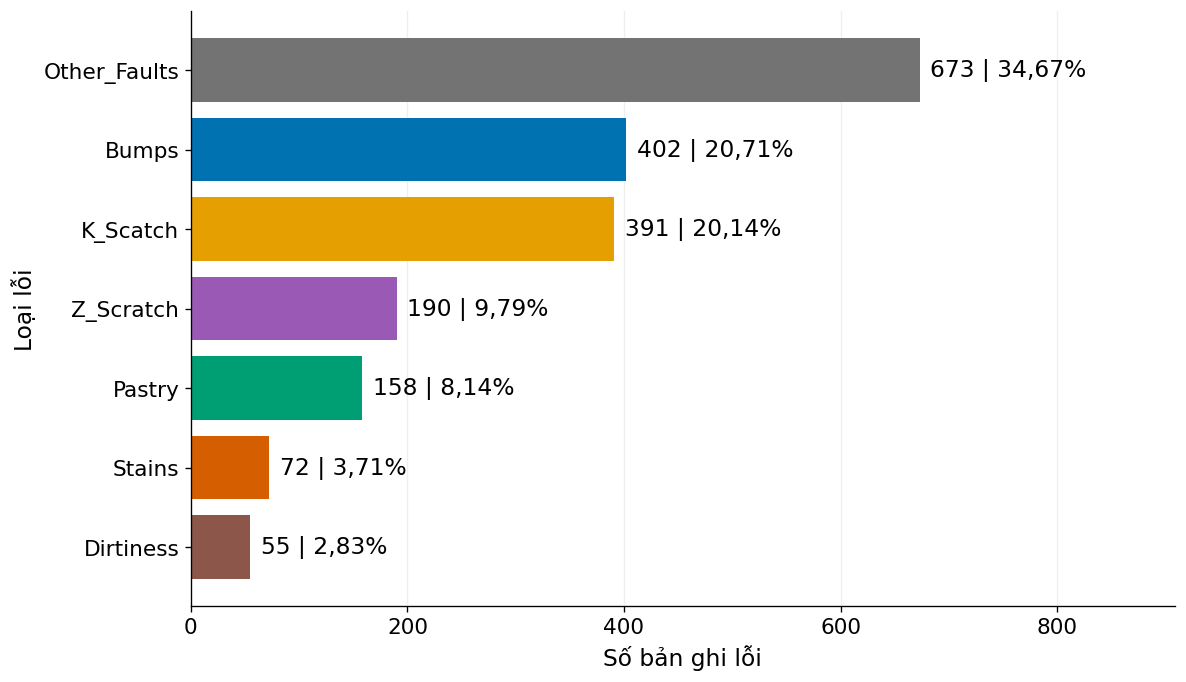

In [70]:
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(co_cau_loi["Fault_Type_Clean"], co_cau_loi["Count"],
        color=[MAU_LOI[nhan] for nhan in THU_TU_LOI])
ax.invert_yaxis()
for vi_tri, dong in co_cau_loi.iterrows():
    ax.text(dong["Count"] + 10, vi_tri, f'{dinh_dang_so(dong["Count"])} | {dinh_dang_so(dong["Percent"], 2)}%', va="center")
ax.set_xlim(0, co_cau_loi["Count"].max() * 1.35)
ax.set(xlabel="Số bản ghi lỗi", ylabel="Loại lỗi")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
luu_hinh(fig, "01_co_cau_loi", "Q1", f"Nguồn: bảng lỗi đối chiếu UCI | n={so_ban_ghi:,} | Tỷ trọng trên toàn tập lỗi")

In [71]:
nhom_lon_nhat = co_cau_loi.iloc[0]
nhom_nho_nhat = co_cau_loi.iloc[-1]
ty_so_co_mau = nhom_lon_nhat["Count"] / nhom_nho_nhat["Count"]

In [72]:
ghi_nhan_xet("01_co_cau_loi", f"""
**Quan sát:** {nhom_lon_nhat['Fault_Type_Clean']} nhiều nhất, {nhom_nho_nhat['Fault_Type_Clean']} ít nhất.
**Số liệu:** {nhom_lon_nhat['Count']:,} ({nhom_lon_nhat['Percent']:.2f}%) so với
{nhom_nho_nhat['Count']:,} ({nhom_nho_nhat['Percent']:.2f}%); cỡ mẫu lớn nhất gấp {ty_so_co_mau:.2f} lần nhỏ nhất.
**Ý nghĩa:** dữ liệu mất cân bằng; khi so sánh đặc trưng cần đọc cả cỡ mẫu từng nhãn.
**Giới hạn:** Other_Faults là nhãn gộp; số lượng lớn không chứng minh lỗi nghiêm trọng hơn hoặc gây thiệt hại lớn hơn.
""")

**Quan sát:** Other_Faults nhiều nhất, Dirtiness ít nhất.
**Số liệu:** 673 (34.67%) so với
55 (2.83%); cỡ mẫu lớn nhất gấp 12.24 lần nhỏ nhất.
**Ý nghĩa:** dữ liệu mất cân bằng; khi so sánh đặc trưng cần đọc cả cỡ mẫu từng nhãn.
**Giới hạn:** Other_Faults là nhãn gộp; số lượng lớn không chứng minh lỗi nghiêm trọng hơn hoặc gây thiệt hại lớn hơn.

### Hình 2. Pareto và mức tập trung của số bản ghi

Cột biểu diễn số lượng; đường biểu diễn tỷ trọng lũy kế với trục phần trăm riêng (0–100%).
Đường 80% là mốc tham khảo để đọc mức tập trung, không phải tiêu chuẩn chất lượng.

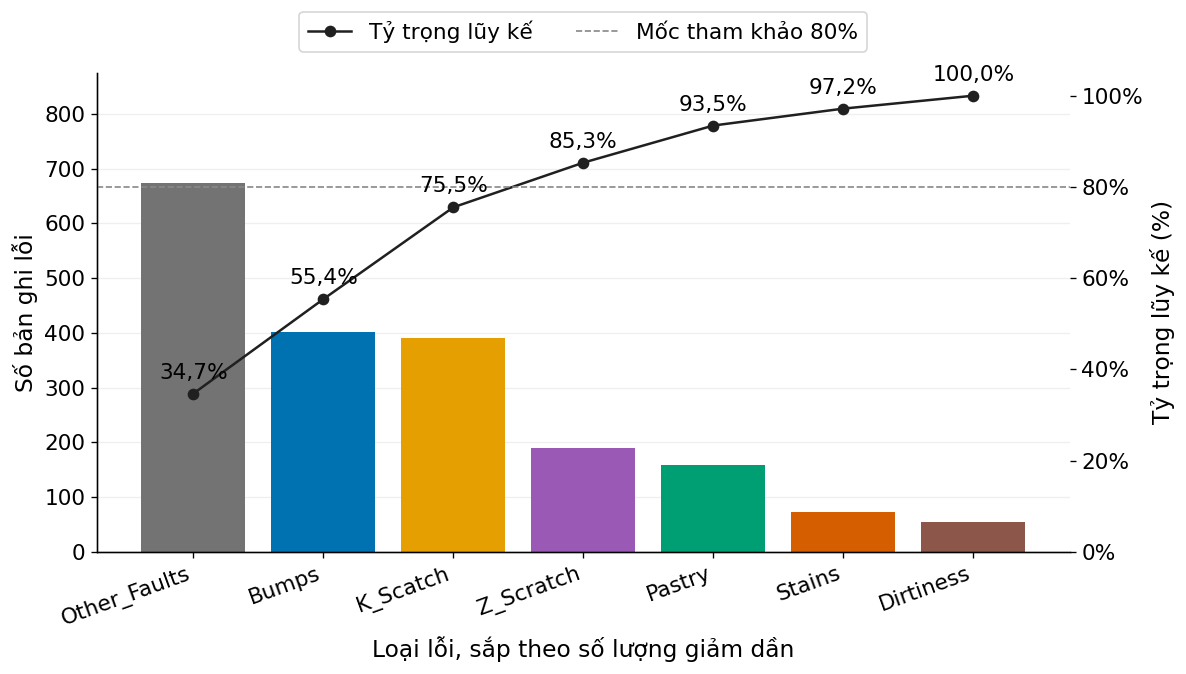

In [73]:
fig, ax = plt.subplots(figsize=(10, 5.8))
x = np.arange(len(co_cau_loi))
ax.bar(x, co_cau_loi["Count"], color=[MAU_LOI[nhan] for nhan in THU_TU_LOI])
ax.set_xticks(x, THU_TU_LOI, rotation=20, ha="right")
ax.set(xlabel="Loại lỗi, sắp theo số lượng giảm dần", ylabel="Số bản ghi lỗi")
ax.set_ylim(0, co_cau_loi["Count"].max() * 1.3)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax_luy_ke = ax.twinx()
ax_luy_ke.plot(x, co_cau_loi["Cumulative_Percent"], color="#202020", marker="o", label="Tỷ trọng lũy kế")
ax_luy_ke.axhline(80, color="#888888", linestyle="--", linewidth=1, label="Mốc tham khảo 80%")
ax_luy_ke.set_ylim(0, 105)
ax_luy_ke.set_ylabel("Tỷ trọng lũy kế (%)")
ax_luy_ke.yaxis.set_major_formatter(PercentFormatter(100))
for vi_tri, ty_trong in enumerate(co_cau_loi["Cumulative_Percent"]):
    ax_luy_ke.annotate(f"{dinh_dang_so(ty_trong, 1)}%", (vi_tri, ty_trong), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=13)
ax_luy_ke.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2, fontsize=13)
luu_hinh(fig, "02_pareto_loi", "Q1", f"Nguồn: bảng lỗi đối chiếu UCI | n={so_ban_ghi:,} | Lũy kế theo số lượng, không theo thiệt hại")

In [74]:
ba_nhom_dau = co_cau_loi.head(3)
so_nhom_dat_80 = int(np.flatnonzero(co_cau_loi["Cumulative_Percent"].ge(80).to_numpy())[0] + 1)

In [75]:
ghi_nhan_xet("02_pareto_loi", f"""
**Quan sát:** số bản ghi tập trung ở một số nhãn đầu.
**Số liệu:** {', '.join(ba_nhom_dau['Fault_Type_Clean'])} có tổng {ba_nhom_dau['Count'].sum():,} bản ghi,
chiếm {ba_nhom_dau['Percent'].sum():.2f}%; cần {so_nhom_dat_80} nhãn đầu để lũy kế đạt ít nhất 80%.
**Ý nghĩa:** ưu tiên các nhóm này khi mô tả phần lớn tập dữ liệu, đồng thời giữ các nhãn ít mẫu để tránh bỏ sót.
**Giới hạn:** Pareto mô tả mức tập trung bản ghi; chưa có chi phí hoặc mức hạ cấp để xếp ưu tiên xử lý sản xuất.
""")

**Quan sát:** số bản ghi tập trung ở một số nhãn đầu.
**Số liệu:** Other_Faults, Bumps, K_Scatch có tổng 1,466 bản ghi,
chiếm 75.53%; cần 4 nhãn đầu để lũy kế đạt ít nhất 80%.
**Ý nghĩa:** ưu tiên các nhóm này khi mô tả phần lớn tập dữ liệu, đồng thời giữ các nhãn ít mẫu để tránh bỏ sót.
**Giới hạn:** Pareto mô tả mức tập trung bản ghi; chưa có chi phí hoặc mức hạ cấp để xếp ưu tiên xử lý sản xuất.

## 5.3. So sánh theo dòng thép — Q2

### Hình 3. So sánh số lượng tuyệt đối

Cùng màu là cùng loại lỗi. A300 có họa tiết chéo; A400 có màu đặc.
Số lượng được đọc cùng cỡ mẫu: A300 và A400 có tổng bản ghi khác nhau.

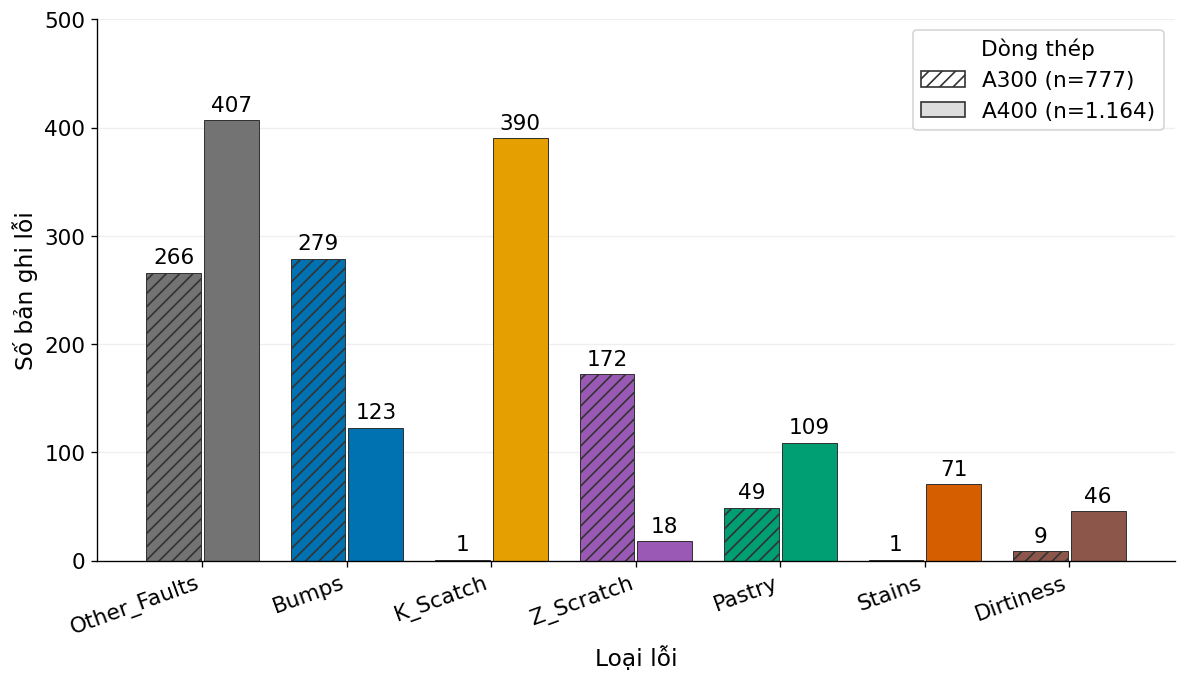

In [76]:
bang_dem_thep = loi_theo_thep.pivot(index="Fault_Type_Clean", columns="Steel_Type", values="Count").reindex(THU_TU_LOI)
fig, ax = plt.subplots(figsize=(10, 5.8))
x = np.arange(len(THU_TU_LOI))
for dong_thep, do_lech, hoa_tiet in [("A300", -0.2, "///"), ("A400", 0.2, "")]:
    cot = ax.bar(x + do_lech, bang_dem_thep[dong_thep], width=0.38,
                 color=[MAU_LOI[nhan] for nhan in THU_TU_LOI], hatch=hoa_tiet, edgecolor="#333333", linewidth=0.6)
    ax.bar_label(cot, padding=3, fontsize=13)
ax.set_xticks(x, THU_TU_LOI, rotation=20, ha="right")
ax.set(xlabel="Loại lỗi", ylabel="Số bản ghi lỗi")
ax.set_ylim(0, bang_dem_thep.to_numpy().max() * 1.23)
ax.legend(handles=[Patch(facecolor="white", edgecolor="#333333", hatch="///", label=f"A300 (n={dinh_dang_so(co_mau_thep['A300'])})"),
                   Patch(facecolor="#dddddd", edgecolor="#333333", label=f"A400 (n={dinh_dang_so(co_mau_thep['A400'])})")], title="Dòng thép")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
luu_hinh(fig, "03_loi_theo_thep_so_luong", "Q2", f"Nguồn: bảng lỗi đối chiếu UCI | n={so_ban_ghi:,} | Màu: loại lỗi; họa tiết: dòng thép")

In [77]:
ty_trong_theo_nhan = loi_theo_thep.pivot(
    index="Fault_Type_Clean", columns="Steel_Type", values="Percent_Within_Fault"
)
tap_trung_theo_nhan = pd.DataFrame({
    "Fault_Type_Clean": THU_TU_LOI,
    "N": [co_mau_loi[nhan] for nhan in THU_TU_LOI],
    "Dong_thep_tap_trung": ty_trong_theo_nhan.reindex(THU_TU_LOI).idxmax(axis=1).to_numpy(),
    "Ty_trong_trong_nhan": ty_trong_theo_nhan.reindex(THU_TU_LOI).max(axis=1).to_numpy(),
})
tap_trung_theo_nhan["Vuot_moc_PDF"] = (
    tap_trung_theo_nhan["Ty_trong_trong_nhan"] > NGUONG_TAP_TRUNG_PHAN_TRAM
)
display(tap_trung_theo_nhan.round(2))

,Fault_Type_Clean,N,Dong_thep_tap_trung,Ty_trong_trong_nhan,Vuot_moc_PDF
0,Other_Faults,673,A400,60.48,False
1,Bumps,402,A300,69.40,False
2,K_Scatch,391,A400,99.74,True
3,Z_Scratch,190,A300,90.53,True
4,Pastry,158,A400,68.99,False
5,Stains,72,A400,98.61,True
6,Dirtiness,55,A400,83.64,False


In [78]:
ghi_nhan_xet("03_loi_theo_thep_so_luong", f"""
**Quan sát:** K_Scatch tập trung trên A400; Z_Scratch tập trung trên A300.
**Số liệu:** K_Scatch có {bang_dem_thep.loc['K_Scatch', 'A400']:,}/{co_mau_loi['K_Scatch']:,} bản ghi trên A400
({ty_trong_theo_nhan.loc['K_Scatch', 'A400']:.2f}%); Z_Scratch có {bang_dem_thep.loc['Z_Scratch', 'A300']:,}/{co_mau_loi['Z_Scratch']:,}
trên A300 ({ty_trong_theo_nhan.loc['Z_Scratch', 'A300']:.2f}%). Stains có {ty_trong_theo_nhan.loc['Stains', 'A400']:.2f}% trên A400.
**Trả lời Q2:** các nhãn vượt mốc tập trung {NGUONG_TAP_TRUNG_PHAN_TRAM:.0f}% của PDF là
{', '.join(tap_trung_theo_nhan.loc[tap_trung_theo_nhan['Vuot_moc_PDF'], 'Fault_Type_Clean'])}.
Mẫu số ở đây là toàn bộ bản ghi của từng nhãn; cần kiểm chứng riêng các tổ hợp nhãn–dòng thép.
**Giới hạn:** A300 có {co_mau_thep['A300']:,}, A400 có {co_mau_thep['A400']:,} bản ghi lỗi.
Thiếu sản lượng nên chưa kết luận dòng nào dễ lỗi hơn; liên hệ chưa xác định nguyên nhân.
""")

**Quan sát:** K_Scatch tập trung trên A400; Z_Scratch tập trung trên A300.
**Số liệu:** K_Scatch có 390/391 bản ghi trên A400
(99.74%); Z_Scratch có 172/190
trên A300 (90.53%). Stains có 98.61% trên A400.
**Trả lời Q2:** các nhãn vượt mốc tập trung 90% của PDF là
K_Scatch, Z_Scratch, Stains.
Mẫu số ở đây là toàn bộ bản ghi của từng nhãn; cần kiểm chứng riêng các tổ hợp nhãn–dòng thép.
**Giới hạn:** A300 có 777, A400 có 1,164 bản ghi lỗi.
Thiếu sản lượng nên chưa kết luận dòng nào dễ lỗi hơn; liên hệ chưa xác định nguyên nhân.

### Hình 4. Cơ cấu trong từng dòng thép (100%)

Dùng `Percent_Within_Steel`: mẫu số là toàn bộ **bản ghi lỗi của dòng thép đó**.
Khác với tỷ trọng theo nhãn vừa dùng để diễn giải Hình 3.

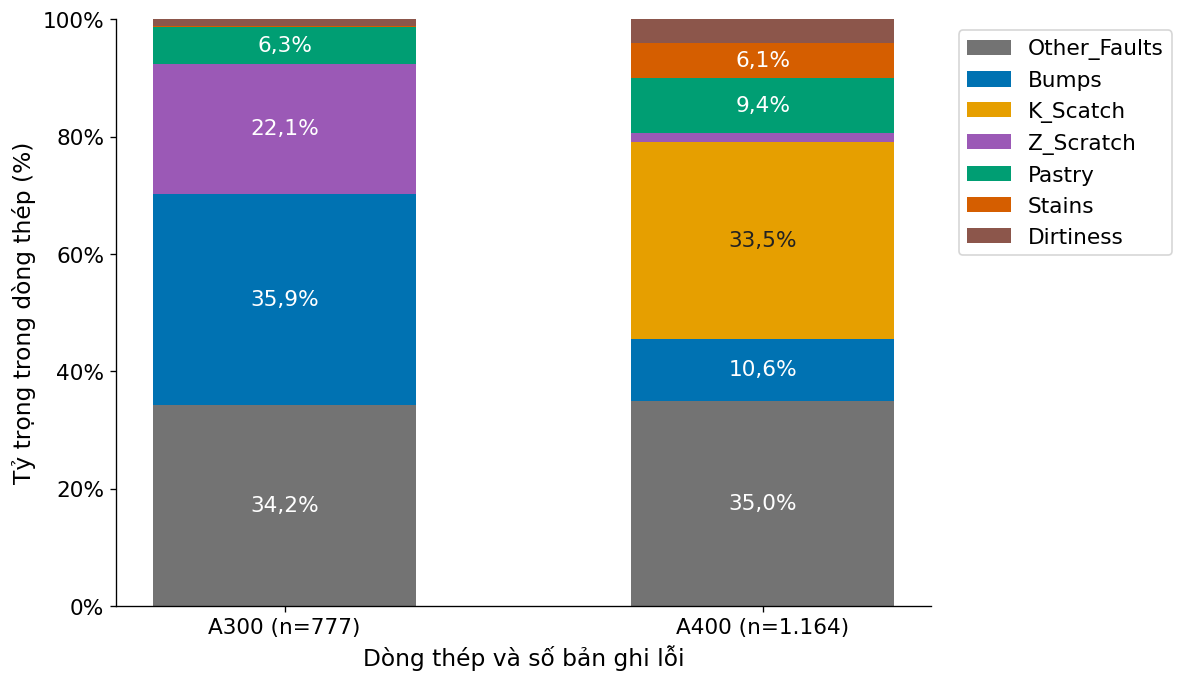

In [79]:
bang_ty_trong_thep = loi_theo_thep.pivot(index="Steel_Type", columns="Fault_Type_Clean", values="Percent_Within_Steel")
bang_ty_trong_thep = bang_ty_trong_thep.reindex(index=["A300", "A400"], columns=THU_TU_LOI)
fig, ax = plt.subplots(figsize=(10, 5.8))
day = np.zeros(2)
for nhan in THU_TU_LOI:
    ty_trong = bang_ty_trong_thep[nhan].to_numpy()
    ax.bar(["A300", "A400"], ty_trong, bottom=day, color=MAU_LOI[nhan], width=0.55, label=nhan)
    for vi_tri, gia_tri in enumerate(ty_trong):
        if gia_tri >= 5:
            ax.text(vi_tri, day[vi_tri] + gia_tri / 2, f"{dinh_dang_so(gia_tri, 1)}%", ha="center", va="center",
                    color="white" if nhan != "K_Scatch" else "#222222", fontsize=13)
    day += ty_trong
ax.set_xticks([0, 1], [f"A300 (n={dinh_dang_so(co_mau_thep['A300'])})", f"A400 (n={dinh_dang_so(co_mau_thep['A400'])})"])
ax.set(xlabel="Dòng thép và số bản ghi lỗi", ylabel="Tỷ trọng trong dòng thép (%)", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
luu_hinh(fig, "04_loi_theo_thep_ty_trong", "Q2", "Nguồn: bảng lỗi đối chiếu UCI | Mỗi dòng thép cộng 100%; phần dưới 5% xem bảng số liệu")

In [80]:
ghi_nhan_xet("04_loi_theo_thep_ty_trong", f"""
**Quan sát:** cơ cấu của hai dòng thép khác nhau dù Other_Faults có tỷ trọng gần nhau.
**Số liệu:** trong A300, Bumps chiếm {bang_ty_trong_thep.loc['A300', 'Bumps']:.2f}% và Z_Scratch {bang_ty_trong_thep.loc['A300', 'Z_Scratch']:.2f}%;
trong A400, K_Scatch chiếm {bang_ty_trong_thep.loc['A400', 'K_Scatch']:.2f}% và Bumps {bang_ty_trong_thep.loc['A400', 'Bumps']:.2f}%.
Other_Faults chiếm lần lượt {bang_ty_trong_thep.loc['A300', 'Other_Faults']:.2f}% và {bang_ty_trong_thep.loc['A400', 'Other_Faults']:.2f}%.
**Ý nghĩa:** chuẩn hóa về 100% giúp so sánh cơ cấu khi tổng bản ghi hai dòng khác nhau.
**Giới hạn:** đây là tỷ trọng trong tập lỗi, không phải tỷ lệ lỗi trên tổng sản lượng của A300/A400.
""")

**Quan sát:** cơ cấu của hai dòng thép khác nhau dù Other_Faults có tỷ trọng gần nhau.
**Số liệu:** trong A300, Bumps chiếm 35.91% và Z_Scratch 22.14%;
trong A400, K_Scatch chiếm 33.51% và Bumps 10.57%.
Other_Faults chiếm lần lượt 34.23% và 34.97%.
**Ý nghĩa:** chuẩn hóa về 100% giúp so sánh cơ cấu khi tổng bản ghi hai dòng khác nhau.
**Giới hạn:** đây là tỷ trọng trong tập lỗi, không phải tỷ lệ lỗi trên tổng sản lượng của A300/A400.

## 5.4. Phân tích đặc trưng độ sáng — Q3

### a. Tương quan và thống kê theo nhãn

Tính Pearson toàn tập và theo nhãn để phân biệt xu hướng chung với từng nhóm.
Hệ số mô tả quan hệ tuyến tính giữa hai biến; không đo trực tiếp khả năng phân loại nhãn.
Bảng kèm trung vị, Q1 và Q3 của hai biến để hỗ trợ cách đọc scatter.

In [81]:
cot_min = "Minimum_of_Luminosity"
cot_max = "Maximum_of_Luminosity"
pearson_chung = loi_thep_phan_tich[cot_min].corr(loi_thep_phan_tich[cot_max])
cac_dong_tuong_quan = [{"Group": "Toàn tập", "N": so_ban_ghi, "Pearson_r": pearson_chung}]
for nhan in THU_TU_LOI:
    nhom = loi_thep_phan_tich.loc[loi_thep_phan_tich["Fault_Type_Clean"].eq(nhan)]
    cac_dong_tuong_quan.append({"Group": nhan, "N": len(nhom), "Pearson_r": nhom[cot_min].corr(nhom[cot_max])})
tuong_quan_do_sang = pd.DataFrame(cac_dong_tuong_quan)
thong_ke_do_sang = dac_trung_theo_nhan.loc[dac_trung_theo_nhan["Variable"].isin([cot_min, cot_max]),
                                         ["Fault_Type_Clean", "Variable", "N", "Median", "Q1", "Q3", "Min", "Max"]].copy()
display(tuong_quan_do_sang.round(4))
display(thong_ke_do_sang.round(2))

,Group,N,Pearson_r
0,Toàn tập,1941,0.4296
1,Other_Faults,673,0.6298
2,Bumps,402,0.4242
3,K_Scatch,391,0.6296
4,Z_Scratch,190,0.8730
5,Pastry,158,0.2229
6,Stains,72,0.4455
7,Dirtiness,55,0.3776


,Fault_Type_Clean,Variable,N,Median,Q1,Q3,Min,Max
0,Other_Faults,Minimum_of_Luminosity,673,97.0,80.0,111.0,0,203
1,Bumps,Minimum_of_Luminosity,402,91.0,79.25,102.0,12,136
2,K_Scatch,Minimum_of_Luminosity,391,41.0,35.0,49.0,0,196
3,Z_Scratch,Minimum_of_Luminosity,190,93.0,81.0,104.0,22,122
4,Pastry,Minimum_of_Luminosity,158,80.0,64.0,94.0,11,124
5,Stains,Minimum_of_Luminosity,72,115.0,110.0,120.0,89,129
6,Dirtiness,Minimum_of_Luminosity,55,107.0,96.5,111.0,27,129
7,Other_Faults,Maximum_of_Luminosity,673,127.0,119.0,140.0,37,253
8,Bumps,Maximum_of_Luminosity,402,127.0,124.0,134.0,82,252
9,K_Scatch,Maximum_of_Luminosity,391,134.0,126.0,141.0,93,236


### Hình 5. Scatter Min × Max theo loại lỗi

Mỗi bản ghi là một điểm, giữ toàn bộ 1.941 điểm và giảm độ đậm (`alpha=0.35`).
Không nối điểm, không thêm ngưỡng phân loại sau khi quan sát dữ liệu.

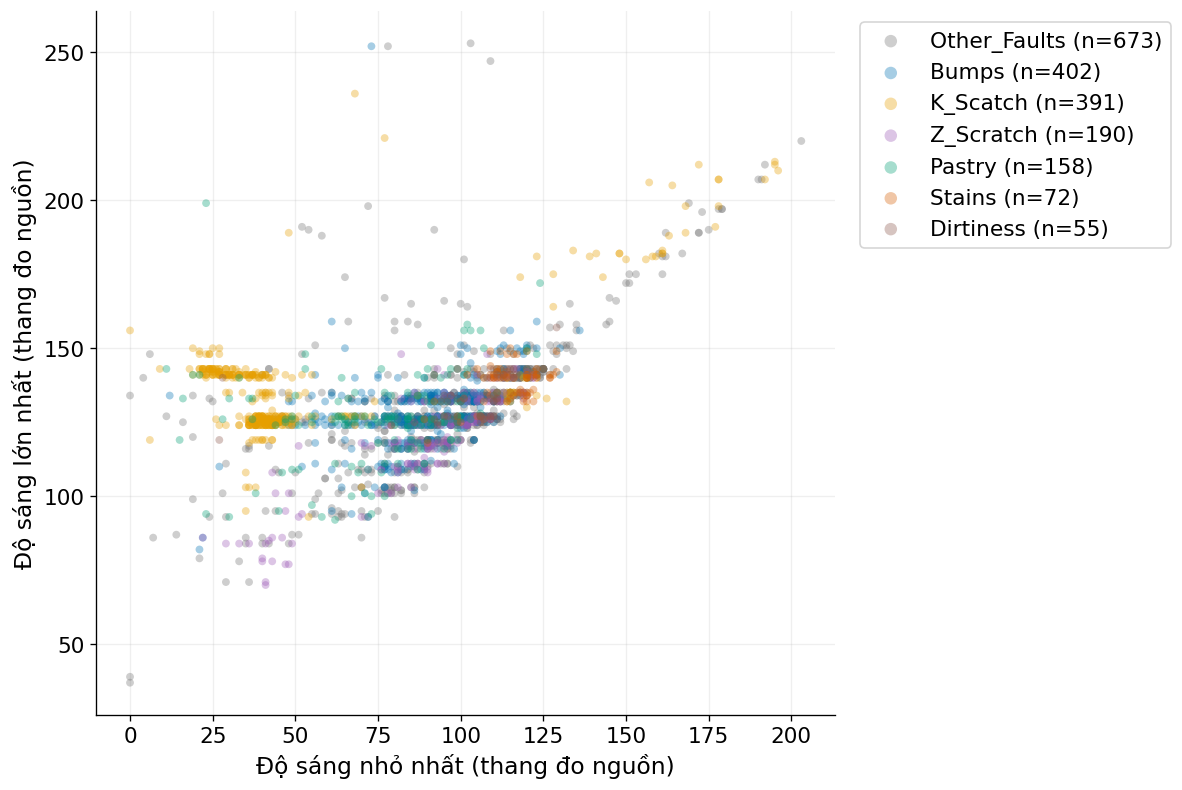

In [82]:
fig, ax = plt.subplots(figsize=(10, 6.7))
for nhan in THU_TU_LOI:
    nhom = loi_thep_phan_tich.loc[loi_thep_phan_tich["Fault_Type_Clean"].eq(nhan)]
    ax.scatter(nhom[cot_min], nhom[cot_max], s=22, alpha=0.35, color=MAU_LOI[nhan],
               edgecolors="none", label=f"{nhan} (n={dinh_dang_so(len(nhom))})")
ax.set(xlabel="Độ sáng nhỏ nhất (thang đo nguồn)", ylabel="Độ sáng lớn nhất (thang đo nguồn)")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=1.6, fontsize=13)
luu_hinh(fig, "05_scatter_do_sang", "Q3", f"Nguồn: bảng lỗi đối chiếu UCI | n={so_ban_ghi:,} | Mỗi điểm là một bản ghi; các điểm có thể chồng lên nhau")

In [83]:
thong_ke_min = thong_ke_do_sang.loc[
    thong_ke_do_sang["Variable"].eq(cot_min)
].set_index("Fault_Type_Clean")
trung_vi_min = thong_ke_min["Median"]
min_cac_nhan_khac = trung_vi_min.drop("K_Scatch")
trung_vi_max = thong_ke_do_sang.loc[
    thong_ke_do_sang["Variable"].eq(cot_max)
].set_index("Fault_Type_Clean")["Median"]

# Chỉ đánh giá khả năng phân tách 50% trung tâm, không phải mọi điểm.
dau_hieu_do_sang = thong_ke_min[["N", "Median", "Q1", "Q3"]].copy()
for nhan, dong in thong_ke_min.iterrows():
    cac_nhan_khac = thong_ke_min.drop(nhan)
    khong_chong_lan = (dong["Q3"] < cac_nhan_khac["Q1"]) | (dong["Q1"] > cac_nhan_khac["Q3"])
    dau_hieu_do_sang.loc[nhan, "IQR_Min_tach_moi_nhan_khac"] = bool(khong_chong_lan.all())
display(dau_hieu_do_sang.reset_index().round(2))

,Fault_Type_Clean,N,Median,Q1,Q3,IQR_Min_tach_moi_nhan_khac
0,Other_Faults,673,97.0,80.0,111.0,False
1,Bumps,402,91.0,79.25,102.0,False
2,K_Scatch,391,41.0,35.0,49.0,True
3,Z_Scratch,190,93.0,81.0,104.0,False
4,Pastry,158,80.0,64.0,94.0,False
5,Stains,72,115.0,110.0,120.0,False
6,Dirtiness,55,107.0,96.5,111.0,False


In [84]:
ghi_nhan_xet("05_scatter_do_sang", f"""
**Quan sát:** K_Scatch nghiêng về phía Min thấp; các nhóm khác còn chồng lấn ở vùng trung tâm.
**Số liệu:** Pearson toàn tập = {pearson_chung:.4f}; trung vị Min của K_Scatch là {trung_vi_min['K_Scatch']:.0f},
trong khi sáu nhãn khác nằm từ {min_cac_nhan_khac.min():.0f} đến {min_cac_nhan_khac.max():.0f}.
IQR Min của K_Scatch là {thong_ke_min.loc['K_Scatch', 'Q1']:.0f}–{thong_ke_min.loc['K_Scatch', 'Q3']:.0f};
Q1 nhỏ nhất của sáu nhãn khác là {thong_ke_min.drop('K_Scatch')['Q1'].min():.0f}.
Trung vị Max của Z_Scratch là {trung_vi_max['Z_Scratch']:.0f}, so với Bumps {trung_vi_max['Bumps']:.0f}.
**Trả lời Q3:** có dấu hiệu phân tách trung tâm ở Min của K_Scatch, đủ để ưu tiên kiểm chứng
đặc trưng này. Pearson mô tả quan hệ giữa Min và Max, không đo khả năng phân loại nhãn.
**Giới hạn:** IQR chỉ chứa 50% trung tâm; scatter vẫn có điểm chồng lấn.
Chưa có precision/recall hoặc hiệu năng trên tập kiểm tra độc lập.
""")

**Quan sát:** K_Scatch nghiêng về phía Min thấp; các nhóm khác còn chồng lấn ở vùng trung tâm.
**Số liệu:** Pearson toàn tập = 0.4296; trung vị Min của K_Scatch là 41,
trong khi sáu nhãn khác nằm từ 80 đến 115.
IQR Min của K_Scatch là 35–49;
Q1 nhỏ nhất của sáu nhãn khác là 64.
Trung vị Max của Z_Scratch là 124, so với Bumps 127.
**Trả lời Q3:** có dấu hiệu phân tách trung tâm ở Min của K_Scatch, đủ để ưu tiên kiểm chứng
đặc trưng này. Pearson mô tả quan hệ giữa Min và Max, không đo khả năng phân loại nhãn.
**Giới hạn:** IQR chỉ chứa 50% trung tâm; scatter vẫn có điểm chồng lấn.
Chưa có precision/recall hoặc hiệu năng trên tập kiểm tra độc lập.

### Đối chiếu các vùng độ sáng trong PDF VII.2

Các vùng Min < 50, Max trong 120–150 và Min > 120 lấy từ mô tả ở PDF trang 39,
được tính lại để kiểm chứng trên bảng sạch. Đây là mô tả trong mẫu sau khi quan sát,
chưa phải ngưỡng vận hành của một hệ thống nhận diện.

In [85]:
nhom_k = loi_thep_phan_tich.loc[loi_thep_phan_tich["Fault_Type_Clean"].eq("K_Scatch")]
vung_sang_cao = loi_thep_phan_tich.loc[loi_thep_phan_tich[cot_min].gt(120)]
so_k_min_thap = int(nhom_k[cot_min].lt(50).sum())
so_max_trong_dai = int(loi_thep_phan_tich[cot_max].between(120, 150).sum())
do_sang_vung = pd.DataFrame([
    ["K_Scatch có Min < 50", so_k_min_thap, len(nhom_k), so_k_min_thap / len(nhom_k) * 100],
    ["Toàn tập có Max từ 120 đến 150", so_max_trong_dai, so_ban_ghi, so_max_trong_dai / so_ban_ghi * 100],
    ["Toàn tập có Min > 120", len(vung_sang_cao), so_ban_ghi, len(vung_sang_cao) / so_ban_ghi * 100],
], columns=["Vung_mo_ta", "N", "Mau_so", "Ty_trong_phan_tram"])
display(do_sang_vung.round(2))

,Vung_mo_ta,N,Mau_so,Ty_trong_phan_tram
0,K_Scatch có Min < 50,297,391,75.96
1,Toàn tập có Max từ 120 đến 150,1432,1941,73.78
2,Toàn tập có Min > 120,140,1941,7.21


In [86]:
display(Markdown(f"""
Ở vùng Min > 120 có {len(vung_sang_cao)} bản ghi, trong đó
{int(vung_sang_cao['Fault_Type_Clean'].eq('Other_Faults').sum())} thuộc Other_Faults.
Hiệu Max−Min có trung vị {vung_sang_cao['Luminosity_Range'].median():.0f},
IQR {vung_sang_cao['Luminosity_Range'].quantile(.25):.0f}–{vung_sang_cao['Luminosity_Range'].quantile(.75):.0f}.
Đây là hướng khảo sát nhóm con; cần ảnh lỗi và định nghĩa QC trước khi tách nhãn.
"""))


Ở vùng Min > 120 có 140 bản ghi, trong đó
74 thuộc Other_Faults.
Hiệu Max−Min có trung vị 19,
IQR 17–22.
Đây là hướng khảo sát nhóm con; cần ảnh lỗi và định nghĩa QC trước khi tách nhãn.


## 5.5. Phân tích độ dày và diện tích — Q4, Q5

### Hình 6. Boxplot độ dày theo nhãn

Hộp biểu diễn Q1–Q3, đường trong hộp là trung vị, râu tới giá trị quan sát xa nhất
trong 1,5 IQR. Điểm ngoài râu vẫn được hiển thị; không loại chúng khỏi tính toán.
Hộp có thể co thành một đường khi Q1 = Q3; điều này phản ánh dữ liệu, không phải lỗi vẽ.

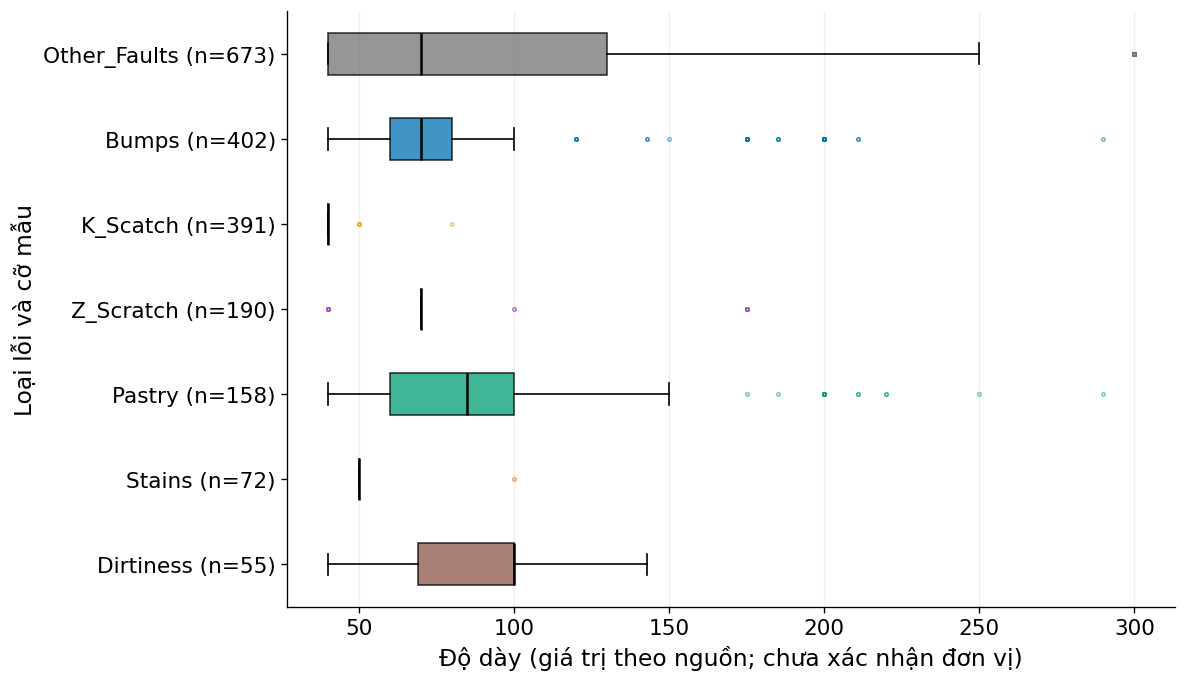

In [87]:
thong_ke_do_day = dac_trung_theo_nhan.loc[dac_trung_theo_nhan["Variable"].eq("Steel_Plate_Thickness")].copy()
du_lieu_hop = [loi_thep_phan_tich.loc[loi_thep_phan_tich["Fault_Type_Clean"].eq(nhan), "Steel_Plate_Thickness"] for nhan in THU_TU_LOI]
fig, ax = plt.subplots(figsize=(10, 5.8))
hop = ax.boxplot(du_lieu_hop, vert=False, patch_artist=True, whis=1.5,
                 medianprops={"color": "black", "linewidth": 1.5},
                 flierprops={"marker": ".", "markersize": 4, "alpha": 0.5})
for nhan, than_hop, diem_ngoai in zip(THU_TU_LOI, hop["boxes"], hop["fliers"]):
    than_hop.set_facecolor(MAU_LOI[nhan])
    than_hop.set_alpha(0.75)
    diem_ngoai.set_markeredgecolor(MAU_LOI[nhan])
ax.set_yticks(np.arange(1, 8), [f"{nhan} (n={dinh_dang_so(co_mau_loi[nhan])})" for nhan in THU_TU_LOI])
ax.invert_yaxis()
ax.set(xlabel="Độ dày (giá trị theo nguồn; chưa xác nhận đơn vị)", ylabel="Loại lỗi và cỡ mẫu")
ax.grid(axis="x", alpha=0.2)
luu_hinh(fig, "06_boxplot_do_day", "Q4", f"Nguồn: bảng lỗi đối chiếu UCI | n={so_ban_ghi:,} | Hộp: Q1–Q3; râu: 1,5 IQR từng nhãn; giữ mọi bản ghi")

In [88]:
do_day_theo_nhan = thong_ke_do_day.set_index("Fault_Type_Clean")
do_day_chung = loi_thep_phan_tich["Steel_Plate_Thickness"]
so_ban_ghi_do_day_40_80 = int(do_day_chung.between(40, 80).sum())
display(thong_ke_do_day.round(2))

,Fault_Type_Clean,Variable,N,Mean,Median,Std,Q1,Q3,Min,Max
14,Other_Faults,Steel_Plate_Thickness,673,102.6,70.0,73.85,40.0,130.0,40,300
15,Bumps,Steel_Plate_Thickness,402,76.93,70.0,38.05,60.0,80.0,40,290
16,K_Scatch,Steel_Plate_Thickness,391,40.18,40.0,2.2,40.0,40.0,40,80
17,Z_Scratch,Steel_Plate_Thickness,190,74.58,70.0,24.7,70.0,70.0,40,175
18,Pastry,Steel_Plate_Thickness,158,92.91,85.0,51.59,60.0,100.0,40,290
19,Stains,Steel_Plate_Thickness,72,50.69,50.0,5.89,50.0,50.0,50,100
20,Dirtiness,Steel_Plate_Thickness,55,84.45,100.0,28.66,69.0,100.0,40,143


In [89]:
ghi_nhan_xet("06_boxplot_do_day", f"""
**Quan sát:** độ dày K_Scatch tập trung ở mức thấp, Other_Faults phân tán rộng hơn.
**Số liệu:** K_Scatch có trung vị {do_day_theo_nhan.loc['K_Scatch', 'Median']:.0f},
Q1–Q3 = {do_day_theo_nhan.loc['K_Scatch', 'Q1']:.0f}–{do_day_theo_nhan.loc['K_Scatch', 'Q3']:.0f},
độ lệch chuẩn mẫu {do_day_theo_nhan.loc['K_Scatch', 'Std']:.2f}; Other_Faults có Q1–Q3 =
{do_day_theo_nhan.loc['Other_Faults', 'Q1']:.0f}–{do_day_theo_nhan.loc['Other_Faults', 'Q3']:.0f}.
Toàn tập có trung bình {do_day_chung.mean():.2f}, trung vị {do_day_chung.median():.0f} và độ lệch chuẩn mẫu {do_day_chung.std():.2f}.
Có {so_ban_ghi_do_day_40_80:,}/{so_ban_ghi:,} bản ghi nằm ở độ dày 40–80
({so_ban_ghi_do_day_40_80 / so_ban_ghi * 100:.2f}%).
**Trả lời Q4:** phân bố độ dày khác nhau theo nhãn; K_Scatch tập trung hẹp.
Cần đọc tiếp nhãn × dòng thép để chọn tổ hợp cần kiểm chứng.
**Giới hạn:** chưa có sản lượng theo độ dày nên không suy ra tấm mỏng dễ lỗi hơn; số liệu chưa xác nhận đơn vị vật lý.
""")

**Quan sát:** độ dày K_Scatch tập trung ở mức thấp, Other_Faults phân tán rộng hơn.
**Số liệu:** K_Scatch có trung vị 40,
Q1–Q3 = 40–40,
độ lệch chuẩn mẫu 2.20; Other_Faults có Q1–Q3 =
40–130.
Toàn tập có trung bình 78.74, trung vị 70 và độ lệch chuẩn mẫu 55.09.
Có 1,481/1,941 bản ghi nằm ở độ dày 40–80
(76.30%).
**Trả lời Q4:** phân bố độ dày khác nhau theo nhãn; K_Scatch tập trung hẹp.
Cần đọc tiếp nhãn × dòng thép để chọn tổ hợp cần kiểm chứng.
**Giới hạn:** chưa có sản lượng theo độ dày nên không suy ra tấm mỏng dễ lỗi hơn; số liệu chưa xác nhận đơn vị vật lý.

### Bảng bổ sung. Độ dày tách theo dòng thép

Theo PDF VII.3, kiểm tra độ dày đồng thời theo nhãn và dòng thép.
Giữ `N`, trung bình, trung vị, Q1/Q3; nhóm N=1 chỉ mô tả một bản ghi,
không dùng để so sánh độ phân tán. Độ lệch chuẩn mẫu của nhóm N=1 là thiếu.

In [90]:
do_day_theo_nhan_thep = loi_thep_phan_tich.groupby(["Fault_Type_Clean", "Steel_Type"])["Steel_Plate_Thickness"].agg(
    N="count", Mean="mean", Median="median", Std="std",
    Q1=lambda nhom: nhom.quantile(0.25), Q3=lambda nhom: nhom.quantile(0.75),
).reset_index()
do_day_theo_nhan_thep["Ghi_chu"] = np.where(do_day_theo_nhan_thep["N"].eq(1), "Chỉ 1 bản ghi; không so sánh độ phân tán", "")
display(do_day_theo_nhan_thep.round(2))
do_day_tra_cuu = do_day_theo_nhan_thep.set_index(["Fault_Type_Clean", "Steel_Type"])

,Fault_Type_Clean,Steel_Type,N,Mean,Median,Std,Q1,Q3,Ghi_chu
0,Bumps,A300,279,80.88,70.0,29.35,69.0,80,
1,Bumps,A400,123,67.97,40.0,51.76,40.0,70,
2,Dirtiness,A300,9,77.22,69.0,24.67,69.0,69,
3,Dirtiness,A400,46,85.87,100.0,29.41,42.5,100,
4,K_Scatch,A300,1,80.0,80.0,<NA>,80.0,80,Chỉ 1 bản ghi; không so sánh độ phân tán
5,K_Scatch,A400,390,40.08,40.0,0.87,40.0,40,
6,Other_Faults,A300,266,104.64,80.0,58.39,70.0,100,
7,Other_Faults,A400,407,101.27,50.0,82.45,40.0,175,
8,Pastry,A300,49,89.47,80.0,33.09,69.0,100,
9,Pastry,A400,109,94.45,90.0,58.1,40.0,125,


In [91]:
display(Markdown(f"""
Bumps có trung vị độ dày {do_day_tra_cuu.loc[('Bumps', 'A300'), 'Median']:.0f} trên A300
(n={do_day_tra_cuu.loc[('Bumps', 'A300'), 'N']:.0f}) và {do_day_tra_cuu.loc[('Bumps', 'A400'), 'Median']:.0f} trên A400
(n={do_day_tra_cuu.loc[('Bumps', 'A400'), 'N']:.0f}). Vì vậy, thống kê gộp có thể che khác biệt theo dòng thép.
K_Scatch và Stains trên A300 mỗi nhãn chỉ có 1 bản ghi; Z_Scratch trên A400 có
{do_day_tra_cuu.loc[('Z_Scratch', 'A400'), 'N']:.0f} bản ghi, ít hơn phía A300.
Các so sánh này mô tả mẫu và cần đọc cùng cỡ mẫu; chưa xác định ảnh hưởng riêng của dòng thép hoặc độ dày.
"""))


Bumps có trung vị độ dày 70 trên A300
(n=279) và 40 trên A400
(n=123). Vì vậy, thống kê gộp có thể che khác biệt theo dòng thép.
K_Scatch và Stains trên A300 mỗi nhãn chỉ có 1 bản ghi; Z_Scratch trên A400 có
18 bản ghi, ít hơn phía A300.
Các so sánh này mô tả mẫu và cần đọc cùng cỡ mẫu; chưa xác định ảnh hưởng riêng của dòng thép hoặc độ dày.


### Hình 7. Boxplot diện tích trên trục log

Tính boxplot từ `Pixels_Areas` **ở thang gốc**, sau đó đổi trục hiển thị sang log cơ số 10.
Các nhãn trục vẫn là giá trị diện tích gốc; khoảng cách bằng nhau trên trục biểu diễn tỷ số bằng nhau.
Không tính boxplot trên log rồi diễn giải tứ phân vị như thang gốc.

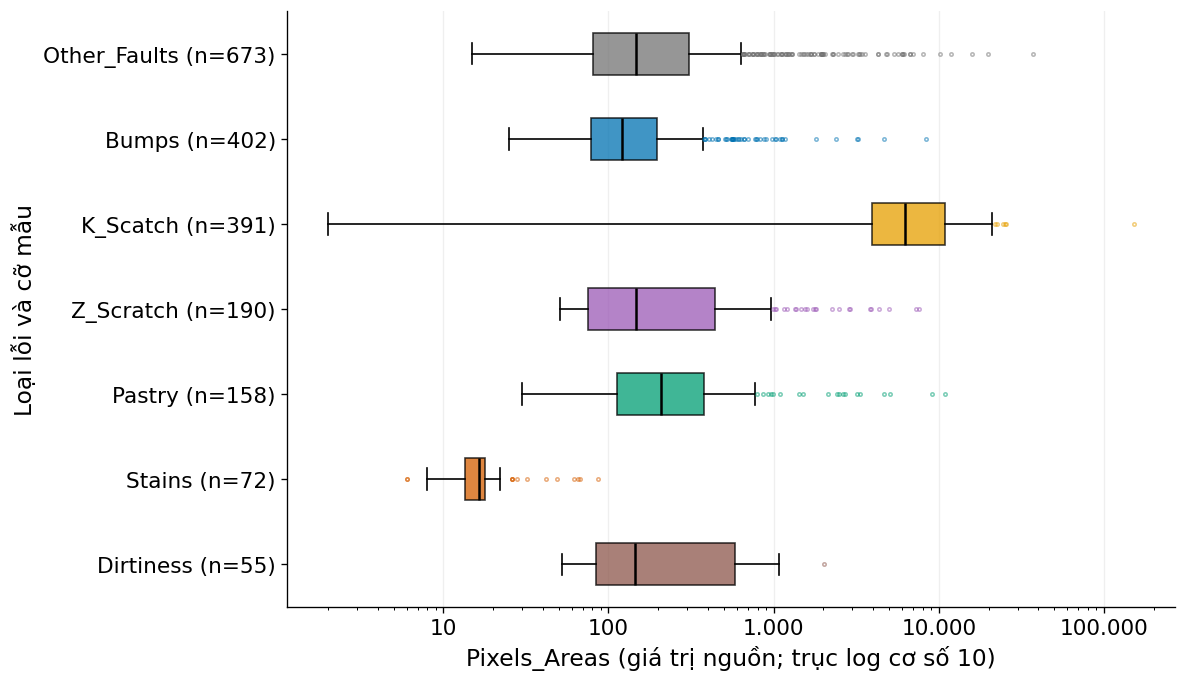

In [92]:
thong_ke_dien_tich = dac_trung_theo_nhan.loc[dac_trung_theo_nhan["Variable"].eq("Pixels_Areas")].copy()
du_lieu_hop = [loi_thep_phan_tich.loc[loi_thep_phan_tich["Fault_Type_Clean"].eq(nhan), "Pixels_Areas"] for nhan in THU_TU_LOI]
assert loi_thep_phan_tich["Pixels_Areas"].gt(0).all()
fig, ax = plt.subplots(figsize=(10, 5.8))
hop = ax.boxplot(du_lieu_hop, vert=False, patch_artist=True, whis=1.5,
                 medianprops={"color": "black", "linewidth": 1.5},
                 flierprops={"marker": ".", "markersize": 4, "alpha": 0.5})
for nhan, than_hop, diem_ngoai in zip(THU_TU_LOI, hop["boxes"], hop["fliers"]):
    than_hop.set_facecolor(MAU_LOI[nhan])
    than_hop.set_alpha(0.75)
    diem_ngoai.set_markeredgecolor(MAU_LOI[nhan])
ax.set_xscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: dinh_dang_so(x)))
ax.set_yticks(np.arange(1, 8), [f"{nhan} (n={dinh_dang_so(co_mau_loi[nhan])})" for nhan in THU_TU_LOI])
ax.invert_yaxis()
ax.set(xlabel="Pixels_Areas (giá trị nguồn; trục log cơ số 10)", ylabel="Loại lỗi và cỡ mẫu")
ax.grid(axis="x", which="major", alpha=0.2)
luu_hinh(fig, "07_boxplot_dien_tich_log", "Q5", f"Nguồn: bảng lỗi đối chiếu UCI | n={so_ban_ghi:,} | Boxplot tính trên thang gốc; trục log; giữ mọi bản ghi")

In [93]:
dien_tich_theo_nhan = thong_ke_dien_tich.set_index("Fault_Type_Clean")
nhan_trung_vi_lon = dien_tich_theo_nhan["Median"].idxmax()
nhan_trung_vi_nho = dien_tich_theo_nhan["Median"].idxmin()
co_dien_tich_theo_nhan = loi_thep_phan_tich.groupby("Fault_Type_Clean")["Area_Outlier_Flag"].agg(N="count", Flag_Count="sum").reset_index()
co_dien_tich_theo_nhan["Flag_Percent_Within_Fault"] = co_dien_tich_theo_nhan["Flag_Count"] / co_dien_tich_theo_nhan["N"] * 100
display(thong_ke_dien_tich.round(2))
display(co_dien_tich_theo_nhan.round(2))
# Điểm ngoài râu tính riêng từng nhãn, trên thang diện tích gốc.
so_diem_ngoai_rau = {}
for nhan in THU_TU_LOI:
    dien_tich_nhom = loi_thep_phan_tich.loc[loi_thep_phan_tich["Fault_Type_Clean"].eq(nhan), "Pixels_Areas"]
    q1_nhom, q3_nhom = dien_tich_nhom.quantile([0.25, 0.75])
    iqr_nhom = q3_nhom - q1_nhom
    so_diem_ngoai_rau[nhan] = int((dien_tich_nhom.lt(q1_nhom - 1.5 * iqr_nhom)
                                  | dien_tich_nhom.gt(q3_nhom + 1.5 * iqr_nhom)).sum())
co_dien_tich_theo_nhan["Group_Flier_Count"] = co_dien_tich_theo_nhan["Fault_Type_Clean"].map(so_diem_ngoai_rau)
co_dien_tich_theo_nhan = co_dien_tich_theo_nhan.set_index("Fault_Type_Clean").reindex(THU_TU_LOI).reset_index()
assert co_dien_tich_theo_nhan["Group_Flier_Count"].tolist() == [103, 44, 6, 23, 19, 13, 1]
assert co_dien_tich_theo_nhan["Group_Flier_Count"].sum() == 209
display(co_dien_tich_theo_nhan.round(2))


,Fault_Type_Clean,Variable,N,Mean,Median,Std,Q1,Q3,Min,Max
21,Other_Faults,Pixels_Areas,673,584.37,146.0,2040.21,81.0,308.0,15,37334
22,Bumps,Pixels_Areas,402,238.47,120.5,561.45,78.25,197.5,25,8391
23,K_Scatch,Pixels_Areas,391,7622.65,6281.0,9100.61,3948.5,10908.5,2,152655
24,Z_Scratch,Pixels_Areas,190,506.59,146.0,1039.79,75.25,442.0,51,7579
25,Pastry,Pixels_Areas,158,561.62,209.0,1314.77,112.5,381.25,30,10914
26,Stains,Pixels_Areas,72,19.92,16.5,14.15,13.5,18.0,6,86
27,Dirtiness,Pixels_Areas,55,363.49,145.0,384.57,84.5,581.5,52,2028


,Fault_Type_Clean,N,Flag_Count,Flag_Percent_Within_Fault
0,Bumps,402,5,1.24
1,Dirtiness,55,1,1.82
2,K_Scatch,391,326,83.38
3,Other_Faults,673,42,6.24
4,Pastry,158,11,6.96
5,Stains,72,0,0.0
6,Z_Scratch,190,10,5.26


,Fault_Type_Clean,N,Flag_Count,Flag_Percent_Within_Fault,Group_Flier_Count
0,Other_Faults,673,42,6.24,103
1,Bumps,402,5,1.24,44
2,K_Scatch,391,326,83.38,6
3,Z_Scratch,190,10,5.26,23
4,Pastry,158,11,6.96,19
5,Stains,72,0,0.0,13
6,Dirtiness,55,1,1.82,1


In [94]:
ghi_nhan_xet("07_boxplot_dien_tich_log", f"""
**Quan sát:** diện tích {nhan_trung_vi_lon} lớn hơn rõ về trung vị; {nhan_trung_vi_nho} có trung vị nhỏ nhất.
**Số liệu:** trung vị lần lượt {dien_tich_theo_nhan.loc[nhan_trung_vi_lon, 'Median']:,.1f} và
{dien_tich_theo_nhan.loc[nhan_trung_vi_nho, 'Median']:,.1f}; Q1–Q3 của K_Scatch là
{dien_tich_theo_nhan.loc['K_Scatch', 'Q1']:,.1f}–{dien_tich_theo_nhan.loc['K_Scatch', 'Q3']:,.1f}.
Toàn tập có {int(loi_thep_phan_tich['Area_Outlier_Flag'].sum()):,} bản ghi vượt ngưỡng IQR toàn tập, được giữ lại.
K_Scatch có {so_diem_ngoai_rau['K_Scatch']} điểm ngoài râu khi tính riêng nhãn,
so với {int(co_dien_tich_theo_nhan.set_index('Fault_Type_Clean').loc['K_Scatch', 'Flag_Count'])} cờ IQR toàn tập.
Tổng điểm ngoài râu riêng từng nhãn là {sum(so_diem_ngoai_rau.values())}.
**Ý nghĩa:** trục log giúp so sánh những nhóm khác nhau nhiều về quy mô; trung vị ít bị kéo bởi các vết rất lớn.
**Giới hạn:** diện tích lớn không tự chứng minh lỗi gây thiệt hại nặng hơn; cờ toàn tập khác với điểm ngoài râu của từng nhãn.
""")

**Quan sát:** diện tích K_Scatch lớn hơn rõ về trung vị; Stains có trung vị nhỏ nhất.
**Số liệu:** trung vị lần lượt 6,281.0 và
16.5; Q1–Q3 của K_Scatch là
3,948.5–10,908.5.
Toàn tập có 395 bản ghi vượt ngưỡng IQR toàn tập, được giữ lại.
K_Scatch có 6 điểm ngoài râu khi tính riêng nhãn,
so với 326 cờ IQR toàn tập.
Tổng điểm ngoài râu riêng từng nhãn là 209.
**Ý nghĩa:** trục log giúp so sánh những nhóm khác nhau nhiều về quy mô; trung vị ít bị kéo bởi các vết rất lớn.
**Giới hạn:** diện tích lớn không tự chứng minh lỗi gây thiệt hại nặng hơn; cờ toàn tập khác với điểm ngoài râu của từng nhãn.

## 5.6. Bối cảnh thương mại sắt thép từ API — Q6

Phạm vi: Việt Nam (704), HS 72, đối tác toàn thế giới (0), xuất/nhập khẩu theo năm 2015–2023.
Hai truy vấn 2024 rỗng ở bước 2–3; không vẽ 2024 thành số 0.
Trị giá hiển thị bằng **tỷ USD**, còn CSV giữ USD gốc. Đây là trị giá danh nghĩa,
không phải khối lượng thép hoặc giá trị đã điều chỉnh lạm phát.

Chuỗi có H4/H5/H6 và chưa quy đổi về một phiên bản HS chung.
Đánh dấu năm chuyển phiên bản, giữ lưu ý này trong mọi diễn giải biến động.

In [95]:
thuong_mai_ve = thuong_mai_phan_tich.copy(deep=True)
nam_doi_hs = thuong_mai_ve.loc[thuong_mai_ve["HS_Version_Changed"], "Year"].tolist()
cot_bang_thuong_mai = ["Year", "classificationCode", "Export_USD", "Import_USD", "Trade_Balance_USD",
                       "Export_Growth_Percent", "Import_Growth_Percent", "HS_Comparison_Note"]
display(thuong_mai_ve[cot_bang_thuong_mai].style.format(
    {cot: "{:,.2f}" for cot in cot_bang_thuong_mai if cot.endswith(("USD", "Percent"))}, na_rep="Chưa xác định"))

,Year,classificationCode,Export_USD,Import_USD,Trade_Balance_USD,Export_Growth_Percent,Import_Growth_Percent,HS_Comparison_Note
0,2015,H4,"2,203,817,925.00","8,724,835,288.00","-6,521,017,363.00",Chưa xác định,Chưa xác định,
1,2016,H4,"2,248,672,583.65","9,108,606,607.13","-6,859,934,023.48",2.04,4.40,
2,2017,H4,"3,332,978,963.60","10,682,441,538.60","-7,349,462,575.00",48.22,17.28,
3,2018,H5,"4,629,961,540.81","12,013,269,251.64","-7,383,307,710.83",38.91,12.46,Khác phiên bản HS năm trước; chưa quy đổi
4,2019,H5,"4,296,516,595.35","11,333,930,769.01","-7,037,414,173.66",-7.20,-5.65,
5,2020,H5,"5,339,979,332.41","9,900,340,614.58","-4,560,361,282.18",24.29,-12.65,
6,2021,H5,"11,935,412,188.58","14,744,151,209.06","-2,808,739,020.48",123.51,48.93,
7,2022,H6,"8,192,873,644.92","14,329,113,964.72","-6,136,240,319.79",-31.36,-2.81,Khác phiên bản HS năm trước; chưa quy đổi
8,2023,H6,"8,511,999,071.41","12,426,086,000.23","-3,914,086,928.82",3.90,-13.28,


### Hình 8. Xuất khẩu và nhập khẩu theo năm

Hai đường dùng chung trục trị giá để so sánh trực tiếp. Đường dọc nét đứt chỉ năm đổi phiên bản HS.

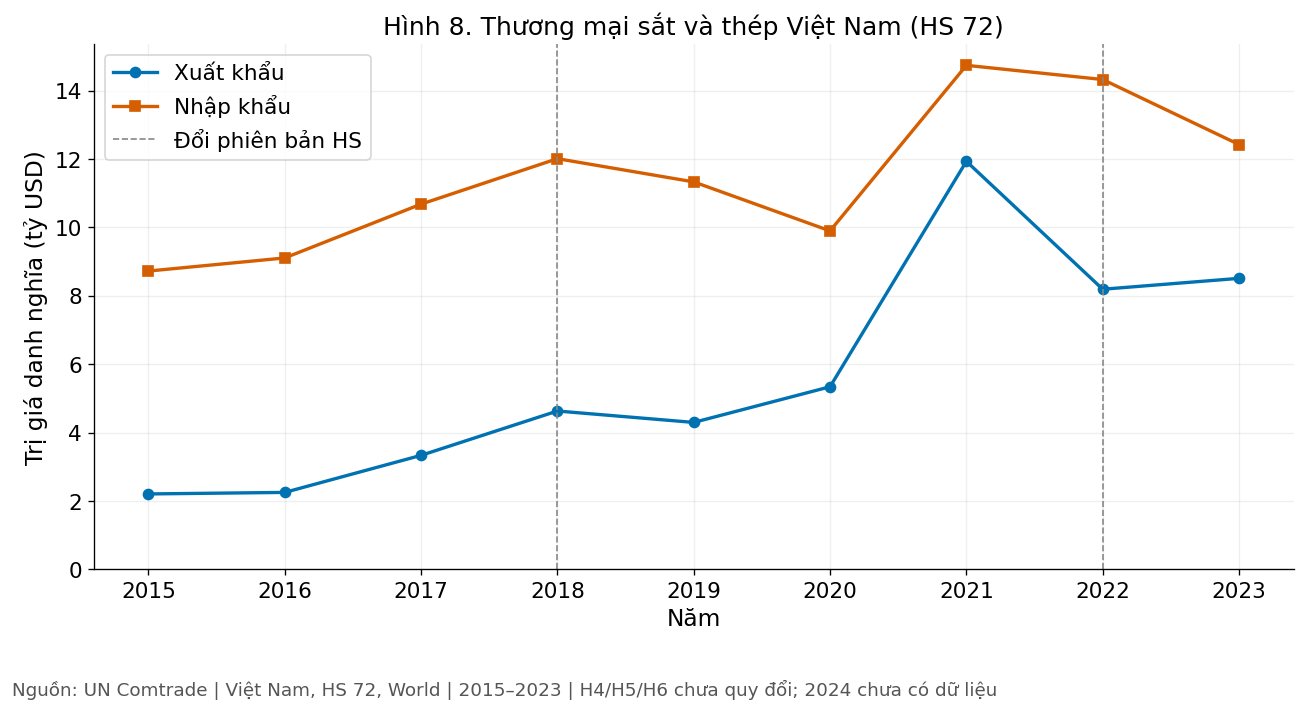

In [96]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(thuong_mai_ve["Year"], thuong_mai_ve["Export_USD"] / 1e9,
        marker="o", linewidth=2, color=MAU_THUONG_MAI["Export"], label="Xuất khẩu")
ax.plot(thuong_mai_ve["Year"], thuong_mai_ve["Import_USD"] / 1e9,
        marker="s", linewidth=2, color=MAU_THUONG_MAI["Import"], label="Nhập khẩu")
for vi_tri, nam in enumerate(nam_doi_hs):
    ax.axvline(nam, color="#888888", linestyle="--", linewidth=1, label="Đổi phiên bản HS" if vi_tri == 0 else None)
ax.set_xticks(thuong_mai_ve["Year"])
ax.set_ylim(bottom=0)
ax.set(title="Hình 8. Thương mại sắt và thép Việt Nam (HS 72)", xlabel="Năm", ylabel="Trị giá danh nghĩa (tỷ USD)")
ax.grid(alpha=0.2)
ax.legend(loc="upper left")
luu_hinh(fig, "08_xuat_nhap_khau", "Q6", "Nguồn: UN Comtrade | Việt Nam, HS 72, World | 2015–2023 | H4/H5/H6 chưa quy đổi; 2024 chưa có dữ liệu")

In [97]:
nam_dinh_xuat = thuong_mai_ve.loc[thuong_mai_ve["Export_USD"].idxmax()]
nam_dinh_nhap = thuong_mai_ve.loc[thuong_mai_ve["Import_USD"].idxmax()]
nam_cuoi_thuong_mai = thuong_mai_ve.iloc[-1]

In [98]:
ghi_nhan_xet("08_xuat_nhap_khau", f"""
**Quan sát:** nhập khẩu lớn hơn xuất khẩu trong các năm có dữ liệu; cả hai luồng đạt trị giá cao nhất vào {int(nam_dinh_xuat['Year'])}.
**Số liệu:** xuất khẩu cực đại {nam_dinh_xuat['Export_USD'] / 1e9:.2f} tỷ USD ({int(nam_dinh_xuat['Year'])}),
nhập khẩu cực đại {nam_dinh_nhap['Import_USD'] / 1e9:.2f} tỷ USD ({int(nam_dinh_nhap['Year'])}).
Năm {int(nam_cuoi_thuong_mai['Year'])}, xuất khẩu {nam_cuoi_thuong_mai['Export_USD'] / 1e9:.2f} tỷ USD
({nam_cuoi_thuong_mai['Export_Growth_Percent']:+.2f}% so với năm trước), nhập khẩu
{nam_cuoi_thuong_mai['Import_USD'] / 1e9:.2f} tỷ USD ({nam_cuoi_thuong_mai['Import_Growth_Percent']:+.2f}%).
**Ý nghĩa:** cung cấp bối cảnh biến động trị giá thương mại của ngành theo năm.
**Giới hạn:** chưa tách tác động giá, lượng hoặc phiên bản HS; không dùng biến động này giải thích lỗi của dữ liệu UCI.
""")

**Quan sát:** nhập khẩu lớn hơn xuất khẩu trong các năm có dữ liệu; cả hai luồng đạt trị giá cao nhất vào 2021.
**Số liệu:** xuất khẩu cực đại 11.94 tỷ USD (2021),
nhập khẩu cực đại 14.74 tỷ USD (2021).
Năm 2023, xuất khẩu 8.51 tỷ USD
(+3.90% so với năm trước), nhập khẩu
12.43 tỷ USD (-13.28%).
**Ý nghĩa:** cung cấp bối cảnh biến động trị giá thương mại của ngành theo năm.
**Giới hạn:** chưa tách tác động giá, lượng hoặc phiên bản HS; không dùng biến động này giải thích lỗi của dữ liệu UCI.

### Hình 9. Chênh lệch xuất nhập khẩu

`Trade_Balance_USD = xuất khẩu − nhập khẩu`. Đường 0 là mốc phân biệt chênh lệch dương/âm.
Giữ một màu trung tính; dấu và chiều của cột biểu diễn thông tin.

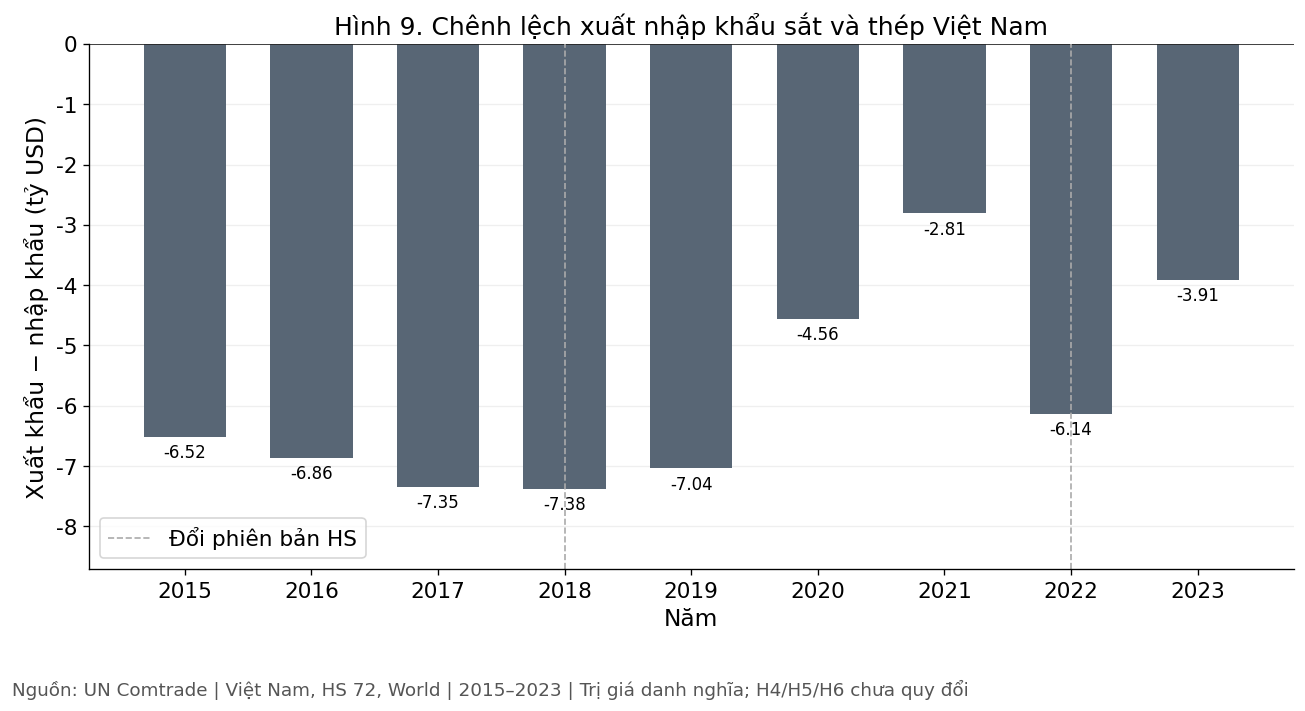

In [99]:
fig, ax = plt.subplots(figsize=(11, 6))
cot = ax.bar(thuong_mai_ve["Year"], thuong_mai_ve["Trade_Balance_USD"] / 1e9,
             color=MAU_THUONG_MAI["Balance"], width=0.65)
ax.bar_label(cot, labels=[f"{gia_tri:.2f}" for gia_tri in thuong_mai_ve["Trade_Balance_USD"] / 1e9], padding=4, fontsize=10)
ax.axhline(0, color="#222222", linewidth=1)
for vi_tri, nam in enumerate(nam_doi_hs):
    ax.axvline(nam, color="#aaaaaa", linestyle="--", linewidth=1, label="Đổi phiên bản HS" if vi_tri == 0 else None)
ax.set_xticks(thuong_mai_ve["Year"])
ax.margins(y=0.18)
ax.set(title="Hình 9. Chênh lệch xuất nhập khẩu sắt và thép Việt Nam", xlabel="Năm", ylabel="Xuất khẩu − nhập khẩu (tỷ USD)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower left")
luu_hinh(fig, "09_chenh_lech_thuong_mai", "Q6", "Nguồn: UN Comtrade | Việt Nam, HS 72, World | 2015–2023 | Trị giá danh nghĩa; H4/H5/H6 chưa quy đổi")

In [100]:
nam_am_nhat = thuong_mai_ve.loc[thuong_mai_ve["Trade_Balance_USD"].idxmin()]
nam_gan_0_nhat = thuong_mai_ve.loc[thuong_mai_ve["Trade_Balance_USD"].abs().idxmin()]
so_nam_chenh_lech_am = int(thuong_mai_ve["Trade_Balance_USD"].lt(0).sum())

In [101]:
ghi_nhan_xet("09_chenh_lech_thuong_mai", f"""
**Quan sát:** chênh lệch âm trong {so_nam_chenh_lech_am}/{len(thuong_mai_ve)} năm có dữ liệu.
**Số liệu:** âm lớn nhất năm {int(nam_am_nhat['Year'])}: {nam_am_nhat['Trade_Balance_USD'] / 1e9:.2f} tỷ USD;
gần 0 nhất năm {int(nam_gan_0_nhat['Year'])}: {nam_gan_0_nhat['Trade_Balance_USD'] / 1e9:.2f} tỷ USD.
Năm {int(nam_cuoi_thuong_mai['Year'])} là {nam_cuoi_thuong_mai['Trade_Balance_USD'] / 1e9:.2f} tỷ USD,
thay đổi {nam_cuoi_thuong_mai['Trade_Balance_Change_USD'] / 1e9:+.2f} tỷ USD so với năm trước.
**Ý nghĩa:** nhập khẩu vượt xuất khẩu trong phạm vi HS 72; mức chênh lệch thay đổi theo năm.
**Giới hạn:** chênh lệch này không phải lợi nhuận ngành hoặc chỉ số chất lượng thép; năm đổi HS cần xem xét phạm vi phân loại.
""")

**Quan sát:** chênh lệch âm trong 9/9 năm có dữ liệu.
**Số liệu:** âm lớn nhất năm 2018: -7.38 tỷ USD;
gần 0 nhất năm 2021: -2.81 tỷ USD.
Năm 2023 là -3.91 tỷ USD,
thay đổi +2.22 tỷ USD so với năm trước.
**Ý nghĩa:** nhập khẩu vượt xuất khẩu trong phạm vi HS 72; mức chênh lệch thay đổi theo năm.
**Giới hạn:** chênh lệch này không phải lợi nhuận ngành hoặc chỉ số chất lượng thép; năm đổi HS cần xem xét phạm vi phân loại.

## 5.7. Trả lời câu hỏi bằng bằng chứng

Bảng tổng hợp gồm Q0–Q6, nối kết quả tự tính với tiêu chí đã ghi ở bước 1.
Mức **A** chỉ xác nhận mô tả trong bộ dữ liệu này, không đồng nghĩa với
khả năng áp dụng cho nhà máy khác, giải thích nguyên nhân hay dự báo lỗi.
Các diễn giải cần bằng chứng bên ngoài được tách sang mục 5.8.

In [102]:
so_o_doi_chieu = len(loi_thep_sach) * len(cot_so)
so_o_lech_uci = int(bang_doi_chieu["So_o_khac_UCI_sau_xu_ly"].sum())
nhan_tap_trung = tap_trung_theo_nhan.loc[tap_trung_theo_nhan["Vuot_moc_PDF"], "Fault_Type_Clean"].tolist()
nhan_tach_iqr = dau_hieu_do_sang.index[dau_hieu_do_sang["IQR_Min_tach_moi_nhan_khac"].astype(bool)].tolist()

Tổng hợp câu trả lời Q0–Q6 từ các bảng và biểu đồ.

In [103]:
ket_qua_cau_hoi = [
    ["Q0", f"{len(loi_thep_sach):,} bản ghi; {so_o_doi_chieu:,} ô đặc trưng có {so_o_lech_uci} lệch UCI; nhãn khớp", "Kiểm tra hoàn thành bước 3; đối chiếu UCI", "Đạt cho phân tích bộ dữ liệu hiện tại; phụ thuộc độ đúng của nguồn và khóa ghép"],
    ["Q1", f"Ba nhãn đầu {ba_nhom_dau['Percent'].sum():.2f}%; cỡ mẫu lớn nhất/nhỏ nhất={ty_so_co_mau:.2f}", "Hình 1–2; co_cau_loi", "Mất cân bằng trong tập lỗi; chưa xếp hạng thiệt hại"],
    ["Q2", f"Vượt mốc {NGUONG_TAP_TRUNG_PHAN_TRAM:.0f}%: {', '.join(nhan_tap_trung)}", "Hình 3–4; tap_trung_theo_nhan", "Tập trung theo dòng thép trong mẫu; thiếu sản lượng và biến vận hành"],
    ["Q3", f"Pearson={pearson_chung:.4f}; IQR Min tách mọi nhãn khác: {', '.join(nhan_tach_iqr) or 'không có'}", "Hình 5; dau_hieu_do_sang", "Dấu hiệu ở 50% trung tâm; chưa xác nhận phân loại trên toàn bộ điểm"],
    ["Q4", f"K_Scatch: trung vị {do_day_theo_nhan.loc['K_Scatch', 'Median']:.0f}, SD {do_day_theo_nhan.loc['K_Scatch', 'Std']:.2f}; {so_ban_ghi_do_day_40_80 / so_ban_ghi * 100:.2f}% toàn tập ở 40–80", "Hình 6; do_day_theo_nhan_thep", "Đọc kèm dòng thép và N; N=1 không so sánh độ phân tán; chưa có đơn vị"],
    ["Q5", f"Trung vị {nhan_trung_vi_lon}={dien_tich_theo_nhan.loc[nhan_trung_vi_lon, 'Median']:,.1f}; {nhan_trung_vi_nho}={dien_tich_theo_nhan.loc[nhan_trung_vi_nho, 'Median']:,.1f}", "Hình 7; thong_ke_dien_tich", "Khác biệt quy mô trong mẫu; diện tích chưa đo mức thiệt hại"],
    ["Q6", f"Xuất−nhập âm {so_nam_chenh_lech_am}/{len(thuong_mai_ve)} năm; năm cuối {nam_cuoi_thuong_mai['Trade_Balance_USD'] / 1e9:.2f} tỷ USD", "Hình 8–9; thuong_mai_theo_nam", "Bối cảnh riêng; trị giá danh nghĩa và phiên bản HS chưa quy đổi"],
]
tong_hop_phat_hien = pd.DataFrame(
    ket_qua_cau_hoi, columns=["Cau_hoi", "Phat_hien", "Bang_chung", "Gioi_han"]
)
tong_hop_phat_hien["Muc_do_chac_chan"] = "A — mô tả kiểm chứng được trong mẫu"
display(tong_hop_phat_hien[["Cau_hoi", "Phat_hien", "Bang_chung", "Gioi_han"]])

,Cau_hoi,Phat_hien,Bang_chung,Gioi_han
0,Q0,"1,941 bản ghi; 52,407 ô đặc trưng có 0 lệch UC...",Kiểm tra hoàn thành bước 3; đối chiếu UCI,Đạt cho phân tích bộ dữ liệu hiện tại; phụ thu...
1,Q1,Ba nhãn đầu 75.53%; cỡ mẫu lớn nhất/nhỏ nhất=1...,Hình 1–2; co_cau_loi,Mất cân bằng trong tập lỗi; chưa xếp hạng thiệ...
2,Q2,"Vượt mốc 90%: K_Scatch, Z_Scratch, Stains",Hình 3–4; tap_trung_theo_nhan,Tập trung theo dòng thép trong mẫu; thiếu sản ...
3,Q3,Pearson=0.4296; IQR Min tách mọi nhãn khác: K_...,Hình 5; dau_hieu_do_sang,Dấu hiệu ở 50% trung tâm; chưa xác nhận phân l...
4,Q4,"K_Scatch: trung vị 40, SD 2.20; 76.30% toàn tậ...",Hình 6; do_day_theo_nhan_thep,Đọc kèm dòng thép và N; N=1 không so sánh độ p...
5,Q5,"Trung vị K_Scatch=6,281.0; Stains=16.5",Hình 7; thong_ke_dien_tich,Khác biệt quy mô trong mẫu; diện tích chưa đo ...
6,Q6,Xuất−nhập âm 9/9 năm; năm cuối -3.91 tỷ USD,Hình 8–9; thuong_mai_theo_nam,Bối cảnh riêng; trị giá danh nghĩa và phiên bả...


## 5.8. Mức độ chắc chắn và ưu tiên kiểm chứng

Theo PDF IX (trang 47–48), phân biệt:

- **A — mô tả kiểm chứng được:** bảng 5.7, đối chiếu lại bằng chính dữ liệu và mã.
- **B — nhận định khám phá:** hướng giải thích hoặc sử dụng cần bằng chứng bên ngoài.
- **C — chưa thể kết luận:** thiếu biến, mẫu số hoặc định nghĩa cần thiết.

Xếp ưu tiên dưới đây theo việc cần làm để bổ sung bằng chứng,
không theo mức độ nghiêm trọng hay thiệt hại của lỗi.

In [104]:
nhan_dinh_va_gioi_han = pd.DataFrame([
    ["B", "Min thấp có thể hỗ trợ nhận diện K_Scatch", "IQR tách chỉ là dấu hiệu; cần tập kiểm tra độc lập và precision/recall"],
    ["B", "K_Scatch cần kiểm chứng ở tổ hợp A400–độ dày 40", "Dòng thép và độ dày cùng tập trung; chưa tách được yếu tố nào đi kèm"],
    ["B", "Other_Faults có thể chứa những nhóm con khác nhau", "Cần ảnh lỗi, định nghĩa QC và kiểm chứng nhóm con trên dữ liệu mới"],
    ["C", "Tỷ lệ sản phẩm bị lỗi hoặc dòng thép nào dễ lỗi hơn", "Thiếu tổng sản lượng theo dòng thép và độ dày"],
    ["C", "Nguyên nhân vật lý hoặc thiết bị gây lỗi", "Thiếu mã tấm/cuộn, thiết bị, ca và biến vận hành; cần xác nhận hiện trường"],
    ["C", "Loại lỗi gây thiệt hại nghiêm trọng nhất", "Thiếu chi phí, mức hạ cấp và định nghĩa mức độ nghiêm trọng"],
    ["C", "Xu hướng lỗi theo thời gian sản xuất", "Production_Date là ngày mô phỏng"],
    ["C", "Độ dày có đơn vị mm; thương mại Việt Nam giải thích lỗi UCI", "Nguồn chưa xác nhận đơn vị hoặc quan hệ giữa hai tập dữ liệu"],
], columns=["Muc", "Nhan_dinh_hoac_cau_hoi", "Bang_chung_con_thieu"])
display(nhan_dinh_va_gioi_han)

,Muc,Nhan_dinh_hoac_cau_hoi,Bang_chung_con_thieu
0,B,Min thấp có thể hỗ trợ nhận diện K_Scatch,IQR tách chỉ là dấu hiệu; cần tập kiểm tra độc...
1,B,K_Scatch cần kiểm chứng ở tổ hợp A400–độ dày 40,Dòng thép và độ dày cùng tập trung; chưa tách ...
2,B,Other_Faults có thể chứa những nhóm con khác nhau,"Cần ảnh lỗi, định nghĩa QC và kiểm chứng nhóm ..."
3,C,Tỷ lệ sản phẩm bị lỗi hoặc dòng thép nào dễ lỗ...,Thiếu tổng sản lượng theo dòng thép và độ dày
4,C,Nguyên nhân vật lý hoặc thiết bị gây lỗi,"Thiếu mã tấm/cuộn, thiết bị, ca và biến vận hà..."
5,C,Loại lỗi gây thiệt hại nghiêm trọng nhất,"Thiếu chi phí, mức hạ cấp và định nghĩa mức độ..."
6,C,Xu hướng lỗi theo thời gian sản xuất,Production_Date là ngày mô phỏng
7,C,Độ dày có đơn vị mm; thương mại Việt Nam giải ...,Nguồn chưa xác nhận đơn vị hoặc quan hệ giữa h...


### Kế hoạch kiểm chứng theo PDF X

Các mốc thời gian là đề xuất từ PDF, chưa phải lịch triển khai được xác nhận.
Giai đoạn dự báo chỉ bắt đầu sau khi có nền dữ liệu và dữ liệu bổ sung phù hợp.

In [105]:
ke_hoach_kiem_chung = pd.DataFrame([
    ["1 — nền dữ liệu (0–30 ngày)", "Q0, Q1–Q5", "Lưu hồ sơ nguồn, mã ghép, nhật ký và bảng đối chiếu; xác nhận đơn vị, định nghĩa nhãn",
     "File nguồn có hash; nhật ký giá trị cũ/mới; metadata và định nghĩa QC",
     "Người khác chạy lại ra 0 ô lệch; mỗi thay đổi truy được căn cứ; điểm chưa xác nhận ghi rõ"],
    ["2 — hiện trường (1–3 tháng)", "Q2, Q4", "Ưu tiên kiểm chứng khuôn K_Scatch trên A400 ở độ dày 40; thu thập mẫu số sản lượng",
     "Sản lượng theo dòng/độ dày; mã tấm/cuộn, thiết bị, ca; tốc độ, nhiệt độ, tuổi con lăn; ngày thật",
     "Có đối chiếu hiện trường bằng dữ liệu và đủ mẫu số; chưa đưa ra điều chỉnh vật lý khi thiếu bằng chứng"],
    ["2 — nhãn lỗi (1–3 tháng)", "Q1, Q3, Q5", "Cùng QC kiểm tra tính không đồng nhất của Other_Faults và hướng tách nhóm con",
     "Ảnh lỗi; định nghĩa nhãn; bản ghi nhóm Min > 120 và nhóm đối chiếu",
     "QC xác nhận định nghĩa, nhãn mới và ví dụ minh họa; kiểm tra nhất quán giữa người gán nhãn"],
    ["3 — dự báo (3–6 tháng; có điều kiện)", "Q3", "Tách tập kiểm tra độc lập trước chọn ngưỡng; đánh giá quy tắc hoặc mô hình nếu dữ liệu cho phép",
     "Dữ liệu mới, mã tấm/cuộn để tránh rò rỉ giữa tập; nhãn được QC xác nhận",
     "Báo precision/recall trên tập chưa chọn ngưỡng; nếu đa lớp, thêm F1 từng lớp/macro và cỡ mẫu"],
    ["Bổ sung — thương mại", "Q6", "Đối chiếu phiên bản HS trước khi giải thích biến động và bổ sung giá/khối lượng nếu có",
     "Bảng quy đổi HS, tài liệu phạm vi, dữ liệu lượng/giá có nguồn",
     "Chuỗi so sánh có phạm vi nhất quán hoặc giới hạn ghi rõ; chỉ kết luận ở cấp ngành"],
], columns=["Giai_doan", "Cau_hoi_lien_quan", "Viec_can_lam", "Du_lieu_can_bo_sung", "Dieu_kien_hoan_tat"])

display(ke_hoach_kiem_chung)

,Giai_doan,Cau_hoi_lien_quan,Viec_can_lam,Du_lieu_can_bo_sung,Dieu_kien_hoan_tat
0,1 — nền dữ liệu (0–30 ngày),"Q0, Q1–Q5","Lưu hồ sơ nguồn, mã ghép, nhật ký và bảng đối ...",File nguồn có hash; nhật ký giá trị cũ/mới; me...,Người khác chạy lại ra 0 ô lệch; mỗi thay đổi ...
1,2 — hiện trường (1–3 tháng),"Q2, Q4",Ưu tiên kiểm chứng khuôn K_Scatch trên A400 ở ...,"Sản lượng theo dòng/độ dày; mã tấm/cuộn, thiết...",Có đối chiếu hiện trường bằng dữ liệu và đủ mẫ...
2,2 — nhãn lỗi (1–3 tháng),"Q1, Q3, Q5",Cùng QC kiểm tra tính không đồng nhất của Othe...,Ảnh lỗi; định nghĩa nhãn; bản ghi nhóm Min > 1...,"QC xác nhận định nghĩa, nhãn mới và ví dụ minh..."
3,3 — dự báo (3–6 tháng; có điều kiện),Q3,Tách tập kiểm tra độc lập trước chọn ngưỡng; đ...,"Dữ liệu mới, mã tấm/cuộn để tránh rò rỉ giữa t...",Báo precision/recall trên tập chưa chọn ngưỡng...
4,Bổ sung — thương mại,Q6,Đối chiếu phiên bản HS trước khi giải thích bi...,"Bảng quy đổi HS, tài liệu phạm vi, dữ liệu lượ...",Chuỗi so sánh có phạm vi nhất quán hoặc giới h...


### Kết luận phân tích và điều kiện sử dụng

Kết quả bước 5 xác nhận cơ cấu nhãn mất cân bằng, một số nhãn tập trung trên một dòng thép,
và K_Scatch có khuôn hẹp về độ sáng tối thiểu, dòng thép, độ dày và diện tích.
Những mô tả này giúp lựa chọn tổ hợp cần kiểm chứng và đặc trưng cần khảo sát.
Other_Faults cần được đọc như một nhóm gộp; các ô ít mẫu phải giữ cảnh báo cỡ mẫu.
Thương mại HS 72 cung cấp bối cảnh ngành ở phạm vi riêng.

Ưu tiên gần nhất là giữ hồ sơ phân tích chạy lại được, xác nhận định nghĩa/đơn vị,
bổ sung sản lượng và kiểm chứng tại hiện trường. Chỉ đề xuất can thiệp thiết bị khi có
biến vận hành liên quan, xác nhận hiện trường và phép đo trước–sau trên chỉ tiêu thích hợp.
Các biểu đồ hiện tại phục vụ theo dõi phân bố và khám phá, chưa đánh giá rủi ro sản phẩm.

## 5.9. Kiểm tra và lưu sản phẩm

Kiểm tra đủ hình, Q0–Q6 có bằng chứng, tiêu chí Q2 dùng đúng tỷ trọng trong nhãn,
cỡ mẫu và mẫu số hợp lệ, kết quả đối chiếu UCI đạt, bảng B/C và kế hoạch kiểm chứng đầy đủ.
Các hình PNG được mở để kiểm tra tiêu đề, chú giải và khả năng đọc.

In [106]:
kiem_tra_buoc_5 = pd.DataFrame([
    ["Đủ 9 hình và 9 nhận xét", len(danh_muc_hinh) == len(nhan_xet_cac_hinh) == 9],
    ["Q0–Q6 có bằng chứng và tiêu chí", set(tong_hop_phat_hien["Cau_hoi"]) == set(tieu_chi_cau_hoi["Cau_hoi"]) == {f"Q{i}" for i in range(7)}],
    ["Q0 khớp nguồn và kiểm tra chất lượng đạt", so_o_lech_uci == 0 and kiem_tra_hoan_thanh["Dat"].all()],
    ["Q2 dùng đúng mẫu số trong nhãn", np.allclose(ty_trong_theo_nhan, bang_dem_thep.reindex(ty_trong_theo_nhan.index).div(co_mau_loi.reindex(ty_trong_theo_nhan.index), axis=0) * 100)],
    ["Q2 áp dụng đúng mốc tham khảo PDF", tap_trung_theo_nhan["Vuot_moc_PDF"].equals(tap_trung_theo_nhan["Ty_trong_trong_nhan"].gt(NGUONG_TAP_TRUNG_PHAN_TRAM))],
    ["Có nhận định B/C và điều kiện kiểm chứng", set(nhan_dinh_va_gioi_han["Muc"]) == {"B", "C"} and ke_hoach_kiem_chung["Dieu_kien_hoan_tat"].str.len().gt(0).all()],
    ["Tổng số đếm biểu đồ dòng thép khớp", bang_dem_thep.to_numpy().sum() == so_ban_ghi],
    ["Tỷ trọng mỗi dòng thép bằng 100%", np.allclose(bang_ty_trong_thep.sum(axis=1), 100)],
    ["Tổng cỡ mẫu bảng độ dày theo nhãn/thép khớp", do_day_theo_nhan_thep["N"].sum() == so_ban_ghi],
    ["Pearson hữu hạn và trong [-1,1]", np.isfinite(tuong_quan_do_sang["Pearson_r"]).all() and tuong_quan_do_sang["Pearson_r"].between(-1, 1).all()],
    ["Diện tích dương để dùng trục log", loi_thep_phan_tich["Pixels_Areas"].gt(0).all()],
    ["Dữ liệu thương mại bước 4 giữ nguyên", thuong_mai_ve.equals(thuong_mai_phan_tich)],
    ["PNG và SVG đã lưu đầy đủ", all((BAO_CAO_5 / dong[dinh_dang]).is_file() for dong in danh_muc_hinh for dinh_dang in ["PNG", "SVG"])],
], columns=["Dieu_kien", "Dat"])
assert kiem_tra_buoc_5["Dat"].all()
display(kiem_tra_buoc_5)

,Dieu_kien,Dat
0,Đủ 9 hình và 9 nhận xét,True
1,Q0–Q6 có bằng chứng và tiêu chí,True
2,Q0 khớp nguồn và kiểm tra chất lượng đạt,True
3,Q2 dùng đúng mẫu số trong nhãn,True
4,Q2 áp dụng đúng mốc tham khảo PDF,True
5,Có nhận định B/C và điều kiện kiểm chứng,True
6,Tổng số đếm biểu đồ dòng thép khớp,True
7,Tỷ trọng mỗi dòng thép bằng 100%,True
8,Tổng cỡ mẫu bảng độ dày theo nhãn/thép khớp,True
9,"Pearson hữu hạn và trong [-1,1]",True


### Lưu bảng số liệu và nhận xét

Bảng hỗ trợ giữ độ chính xác đầy đủ; làm tròn chỉ trong hiển thị.
Tệp nhận xét Markdown có thể dùng làm nền viết Chương 5.

Lưu các bảng số liệu CSV.

In [107]:
cac_bang_buoc_5 = {
    "co_cau_loi": co_cau_loi, "loi_theo_dong_thep": loi_theo_thep,
    "tuong_quan_do_sang": tuong_quan_do_sang, "thong_ke_do_sang": thong_ke_do_sang,
    "thong_ke_do_day": thong_ke_do_day, "do_day_theo_nhan_thep": do_day_theo_nhan_thep,
    "thong_ke_dien_tich": thong_ke_dien_tich, "co_dien_tich_theo_nhan": co_dien_tich_theo_nhan,
    "thuong_mai_theo_nam": thuong_mai_ve, "tong_hop_phat_hien": tong_hop_phat_hien,
    "tap_trung_theo_nhan": tap_trung_theo_nhan, "dau_hieu_do_sang": dau_hieu_do_sang.reset_index(),
    "do_sang_vung": do_sang_vung, "tieu_chi_cau_hoi": tieu_chi_cau_hoi,
    "nhan_dinh_va_gioi_han": nhan_dinh_va_gioi_han, "ke_hoach_kiem_chung": ke_hoach_kiem_chung,
    "danh_muc_hinh": pd.DataFrame(danh_muc_hinh), "kiem_tra_hoan_thanh": kiem_tra_buoc_5,
}
for ten, bang in cac_bang_buoc_5.items():
    bang.to_csv(BAO_CAO_5 / f"{ten}.csv", index=False, encoding="utf-8-sig")

Tổng hợp nhận xét và bảng thành Markdown.

In [108]:
noi_dung_nhan_xet = "# Nhận xét Chương 5\n\nNguồn: notebook bước 1–5, số liệu tự tính từ bảng sạch.\n\n"
for dong in nhan_xet_cac_hinh:
    noi_dung_nhan_xet += f"## {dong['Hinh']}\n\n{dong['Nhan_xet']}\n\n"
for tieu_de, bang in [
    ("Trả lời Q0–Q6", tong_hop_phat_hien),
    ("Tiêu chí đánh giá", tieu_chi_cau_hoi),
    ("Nhận định khám phá và giới hạn", nhan_dinh_va_gioi_han),
    ("Kế hoạch kiểm chứng", ke_hoach_kiem_chung),
]:
    noi_dung_nhan_xet += f"## {tieu_de}\n\n"
    # Xuất bảng Markdown trực tiếp để không cần thêm thư viện.
    noi_dung_nhan_xet += "| " + " | ".join(bang.columns) + " |\n"
    noi_dung_nhan_xet += "| " + " | ".join(["---"] * len(bang.columns)) + " |\n"
    for dong in bang.itertuples(index=False, name=None):
        noi_dung_nhan_xet += "| " + " | ".join(str(o).replace("|", "/").replace("\n", " ") for o in dong) + " |\n"
    noi_dung_nhan_xet += "\n"

Bổ sung kết luận và lưu file nhận xét.

In [109]:
noi_dung_nhan_xet += "## Kết luận phân tích\n\n"
noi_dung_nhan_xet += "Mức A xác nhận mô tả trong mẫu; mức B cần bằng chứng bên ngoài; mức C chưa đủ dữ liệu để kết luận. "
noi_dung_nhan_xet += "Ưu tiên giữ hồ sơ chạy lại, xác nhận định nghĩa/đơn vị, thu thập sản lượng và kiểm chứng hiện trường. "
noi_dung_nhan_xet += "Dự báo chỉ đánh giá trên tập độc lập; thương mại là bối cảnh riêng. Các công việc này là đề xuất, chưa thực hiện.\n"
(BAO_CAO_5 / "nhan_xet_chuong_5.md").write_text(noi_dung_nhan_xet, encoding="utf-8")
print("Hình PNG/SVG:", THU_MUC_HINH)
print("Bảng hỗ trợ và nhận xét:", BAO_CAO_5)

Hình PNG/SVG: D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\outputs\buoc_5\hinh
Bảng hỗ trợ và nhận xét: D:\PTIT\KÌ 1 năm 4\Trực quan hóa dữ liệu\Baocao\tmp\pdfs\notebook-hinh-sach-run\outputs\buoc_5


## Kết quả bước 5 và bàn giao cho bước 6

Đã tạo 9 hình với tiêu đề, trục, phạm vi, cỡ mẫu và nhận xét từ số liệu tự tính.
Q0–Q6 có bảng trả lời và giới hạn. Q2 đối chiếu mốc 90% trong nhãn;
Q3 đánh giá dấu hiệu ở IQR và scatter; Q4 giữ bảng nhãn × dòng thép với cảnh báo N=1.
Mục 5.8 phân biệt mô tả A, khám phá B, nội dung chưa thể kết luận C và kế hoạch kiểm chứng.

Sản phẩm ở `outputs/buoc_5/`: 9 PNG/SVG trong `hinh/`, các bảng CSV,
`nhan_xet_chuong_5.md` chứa nhận xét, kết quả Q0–Q6 và việc cần làm tiếp theo.
Kế hoạch kiểm chứng là đề xuất; chưa thu thập thêm sản lượng, kiểm chứng hiện trường
hay đánh giá mô hình trên tập độc lập trong notebook này.

Bước 6 dùng các phép tổng hợp để hiển thị tương tác theo bộ lọc.
Khi lọc, phải tính lại mẫu số và cỡ mẫu, đồng thời giữ cảnh báo nhóm ít mẫu,
ngày mô phỏng, đơn vị chưa xác nhận và giới hạn của thương mại.

---
# Chương 6. Dashboard tự động

## 6.1. Mục tiêu và người sử dụng

Dashboard dùng để khám phá cơ cấu và đặc trưng của các bản ghi lỗi trong UCI,
phù hợp người đọc báo cáo muốn thay bộ lọc để kiểm tra các nhận xét ở Chương 5.
Theo mục 6 của kế hoạch, dùng Streamlit và Plotly. Tham khảo tổ chức màn hình
và bộ lọc của PDF mục VIII (trang 45–46), chuyển thành ba tab theo phạm vi đã chốt.

| Tab | Nội dung |
|---|---|
| Phân tích lỗi thép | 4 KPI, bộ lọc dòng thép/nhãn/độ dày, 7 biểu đồ và bảng hỗ trợ |
| Bối cảnh ngành | Khoảng năm, KPI theo năm, 2 biểu đồ thương mại, thời điểm lấy và năm thiếu |
| Dữ liệu và chất lượng | Nguồn, kết quả làm sạch/đối chiếu, bảng đang lọc và tải CSV |

## 6.2. Kiến trúc xử lý dữ liệu

`app.py` quản lý giao diện và trạng thái. `steel_analysis.py` thực hiện
**đọc nguồn → kiểm tra → làm sạch → tạo biến → lọc → tổng hợp/KPI**.
`dashboard_charts.py` dựng Plotly từ các kết quả đó.

Chương 6 gọi chính module dùng trong dashboard. Chương 3–5 giữ các ô mã chi tiết;
phần đối chiếu dưới đây kiểm tra module cho cùng kết quả với các bước đã chạy.
Đối chiếu dùng bộ JSON gốc ở `data/raw/`; bộ API mới được lưu riêng tại `outputs/buoc_6/runtime/`.

In [110]:
import steel_analysis as xu_ly

BAO_CAO_6 = THU_MUC_DU_AN / "outputs" / "buoc_6"
BAO_CAO_6.mkdir(parents=True, exist_ok=True)
goi_json_goc = xu_ly.read_trade_pack(THU_MUC_DU_AN, prefer_cached=False)
ban_dashboard = xu_ly.load_snapshot(THU_MUC_DU_AN, trade_pack=goi_json_goc)

print("Bảng lỗi dashboard:", ban_dashboard.faults.shape)
print("Bảng thương mại dashboard:", ban_dashboard.trade.shape)
display(pd.DataFrame(ban_dashboard.quality.items(), columns=["Chỉ tiêu", "Kết quả"]))

Bảng lỗi dashboard: (1941, 41)
Bảng thương mại dashboard: (9, 17)


,Chỉ tiêu,Kết quả
0,input_rows,1961
1,input_columns,29
2,clean_rows,1941
3,duplicates_removed,20
4,missing_restored,67
5,numeric_corrected,16
6,unmatched_rows,0
7,feature_mismatches,0
8,labels_match,True
9,area_flags_retained,395


### Đối chiếu cùng đầu vào với notebook bước 3–5

Kiểm tra từng cột dữ liệu và các bảng tổng hợp; bỏ khác biệt kiểu số nguyên nullable
với số thực khi chúng biểu diễn cùng giá trị. Mã quốc gia/đối tác/hàng hóa được chuyển
về chuỗi ở cả hai bảng để cùng cách biểu diễn mã. Không bỏ qua khác biệt giá trị.

In [111]:
pd.testing.assert_frame_equal(ban_dashboard.faults, loi_thep_phan_tich, check_dtype=False)
thuong_mai_dashboard_doi_chieu = ban_dashboard.trade.copy()
thuong_mai_notebook_doi_chieu = thuong_mai_phan_tich.copy()
for cot in ["reporterCode", "partnerCode", "cmdCode"]:
    thuong_mai_dashboard_doi_chieu[cot] = thuong_mai_dashboard_doi_chieu[cot].astype(str)
    thuong_mai_notebook_doi_chieu[cot] = thuong_mai_notebook_doi_chieu[cot].astype(str)
pd.testing.assert_frame_equal(thuong_mai_dashboard_doi_chieu, thuong_mai_notebook_doi_chieu, check_dtype=False)
pd.testing.assert_frame_equal(xu_ly.fault_structure(ban_dashboard.faults), co_cau_loi, check_dtype=False)
pd.testing.assert_frame_equal(xu_ly.fault_by_steel(ban_dashboard.faults), loi_theo_thep, check_dtype=False)
pd.testing.assert_frame_equal(xu_ly.feature_summary(ban_dashboard.faults), dac_trung_theo_nhan, check_dtype=False)

doi_chieu_dashboard = pd.DataFrame([
    ["Bảng lỗi và 5 biến mới", True], ["Bảng thương mại và chỉ số", True],
    ["Cơ cấu lỗi", True], ["Hai mẫu số tỷ trọng theo dòng thép/nhãn", True],
    ["Thống kê 4 đặc trưng theo nhãn", True],
], columns=["Noi_dung", "Khop_notebook"])
display(doi_chieu_dashboard)
doi_chieu_dashboard.to_csv(BAO_CAO_6 / "doi_chieu_notebook_dashboard.csv", index=False, encoding="utf-8-sig")

,Noi_dung,Khop_notebook
0,Bảng lỗi và 5 biến mới,True
1,Bảng thương mại và chỉ số,True
2,Cơ cấu lỗi,True
3,Hai mẫu số tỷ trọng theo dòng thép/nhãn,True
4,Thống kê 4 đặc trưng theo nhãn,True


## 6.3. Giao diện, bộ lọc và KPI

Chọn dòng thép, nhãn và khoảng độ dày trong tab lỗi; nút đặt lại trả về toàn bộ mẫu.
Không chọn nhãn/dòng thép nào cho tập rỗng, có thông báo và KPI trung vị để trống.
Mọi biểu đồ lỗi và bảng tải xuống dùng chung tập đang lọc.

Tab thương mại có bộ lọc năm độc lập. KPI mặc định dùng năm gần nhất có đủ hai luồng,
nhưng vẫn cho chọn năm thiếu để thấy trạng thái “Chưa có dữ liệu”. Biểu đồ giữ năm thiếu,
không nối đường qua khoảng thiếu. Hai bộ lọc không tác động chéo lên dữ liệu.

### Ví dụ kiểm tra tập được chọn và KPI

In [112]:
cac_tap_kiem_tra = {
    "Toàn bộ": ban_dashboard.faults,
    "A300": xu_ly.filter_faults(ban_dashboard.faults, ["A300"], list(xu_ly.COLORS), (40, 300)),
    "A400 + K_Scatch": xu_ly.filter_faults(ban_dashboard.faults, ["A400"], ["K_Scatch"], (40, 300)),
    "Không chọn nhãn": xu_ly.filter_faults(ban_dashboard.faults, ["A300", "A400"], [], (40, 300)),
}
bang_kpi_kiem_tra = pd.DataFrame([
    {"Pham_vi": ten, **xu_ly.fault_kpis(bang)} for ten, bang in cac_tap_kiem_tra.items()
])
assert bang_kpi_kiem_tra["N"].tolist() == [1941, 777, 390, 0]
display(bang_kpi_kiem_tra)
bang_kpi_kiem_tra.to_csv(BAO_CAO_6 / "kpi_theo_bo_loc.csv", index=False, encoding="utf-8-sig")

,Pham_vi,N,Labels,Median_Area,Median_Thickness
0,Toàn bộ,1941,7,174.0,70.0
1,A300,777,7,113.0,70.0
2,A400 + K_Scatch,390,1,6281.5,40.0
3,Không chọn nhãn,0,0,NaN,NaN


## 6.4. Biểu đồ và thông tin chất lượng

7 hình lỗi tương ứng Hình 1–7, hai hình thương mại tương ứng Hình 8–9 của Chương 5.
Giữ cùng màu nhãn; tính tỷ trọng trong phạm vi đang chọn và ghi rõ mẫu số.
Boxplot dùng tứ phân vị tuyến tính giống Pandas, tính trên thang gốc rồi đổi trục log
cho diện tích; điểm ngoài râu từng nhóm vẫn được hiển thị.

Tab chất lượng ghi số dòng đầu vào/sau làm sạch, trùng, ô thiếu khôi phục, giá trị sửa,
đối chiếu nguồn và số dòng chưa ghép. Nguồn có mã băm và trạng thái từng truy vấn.
Giữ giới hạn về thiếu sản lượng/biến vận hành/đơn vị; ngày là mô phỏng.

## 6.5. Cơ chế cập nhật

- Nút làm mới đọc lại file nguồn và chạy pipeline; chưa qua kiểm tra thì giữ bản cũ.
- `st.fragment(run_every="5m")` tự đọc lại mỗi 5 phút khi phiên hoạt động và tùy chọn bật.
- Mặc định không gọi mạng; khi bật gọi UN Comtrade, thu lại 20 truy vấn cho 2015–2024.
- API có cache 15 phút cho tự động; nút làm mới xóa cache để gọi trực tiếp.
- JSON API mới chỉ được lưu sau khi kiểm tra đủ phạm vi/trạng thái/giá trị.
- Bản hợp lệ gần nhất được lưu để có thể dùng lại cả sau khi khởi động ứng dụng.
- Thời điểm kiểm tra file và thời điểm lấy API được hiển thị riêng, không giả lập lần gọi mới.

`outputs/buoc_6/runtime/` chứa trạng thái dashboard; không ghi đè dữ liệu thô hoặc báo cáo bước 1–5.
UCI là dữ liệu tĩnh; tính năng cập nhật minh họa đọc lại nguồn, không tự sinh thêm bản ghi.

## 6.6. Kiểm tra ứng dụng

11 kiểm thử ở `tests/test_dashboard.py` kiểm tra pipeline và UI qua Streamlit AppTest.
Lỗi API và chu kỳ tự động được mô phỏng; thao tác thay file dùng bản sao riêng.
Không cần gọi API thật để kiểm tra nhánh mất mạng.

In [113]:
file_ket_qua_test = BAO_CAO_6 / "test_results.json"
if file_ket_qua_test.exists():
    ket_qua_test = json.loads(file_ket_qua_test.read_text(encoding="utf-8"))
    display(pd.DataFrame(ket_qua_test.items(), columns=["Kiểm tra", "Kết quả"]))
    assert ket_qua_test["status"] == "passed"
else:
    print("Chạy: python -m unittest discover -s tests -v")

,Kiểm tra,Kết quả
0,tests_run,11
1,failures,0
2,errors,0
3,skipped,0
4,status,passed
5,api_error_checks,simulated; no live API calls
6,source_reload_check,modified a separate temporary workbook; origin...
7,auto_refresh_check,simulated an elapsed interval; verified source...
8,run_at,2026-10-12T21:53:19+07:00
9,elapsed_seconds,49.75


**Giới hạn kiểm tra giao diện:** ứng dụng chạy qua AppTest và trả HTTP 200 tại máy cục bộ.
Công cụ trình duyệt/điều khiển máy tính của phiên làm việc không kết nối được,
nên chưa kiểm tra trực quan và chưa có ảnh chụp dashboard thực tế.
Mở ứng dụng để kiểm tra bố cục và chụp riêng ba tab khi hoàn thiện tiểu luận.

## 6.7. Hướng dẫn chạy và bàn giao

Tại thư mục dự án:

```powershell
python -m pip install -r requirements.txt
python -m streamlit run app.py --server.address 127.0.0.1 --browser.gatherUsageStats false
```

Mở `http://localhost:8501`; nếu cổng đang được dùng, thêm `--server.port 8502`.
Chạy kiểm thử bằng `python -m unittest discover -s tests -v`.
Không chạy lệnh mở server trực tiếp trong ô notebook vì server cần tiến trình chạy liên tục.

Mã nguồn: `app.py`, `steel_analysis.py`, `dashboard_charts.py`.
Hướng dẫn chi tiết: `HUONG_DAN_DASHBOARD.md`. Bằng chứng đối chiếu và kiểm thử:
`outputs/buoc_6/`. Notebook đã triển khai nội dung sáu bước; phần còn lại để hoàn thiện
báo cáo là kiểm tra trực quan/chụp ảnh dashboard và dàn trang tiểu luận.

## Tài liệu tham khảo

1. Kế hoạch triển khai: `ke-hoach-bai-tap-lon-truc-quan-hoa-loi-thep.md` trong thư mục dự án.
2. Báo cáo nền: `[Reading]-Data-Analytics-in-Manufacturing.pdf`, mục I–V (trang 4–20), làm sạch dữ liệu (trang 21–33),
   từ điển dữ liệu (trang 15–16), phân tích VII.1–VII.3 (trang 34–44), nhận định IX và khuyến nghị X (trang 47–50), nguồn và phiên bản (trang 51).
   [Thư mục tài liệu kèm theo](https://drive.google.com/drive/folders/1IpAVZb8KNwpU70SmD1EIYvCwqX6MM4N4).
3. Buscema, M., Terzi, S., & Tastle, W. (2010). *Steel Plates Faults*.
   [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/198/steel+plates+faults),
   DOI [10.24432/C5J88N](https://doi.org/10.24432/C5J88N), giấy phép CC BY 4.0.
   [Metadata API](https://archive.ics.uci.edu/api/dataset?id=198).
4. United Nations Statistics Division.
   [UN Comtrade API](https://uncomtrade.org/docs/un-comtrade-api/),
   [Trade valuation](https://uncomtrade.org/docs/trade-valuation/).

Các số liệu kết quả thu thập được lấy từ mã đã chạy; không sao chép kết luận phân tích
của báo cáo mẫu. Thời điểm lấy của từng nguồn nằm trong metadata và hồ sơ nguồn.

5. [Streamlit fragment](https://docs.streamlit.io/develop/api-reference/execution-flow/st.fragment),
   [Streamlit AppTest](https://docs.streamlit.io/develop/api-reference/app-testing/st.testing.v1.apptest),
   [Plotly box plots](https://plotly.com/python/box-plots/).
   Bố cục và bộ lọc dashboard tham khảo PDF mục VIII (trang 45–46).
